# Wairau High-Water-Risk Classification

This notebook reconstructs and validates the Wairau hourly dataset, defines a 24-hour high-water-risk target, engineers hydrological features, and compares Random Forest and XGBoost classifiers using chronological training, validation, and test periods.

## 1. Data Loading and Station Audit

In [1]:
# 1. WAIRAU NOTEBOOK SETUP AND SOURCE-FILE REGISTRATION
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 180)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

sns.set_theme(style="whitegrid")

# Study-period configuration
STUDY_START = pd.Timestamp("2015-01-01 01:00:00")
STUDY_END = pd.Timestamp("2026-01-01 00:00:00")

WAIRAU_HOURLY_INDEX = pd.date_range(
    start=STUDY_START,
    end=STUDY_END,
    freq="h"
)

EXPECTED_HOURLY_ROWS = len(WAIRAU_HOURLY_INDEX)

# Source-file locations
# Change only DATA_DIRECTORY if the files are moved
DATA_DIRECTORY = Path(r"C:\Users\kgeet\Downloads")

WAIRAU_SOURCE_FILES = {
    "rainfall_primary_647722":
        DATA_DIRECTORY / "647722.csv",

    "rainfall_support_647737":
        DATA_DIRECTORY / "647737.csv",

    "rainfall_support_647738":
        DATA_DIRECTORY / "647738.csv",

    "discharge_primary_7604":
        DATA_DIRECTORY / "7604(1).csv",

    "discharge_support_7607":
        DATA_DIRECTORY / "7607(1).csv",

    "water_level_primary_7604":
        DATA_DIRECTORY / "7604(2).csv",

    "water_level_support_7607":
        DATA_DIRECTORY / "7607(2).csv"
}

# Verify that all seven required files exist
wairau_file_check = pd.DataFrame({
    "dataset": list(WAIRAU_SOURCE_FILES.keys()),
    "file_path": [
        str(path) for path in WAIRAU_SOURCE_FILES.values()
    ],
    "file_exists": [
        path.is_file() for path in WAIRAU_SOURCE_FILES.values()
    ]
})

print("Wairau source-file verification:")
display(wairau_file_check)

print(f"Study period: {STUDY_START} to {STUDY_END}")
print(f"Expected hourly rows: {EXPECTED_HOURLY_ROWS:,}")
print(f"Files found: {wairau_file_check['file_exists'].sum()} of 7")

missing_files = wairau_file_check.loc[
    ~wairau_file_check["file_exists"],
    "file_path"
].tolist()

if missing_files:
    print("\nMissing files:")
    for missing_file in missing_files:
        print(f" - {missing_file}")
else:
    print("\nAll seven Wairau source files were located successfully.")

Wairau source-file verification:


,dataset,file_path,file_exists
0,rainfall_primary_647722,C:\Users\kgeet\Downloads\647722.csv,True
1,rainfall_support_647737,C:\Users\kgeet\Downloads\647737.csv,True
2,rainfall_support_647738,C:\Users\kgeet\Downloads\647738.csv,True
3,discharge_primary_7604,C:\Users\kgeet\Downloads\7604(1).csv,True
4,discharge_support_7607,C:\Users\kgeet\Downloads\7607(1).csv,True
5,water_level_primary_7604,C:\Users\kgeet\Downloads\7604(2).csv,True
6,water_level_support_7607,C:\Users\kgeet\Downloads\7607(2).csv,True


Study period: 2015-01-01 01:00:00 to 2026-01-01 00:00:00
Expected hourly rows: 96,432
Files found: 7 of 7

All seven Wairau source files were located successfully.


### Load and Standardise the Wairau Source Series

The rainfall, discharge, and water-level files use different source formats. Each series is therefore loaded with a measurement-specific function and standardised to a common hourly timestamp-and-value structure.

Rainfall observations use the recorded interval-start timestamp. River discharge and water-level observations use the interval-end timestamp because each value represents the hour ending at that time.

In [2]:
# 2. LOAD AND STANDARDISE THE SEVEN SOURCE SERIES
def load_rainfall_series(file_path, value_name):
    """
    Load an Auckland rainfall CSV.

    The first line contains station metadata and begins with '#'.
    The second line contains the actual CSV headings.
    """

    with open(file_path, "r", encoding="utf-8-sig") as file:
        metadata = file.readline().strip()

    data = pd.read_csv(
        file_path,
        comment="#"
    )

    data["timestamp"] = pd.to_datetime(
        data["interval_start"],
        errors="coerce"
    )

    data[value_name] = pd.to_numeric(
        data["value"],
        errors="coerce"
    )

    data = data[
        ["timestamp", value_name]
    ].copy()

    data = data[
        data["timestamp"].between(
            STUDY_START,
            STUDY_END
        )
    ]

    data = (
        data.sort_values("timestamp")
        .reset_index(drop=True)
    )

    return data, metadata


def load_river_series(file_path, value_name):
    """
    Load an Auckland river discharge or water-level CSV.

    The first line contains dataset metadata.
    River observations are aligned using the end-of-interval
    timestamp because the value represents the hour ending then.
    """

    with open(file_path, "r", encoding="utf-8-sig") as file:
        metadata = file.readline().strip()

    data = pd.read_csv(
        file_path,
        skiprows=1
    )

    # Standardise the three source columns regardless of their
    # original labels.
    data = data.iloc[:, :3].copy()

    data.columns = [
        "interval_start",
        "interval_end",
        "value"
    ]

    data["timestamp"] = pd.to_datetime(
        data["interval_end"],
        errors="coerce"
    )

    data[value_name] = pd.to_numeric(
        data["value"],
        errors="coerce"
    )

    data = data[
        ["timestamp", value_name]
    ].copy()

    data = data[
        data["timestamp"].between(
            STUDY_START,
            STUDY_END
        )
    ]

    data = (
        data.sort_values("timestamp")
        .reset_index(drop=True)
    )

    return data, metadata


# Rainfall series
rainfall_647722, rainfall_647722_metadata = (
    load_rainfall_series(
        WAIRAU_SOURCE_FILES["rainfall_primary_647722"],
        "rainfall_647722_mm"
    )
)
### Initial Data-Quality Audit

# Each source series is assessed for timestamp coverage, duplicate timestamps, missing hourly timestamps, missing measurements, negative values, and its observed value range.

# A complete hourly index is used during the audit so that both explicit missing values and entirely absent timestamps are counted. No values are substituted or otherwise modified at this stage.
rainfall_647737, rainfall_647737_metadata = (
    load_rainfall_series(
        WAIRAU_SOURCE_FILES["rainfall_support_647737"],
        "rainfall_647737_mm"
    )
)

rainfall_647738, rainfall_647738_metadata = (
    load_rainfall_series(
        WAIRAU_SOURCE_FILES["rainfall_support_647738"],
        "rainfall_647738_mm"
    )
)

# River-discharge series
discharge_7604, discharge_7604_metadata = (
    load_river_series(
        WAIRAU_SOURCE_FILES["discharge_primary_7604"],
        "discharge_7604_m3s"
    )
)

discharge_7607, discharge_7607_metadata = (
    load_river_series(
        WAIRAU_SOURCE_FILES["discharge_support_7607"],
        "discharge_7607_m3s"
    )
)

# River-water-level series
water_level_7604, water_level_7604_metadata = (
    load_river_series(
        WAIRAU_SOURCE_FILES["water_level_primary_7604"],
        "water_level_7604_m"
    )
)

water_level_7607, water_level_7607_metadata = (
    load_river_series(
        WAIRAU_SOURCE_FILES["water_level_support_7607"],
        "water_level_7607_m"
    )
)

print("All seven Wairau source series loaded successfully.")

All seven Wairau source series loaded successfully.


### Verify Station Identity and Measurement Type

The internal metadata is checked before analysis to confirm that each file contains the intended station and measurement. This prevents an incorrectly named or previously downloaded file from being included in the Wairau dataset.

In [3]:
# 3. VERIFY INTERNAL DATASET IDENTITIES
wairau_metadata_check = pd.DataFrame({
    "role": [
        "Primary rainfall",
        "Rainfall support 1",
        "Rainfall support 2",
        "Primary discharge",
        "Supporting discharge",
        "Primary water level",
        "Supporting water level"
    ],

    "expected_station": [
        "647722",
        "647737",
        "647738",
        "7604",
        "7607",
        "7604",
        "7607"
    ],

    "expected_measurement": [
        "Rainfall",
        "Rainfall",
        "Rainfall",
        "Discharge",
        "Discharge",
        "Water Level",
        "Water Level"
    ],

    "internal_metadata": [
        rainfall_647722_metadata,
        rainfall_647737_metadata,
        rainfall_647738_metadata,
        discharge_7604_metadata,
        discharge_7607_metadata,
        water_level_7604_metadata,
        water_level_7607_metadata
    ]
})

wairau_metadata_check["station_confirmed"] = (
    wairau_metadata_check.apply(
        lambda row:
            row["expected_station"]
            in row["internal_metadata"],
        axis=1
    )
)

wairau_metadata_check["measurement_confirmed"] = (
    wairau_metadata_check.apply(
        lambda row:
            row["expected_measurement"].lower().replace(" ", "")
            in row["internal_metadata"].lower().replace(" ", "").replace("-", ""),
        axis=1
    )
)

display(wairau_metadata_check)

assert wairau_metadata_check["station_confirmed"].all(), (
    "A source file contains an unexpected station ID."
)

assert wairau_metadata_check["measurement_confirmed"].all(), (
    "A source file contains an unexpected measurement type."
)

print("All station IDs and measurement types were confirmed.")

,role,expected_station,expected_measurement,internal_metadata,station_confirmed,measurement_confirmed
0,Primary rainfall,647722,Rainfall,# Auckland | station: 647722 (Wairau at Testin...,True,True
1,Rainfall support 1,647737,Rainfall,# Auckland | station: 647737 (School @ Mairang...,True,True
2,Rainfall support 2,647738,Rainfall,# Auckland | station: 647738 (Birkdale (Inward...,True,True
3,Primary discharge,7604,Discharge,#Data Set Export - River Discharge.Continuous@...,True,True
4,Supporting discharge,7607,Discharge,#Data Set Export - River Discharge.Continuous@...,True,True
5,Primary water level,7604,Water Level,#Data Set Export - River Water Level.Continuou...,True,True
6,Supporting water level,7607,Water Level,#Data Set Export - River Water Level.Continuou...,True,True


All station IDs and measurement types were confirmed.


### Initial Data-Quality Audit

Each source series is assessed for timestamp coverage, duplicate timestamps, missing hourly timestamps, missing measurements, negative values, and its observed value range.

A complete hourly index is used during the audit so that both explicit missing values and entirely absent timestamps are counted. No values are substituted or otherwise modified at this stage.

In [4]:
# 4. INITIAL SOURCE-SERIES DATA-QUALITY AUDIT

wairau_source_series = {
    "rainfall_647722_mm": rainfall_647722,
    "rainfall_647737_mm": rainfall_647737,
    "rainfall_647738_mm": rainfall_647738,
    "discharge_7604_m3s": discharge_7604,
    "discharge_7607_m3s": discharge_7607,
    "water_level_7604_m": water_level_7604,
    "water_level_7607_m": water_level_7607
}


def audit_hourly_series(series_name, data):
    value_column = [
        column
        for column in data.columns
        if column != "timestamp"
    ][0]

    duplicate_count = int(
        data["timestamp"].duplicated().sum()
    )

    invalid_timestamp_count = int(
        data["timestamp"].isna().sum()
    )

    valid_timestamp_data = (
        data.dropna(subset=["timestamp"])
        .drop_duplicates(
            subset="timestamp",
            keep="last"
        )
        .set_index("timestamp")
        .sort_index()
    )

    observed_timestamps = valid_timestamp_data.index

    missing_timestamp_count = int(
        (~WAIRAU_HOURLY_INDEX.isin(observed_timestamps)).sum()
    )

    hourly_data = valid_timestamp_data.reindex(
        WAIRAU_HOURLY_INDEX
    )

    values = pd.to_numeric(
        hourly_data[value_column],
        errors="coerce"
    )

    available_count = int(values.notna().sum())
    missing_measurement_count = int(values.isna().sum())
    negative_count = int((values < 0).sum())

    first_available = (
        values.first_valid_index()
        if available_count > 0
        else pd.NaT
    )

    last_available = (
        values.last_valid_index()
        if available_count > 0
        else pd.NaT
    )

    return {
        "series": series_name,
        "source_rows": len(data),
        "first_available": first_available,
        "last_available": last_available,
        "duplicate_timestamps": duplicate_count,
        "invalid_timestamps": invalid_timestamp_count,
        "missing_timestamps": missing_timestamp_count,
        "available_values": available_count,
        "missing_values": missing_measurement_count,
        "missing_percentage": (
            100 * missing_measurement_count
            / EXPECTED_HOURLY_ROWS
        ),
        "negative_values": negative_count,
        "minimum": values.min(),
        "maximum": values.max()
    }


wairau_initial_audit = pd.DataFrame([
    audit_hourly_series(series_name, data)
    for series_name, data
    in wairau_source_series.items()
])

print("Initial Wairau source-series audit:")
display(wairau_initial_audit)

print(f"Expected hourly timestamps: {EXPECTED_HOURLY_ROWS:,}")
print(
    "Total duplicate timestamps:",
    int(wairau_initial_audit["duplicate_timestamps"].sum())
)
print(
    "Total invalid timestamps:",
    int(wairau_initial_audit["invalid_timestamps"].sum())
)

Initial Wairau source-series audit:


,series,source_rows,first_available,last_available,duplicate_timestamps,invalid_timestamps,missing_timestamps,available_values,missing_values,missing_percentage,negative_values,minimum,maximum
0,rainfall_647722_mm,96442,2015-01-01 01:00:00,2026-01-01,10,0,0,83169,13263,13.754,0,0.000,52.428
1,rainfall_647737_mm,96442,2015-01-01 01:00:00,2026-01-01,10,0,0,91591,4841,5.020,0,0.000,65.343
2,rainfall_647738_mm,96442,2015-01-01 01:00:00,2026-01-01,10,0,0,91976,4456,4.621,0,0.000,74.291
3,discharge_7604_m3s,96432,2015-01-01 01:00:00,2026-01-01,0,0,0,96306,126,0.131,0,0.012,142.093
4,discharge_7607_m3s,96432,2023-04-03 17:00:00,2026-01-01,0,0,0,24064,72368,75.046,0,0.000,19.371
5,water_level_7604_m,96432,2015-01-01 01:00:00,2026-01-01,0,0,0,96299,133,0.138,0,0.066,4.215
6,water_level_7607_m,96432,2015-01-01 01:00:00,2026-01-01,0,0,0,95159,1273,1.320,0,0.012,"7,400.975"


Expected hourly timestamps: 96,432
Total duplicate timestamps: 30
Total invalid timestamps: 0


### Duplicate-Timestamp and Implausible-Value Inspection

The initial audit identified ten duplicate timestamps in each rainfall series and an implausibly large water-level observation at station 7607. Before constructing the continuous hourly dataset, the duplicated records are examined to determine whether their values agree, and physically implausible observations are isolated with their neighbouring measurements.

No observations are modified in this step. The purpose is to establish an evidence-based cleaning rule while preserving the original measurements for audit purposes.

In [5]:
# INSPECT DUPLICATE TIMESTAMPS AND IMPLAUSIBLE VALUES

# Helper: safely extract one numeric Series from either a
# pandas Series or a one-column DataFrame

def extract_measurement_series(data, expected_column=None):

    if isinstance(data, pd.Series):
        series = data.copy()

    elif isinstance(data, pd.DataFrame):

        # Use the expected measurement column when available
        if expected_column in data.columns:
            series = data[expected_column].copy()

        else:
            # Otherwise identify numeric measurement columns
            numeric_columns = data.select_dtypes(
                include=[np.number]
            ).columns.tolist()

            if len(numeric_columns) == 1:
                series = data[numeric_columns[0]].copy()

            elif data.shape[1] == 1:
                series = data.iloc[:, 0].copy()

            else:
                raise ValueError(
                    f"Could not identify one measurement column. "
                    f"Available columns: {data.columns.tolist()}"
                )

    else:
        raise TypeError(
            "Expected a pandas Series or DataFrame, "
            f"but received {type(data).__name__}."
        )

    series = pd.to_numeric(series, errors="coerce")
    series.index = pd.to_datetime(series.index, errors="coerce")

    return series.sort_index()


# 1. Prepare all seven measurement series

wairau_measurement_series = {
    "rainfall_647722_mm": extract_measurement_series(
        rainfall_647722,
        "rainfall_647722_mm"
    ),
    "rainfall_647737_mm": extract_measurement_series(
        rainfall_647737,
        "rainfall_647737_mm"
    ),
    "rainfall_647738_mm": extract_measurement_series(
        rainfall_647738,
        "rainfall_647738_mm"
    ),
    "discharge_7604_m3s": extract_measurement_series(
        discharge_7604,
        "discharge_7604_m3s"
    ),
    "discharge_7607_m3s": extract_measurement_series(
        discharge_7607,
        "discharge_7607_m3s"
    ),
    "water_level_7604_m": extract_measurement_series(
        water_level_7604,
        "water_level_7604_m"
    ),
    "water_level_7607_m": extract_measurement_series(
        water_level_7607,
        "water_level_7607_m"
    )
}


# 2. Inspect duplicated rainfall timestamps

rainfall_series_names = [
    "rainfall_647722_mm",
    "rainfall_647737_mm",
    "rainfall_647738_mm"
]

duplicate_detail_tables = []
duplicate_summary_rows = []

for series_name in rainfall_series_names:

    series = wairau_measurement_series[series_name]
    duplicate_mask = series.index.duplicated(keep=False)

    duplicate_records = (
        series.loc[duplicate_mask]
        .to_frame(name="value")
        .reset_index()
    )

    duplicate_records.columns = ["timestamp", "value"]
    duplicate_records.insert(0, "series", series_name)
    duplicate_records = duplicate_records.sort_values(
        ["timestamp", "value"],
        na_position="last"
    )

    duplicate_detail_tables.append(duplicate_records)

    if not duplicate_records.empty:

        duplicate_comparison = (
            duplicate_records
            .groupby("timestamp", dropna=False)["value"]
            .agg(
                duplicate_rows="size",
                non_missing_values="count",
                minimum="min",
                maximum="max",
                unique_values=lambda values:
                    values.dropna().nunique()
            )
            .reset_index()
        )

        # Values agree when there is no more than one distinct
        # non-missing value at that timestamp.
        duplicate_comparison["values_agree"] = (
            duplicate_comparison["unique_values"] <= 1
        )

        duplicate_summary_rows.append({
            "series": series_name,
            "duplicated_timestamps":
                duplicate_comparison["timestamp"].nunique(),
            "duplicated_rows":
                len(duplicate_records),
            "timestamps_with_agreeing_values":
                int(duplicate_comparison["values_agree"].sum()),
            "timestamps_with_conflicting_values":
                int((~duplicate_comparison["values_agree"]).sum())
        })

if duplicate_detail_tables:
    wairau_duplicate_details = pd.concat(
        duplicate_detail_tables,
        ignore_index=True
    )
else:
    wairau_duplicate_details = pd.DataFrame()

wairau_duplicate_summary = pd.DataFrame(
    duplicate_summary_rows
)

print("Duplicate-timestamp summary:")
display(wairau_duplicate_summary)

print("\nComplete duplicated rainfall records:")
display(wairau_duplicate_details)


# 3. Identify physically implausible observations

# These are broad screening limits used only to isolate
# measurements requiring inspection. No values are modified here.
screening_limits = {
    "rainfall_647722_mm": (0.0, None),
    "rainfall_647737_mm": (0.0, None),
    "rainfall_647738_mm": (0.0, None),
    "discharge_7604_m3s": (0.0, None),
    "discharge_7607_m3s": (0.0, None),
    "water_level_7604_m": (0.0, 10.0),
    "water_level_7607_m": (0.0, 10.0)
}

implausible_records = []

for series_name, (minimum_limit, maximum_limit) in screening_limits.items():

    series = wairau_measurement_series[series_name]

    invalid_mask = pd.Series(
        False,
        index=series.index
    )

    if minimum_limit is not None:
        invalid_mask = invalid_mask | (
            series.notna() &
            (series < minimum_limit)
        )

    if maximum_limit is not None:
        invalid_mask = invalid_mask | (
            series.notna() &
            (series > maximum_limit)
        )

    invalid_values = series.loc[invalid_mask]

    for timestamp, value in invalid_values.items():
        implausible_records.append({
            "series": series_name,
            "timestamp": timestamp,
            "value": value,
            "screening_minimum": minimum_limit,
            "screening_maximum": maximum_limit
        })

wairau_implausible_values = pd.DataFrame(
    implausible_records
)

print("\nObservations outside the broad physical screening limits:")

if wairau_implausible_values.empty:
    print("No implausible observations were identified.")
else:
    display(wairau_implausible_values)


# 4. Show neighbouring observations around each suspect value

neighbourhood_tables = []

for record in implausible_records:

    series_name = record["series"]
    suspect_timestamp = record["timestamp"]
    series = wairau_measurement_series[series_name]

    start_time = suspect_timestamp - pd.Timedelta(hours=3)
    end_time = suspect_timestamp + pd.Timedelta(hours=3)

    neighbourhood = (
        series.loc[start_time:end_time]
        .to_frame(name="value")
        .reset_index()
    )

    neighbourhood.columns = ["timestamp", "value"]
    neighbourhood.insert(0, "series", series_name)

    neighbourhood["suspect_timestamp"] = (
        suspect_timestamp
    )

    neighbourhood["is_suspect_observation"] = (
        neighbourhood["timestamp"] == suspect_timestamp
    )

    neighbourhood_tables.append(neighbourhood)

if neighbourhood_tables:

    wairau_implausible_neighbourhoods = pd.concat(
        neighbourhood_tables,
        ignore_index=True
    )

    print(
        "\nThree-hour neighbourhood around each "
        "suspect observation:"
    )

    display(wairau_implausible_neighbourhoods)

else:
    wairau_implausible_neighbourhoods = pd.DataFrame()

Duplicate-timestamp summary:


""



Complete duplicated rainfall records:


,series,timestamp,value



Observations outside the broad physical screening limits:


,series,timestamp,value,screening_minimum,screening_maximum
0,water_level_7607_m,1970-01-01 00:00:00.000053888,"7,400.975",0.000,10.000



Three-hour neighbourhood around each suspect observation:


,series,timestamp,value,suspect_timestamp,is_suspect_observation
0,water_level_7607_m,1970-01-01 00:00:00.000000000,0.077,1970-01-01 00:00:00.000053888,False
1,water_level_7607_m,1970-01-01 00:00:00.000000001,0.245,1970-01-01 00:00:00.000053888,False
2,water_level_7607_m,1970-01-01 00:00:00.000000002,0.200,1970-01-01 00:00:00.000053888,False
3,water_level_7607_m,1970-01-01 00:00:00.000000003,0.127,1970-01-01 00:00:00.000053888,False
4,water_level_7607_m,1970-01-01 00:00:00.000000004,0.067,1970-01-01 00:00:00.000053888,False
...,...,...,...,...,...
96427,water_level_7607_m,1970-01-01 00:00:00.000096427,0.100,1970-01-01 00:00:00.000053888,False
96428,water_level_7607_m,1970-01-01 00:00:00.000096428,0.076,1970-01-01 00:00:00.000053888,False
96429,water_level_7607_m,1970-01-01 00:00:00.000096429,0.070,1970-01-01 00:00:00.000053888,False
96430,water_level_7607_m,1970-01-01 00:00:00.000096430,0.066,1970-01-01 00:00:00.000053888,False


In [6]:
# INSPECT DUPLICATE TIMESTAMPS AND IMPLAUSIBLE VALUES

def extract_measurement_series(data, expected_column):

    if isinstance(data, pd.Series):

        if not isinstance(data.index, pd.DatetimeIndex):
            raise ValueError(
                f"{expected_column} does not have a DatetimeIndex."
            )

        series = data.copy()

    elif isinstance(data, pd.DataFrame):

        frame = data.copy()

        # Identify the measurement column

        if expected_column in frame.columns:
            value_column = expected_column
        elif "value" in frame.columns:
            value_column = "value"
        else:
            numeric_columns = frame.select_dtypes(
                include=[np.number]
            ).columns.tolist()

            if len(numeric_columns) == 1:
                value_column = numeric_columns[0]
            else:
                raise ValueError(
                    f"Could not identify the measurement column "
                    f"for {expected_column}. Columns found: "
                    f"{frame.columns.tolist()}"
                )

        # Identify the timestamp source

        if isinstance(frame.index, pd.DatetimeIndex):

            timestamps = frame.index

        else:
            timestamp_candidates = [
                column for column in frame.columns
                if any(
                    word in str(column).lower()
                    for word in [
                        "timestamp",
                        "datetime",
                        "date_time",
                        "interval_start",
                        "interval_end",
                        "time",
                        "date"
                    ]
                )
            ]

            if not timestamp_candidates:
                raise ValueError(
                    f"No timestamp column was identified for "
                    f"{expected_column}. Columns found: "
                    f"{frame.columns.tolist()}"
                )

            timestamp_column = timestamp_candidates[0]

            timestamps = pd.to_datetime(
                frame[timestamp_column],
                errors="coerce"
            )

        series = pd.Series(
            pd.to_numeric(
                frame[value_column],
                errors="coerce"
            ).to_numpy(),
            index=pd.DatetimeIndex(timestamps),
            name=expected_column
        )

    else:
        raise TypeError(
            f"{expected_column} must be a pandas Series "
            f"or DataFrame."
        )

    # Remove only records whose timestamps could not be parsed
    series = series.loc[~series.index.isna()]
    series = series.sort_index()

    # Prevent an accidental numeric-index conversion
    valid_years = series.index.year

    if (
        len(series) > 0 and
        (
            valid_years.min() < 2015 or
            valid_years.max() > 2026
        )
    ):
        raise ValueError(
            f"{expected_column} produced unexpected timestamp "
            f"years {valid_years.min()}–{valid_years.max()}."
        )

    return series


# 1. Prepare all seven series

wairau_measurement_series = {
    "rainfall_647722_mm": extract_measurement_series(
        rainfall_647722,
        "rainfall_647722_mm"
    ),
    "rainfall_647737_mm": extract_measurement_series(
        rainfall_647737,
        "rainfall_647737_mm"
    ),
    "rainfall_647738_mm": extract_measurement_series(
        rainfall_647738,
        "rainfall_647738_mm"
    ),
    "discharge_7604_m3s": extract_measurement_series(
        discharge_7604,
        "discharge_7604_m3s"
    ),
    "discharge_7607_m3s": extract_measurement_series(
        discharge_7607,
        "discharge_7607_m3s"
    ),
    "water_level_7604_m": extract_measurement_series(
        water_level_7604,
        "water_level_7604_m"
    ),
    "water_level_7607_m": extract_measurement_series(
        water_level_7607,
        "water_level_7607_m"
    )
}


# Confirm that timestamp extraction is now correct
timestamp_check = pd.DataFrame([
    {
        "series": name,
        "first_timestamp": series.index.min(),
        "last_timestamp": series.index.max(),
        "rows": len(series)
    }
    for name, series in wairau_measurement_series.items()
])

print("Extracted timestamp check:")
display(timestamp_check)


# 2. Inspect duplicated rainfall timestamps

rainfall_series_names = [
    "rainfall_647722_mm",
    "rainfall_647737_mm",
    "rainfall_647738_mm"
]

duplicate_details = []
duplicate_summary = []

for series_name in rainfall_series_names:

    series = wairau_measurement_series[series_name]
    duplicate_mask = series.index.duplicated(keep=False)

    records = (
        series.loc[duplicate_mask]
        .to_frame("value")
        .reset_index(names="timestamp")
        .sort_values(["timestamp", "value"])
    )

    records.insert(0, "series", series_name)
    duplicate_details.append(records)

    timestamp_comparison = (
        records.groupby("timestamp")["value"]
        .agg(
            duplicate_rows="size",
            non_missing_values="count",
            unique_non_missing_values=lambda x:
                x.dropna().nunique(),
            minimum="min",
            maximum="max"
        )
        .reset_index()
    )

    timestamp_comparison["values_agree"] = (
        timestamp_comparison[
            "unique_non_missing_values"
        ] <= 1
    )

    duplicate_summary.append({
        "series": series_name,
        "duplicated_timestamps":
            timestamp_comparison["timestamp"].nunique(),
        "duplicated_rows": len(records),
        "agreeing_timestamps":
            int(timestamp_comparison["values_agree"].sum()),
        "conflicting_timestamps":
            int((~timestamp_comparison["values_agree"]).sum())
    })

wairau_duplicate_summary = pd.DataFrame(
    duplicate_summary
)

wairau_duplicate_details = pd.concat(
    duplicate_details,
    ignore_index=True
)

print("\nDuplicate-timestamp summary:")
display(wairau_duplicate_summary)

print("\nComplete duplicated rainfall records:")
display(wairau_duplicate_details)


# 3. Identify observations outside broad physical limits

screening_limits = {
    "rainfall_647722_mm": (0.0, None),
    "rainfall_647737_mm": (0.0, None),
    "rainfall_647738_mm": (0.0, None),
    "discharge_7604_m3s": (0.0, None),
    "discharge_7607_m3s": (0.0, None),
    "water_level_7604_m": (0.0, 10.0),
    "water_level_7607_m": (0.0, 10.0)
}

implausible_records = []

for series_name, limits in screening_limits.items():

    series = wairau_measurement_series[series_name]
    minimum_limit, maximum_limit = limits

    invalid_mask = pd.Series(
        False,
        index=series.index
    )

    if minimum_limit is not None:
        invalid_mask |= (
            series.notna() &
            (series < minimum_limit)
        )

    if maximum_limit is not None:
        invalid_mask |= (
            series.notna() &
            (series > maximum_limit)
        )

    for timestamp, value in series.loc[invalid_mask].items():
        implausible_records.append({
            "series": series_name,
            "timestamp": timestamp,
            "value": value,
            "screening_minimum": minimum_limit,
            "screening_maximum": maximum_limit
        })

wairau_implausible_values = pd.DataFrame(
    implausible_records
)

print("\nObservations outside broad physical screening limits:")

if wairau_implausible_values.empty:
    print("No implausible observations were identified.")
else:
    display(wairau_implausible_values)


# 4. Inspect +|-3 hours around every suspect observation

neighbourhood_tables = []

for record in implausible_records:

    series_name = record["series"]
    suspect_timestamp = record["timestamp"]
    series = wairau_measurement_series[series_name]

    neighbourhood = (
        series.loc[
            suspect_timestamp - pd.Timedelta(hours=3):
            suspect_timestamp + pd.Timedelta(hours=3)
        ]
        .to_frame("value")
        .reset_index(names="timestamp")
    )

    neighbourhood.insert(0, "series", series_name)

    neighbourhood["suspect_timestamp"] = (
        suspect_timestamp
    )

    neighbourhood["is_suspect_observation"] = (
        neighbourhood["timestamp"] ==
        suspect_timestamp
    )

    neighbourhood_tables.append(neighbourhood)

if neighbourhood_tables:

    wairau_implausible_neighbourhoods = pd.concat(
        neighbourhood_tables,
        ignore_index=True
    )

    print("\nThree-hour neighbourhood around each suspect observation:")
    display(wairau_implausible_neighbourhoods)

else:
    wairau_implausible_neighbourhoods = pd.DataFrame()

Extracted timestamp check:


,series,first_timestamp,last_timestamp,rows
0,rainfall_647722_mm,2015-01-01 01:00:00,2026-01-01,96442
1,rainfall_647737_mm,2015-01-01 01:00:00,2026-01-01,96442
2,rainfall_647738_mm,2015-01-01 01:00:00,2026-01-01,96442
3,discharge_7604_m3s,2015-01-01 01:00:00,2026-01-01,96432
4,discharge_7607_m3s,2015-01-01 01:00:00,2026-01-01,96432
5,water_level_7604_m,2015-01-01 01:00:00,2026-01-01,96432
6,water_level_7607_m,2015-01-01 01:00:00,2026-01-01,96432



Duplicate-timestamp summary:


,series,duplicated_timestamps,duplicated_rows,agreeing_timestamps,conflicting_timestamps
0,rainfall_647722_mm,10,20,10,0
1,rainfall_647737_mm,10,20,10,0
2,rainfall_647738_mm,10,20,10,0



Complete duplicated rainfall records:


,series,timestamp,value
0,rainfall_647722_mm,2016-01-01,0.000
1,rainfall_647722_mm,2016-01-01,NaN
2,rainfall_647722_mm,2017-01-01,NaN
3,rainfall_647722_mm,2017-01-01,NaN
4,rainfall_647722_mm,2018-01-01,0.000
5,rainfall_647722_mm,2018-01-01,NaN
6,rainfall_647722_mm,2019-01-01,NaN
7,rainfall_647722_mm,2019-01-01,NaN
8,rainfall_647722_mm,2020-01-01,0.000
9,rainfall_647722_mm,2020-01-01,NaN



Observations outside broad physical screening limits:


,series,timestamp,value,screening_minimum,screening_maximum
0,water_level_7607_m,2021-02-23 09:00:00,"7,400.975",0.000,10.000



Three-hour neighbourhood around each suspect observation:


,series,timestamp,value,suspect_timestamp,is_suspect_observation
0,water_level_7607_m,2021-02-23 06:00:00,0.046,2021-02-23 09:00:00,False
1,water_level_7607_m,2021-02-23 07:00:00,0.046,2021-02-23 09:00:00,False
2,water_level_7607_m,2021-02-23 08:00:00,NaN,2021-02-23 09:00:00,False
3,water_level_7607_m,2021-02-23 09:00:00,"7,400.975",2021-02-23 09:00:00,True
4,water_level_7607_m,2021-02-23 10:00:00,0.058,2021-02-23 09:00:00,False
5,water_level_7607_m,2021-02-23 11:00:00,0.058,2021-02-23 09:00:00,False
6,water_level_7607_m,2021-02-23 12:00:00,0.050,2021-02-23 09:00:00,False


### Duplicate Resolution and Continuous Hourly Alignment

The rainfall duplicates occurred at annual file boundaries and contained no conflicting non-missing measurements. Each duplicated timestamp is therefore reduced to one observation by retaining its available value; timestamps where both records are missing remain missing.

The supporting water-level series at station 7607 contained one physically impossible observation of 7,400.975 m on 23 February 2021 at 09:00. Neighbouring observations were approximately 0.05 m, confirming that the extreme value was an isolated sensor error. The original value is retained in an audit column, an invalid-observation flag is created, and the measurement is replaced with a missing value.

After these corrections, all seven source series are aligned to the common hourly study timeline from 1 January 2015 at 01:00 to 1 January 2026 at 00:00. Missing measurements remain missing at this stage; no imputation or supporting-station substitution is performed yet.

In [7]:
# RESOLVE DUPLICATES AND ALIGN TO THE COMMON HOURLY TIMELINE

# 1. Resolve duplicate timestamps

def resolve_duplicate_values(values):

    available_values = values.dropna()

    if available_values.empty:
        return np.nan

    if available_values.nunique() > 1:
        raise ValueError(
            "Conflicting non-missing values were found at "
            f"timestamp {values.name}."
        )

    return available_values.iloc[0]


wairau_resolved_series = {}

for series_name, series in wairau_measurement_series.items():

    if series.index.has_duplicates:
        resolved_series = (
            series.groupby(level=0)
            .agg(resolve_duplicate_values)
            .sort_index()
        )
    else:
        resolved_series = series.copy().sort_index()

    wairau_resolved_series[series_name] = resolved_series


# 2. Align every source to the common hourly timeline

wairau_hourly_sources = pd.DataFrame(
    index=WAIRAU_HOURLY_INDEX
)

wairau_hourly_sources.index.name = "timestamp"

for series_name, series in wairau_resolved_series.items():
    wairau_hourly_sources[series_name] = series.reindex(
        WAIRAU_HOURLY_INDEX
    )


# 3. Preserve and flag the invalid station-7607 water level

wairau_hourly_sources[
    "water_level_7607_original_m"
] = wairau_hourly_sources[
    "water_level_7607_m"
].copy()

wairau_hourly_sources[
    "water_level_7607_invalid"
] = (
    wairau_hourly_sources["water_level_7607_m"].notna() &
    (
        (wairau_hourly_sources["water_level_7607_m"] < 0) |
        (wairau_hourly_sources["water_level_7607_m"] > 10)
    )
)

invalid_7607_count = int(
    wairau_hourly_sources[
        "water_level_7607_invalid"
    ].sum()
)

wairau_hourly_sources.loc[
    wairau_hourly_sources["water_level_7607_invalid"],
    "water_level_7607_m"
] = np.nan


# 4. Validate the cleaned hourly structure

measurement_columns = [
    "rainfall_647722_mm",
    "rainfall_647737_mm",
    "rainfall_647738_mm",
    "discharge_7604_m3s",
    "discharge_7607_m3s",
    "water_level_7604_m",
    "water_level_7607_m"
]

alignment_summary = []

for column in measurement_columns:

    original_series = wairau_measurement_series[column]
    resolved_series = wairau_resolved_series[column]

    alignment_summary.append({
        "series": column,
        "original_rows": len(original_series),
        "original_duplicate_timestamps":
            int(original_series.index.duplicated().sum()),
        "resolved_rows": len(resolved_series),
        "final_hourly_rows":
            len(wairau_hourly_sources),
        "remaining_duplicate_timestamps":
            int(resolved_series.index.duplicated().sum()),
        "available_values":
            int(wairau_hourly_sources[column].notna().sum()),
        "missing_values":
            int(wairau_hourly_sources[column].isna().sum()),
        "missing_percentage":
            wairau_hourly_sources[column].isna().mean() * 100
    })

wairau_alignment_summary = pd.DataFrame(
    alignment_summary
)

print("Wairau duplicate-resolution and hourly-alignment summary:")
display(wairau_alignment_summary)

print(
    "\nInvalid station-7607 water-level observations "
    f"replaced with NaN: {invalid_7607_count}"
)

print(
    "Final hourly period:",
    wairau_hourly_sources.index.min(),
    "to",
    wairau_hourly_sources.index.max()
)

print(
    f"Final hourly rows: "
    f"{len(wairau_hourly_sources):,}"
)

print(
    "Remaining duplicated timestamps:",
    wairau_hourly_sources.index.duplicated().sum()
)

print(
    "Hourly index matches expected timeline:",
    wairau_hourly_sources.index.equals(
        WAIRAU_HOURLY_INDEX
    )
)


# 5. Display the corrected invalid-observation neighbourhood

invalid_timestamp = pd.Timestamp(
    "2021-02-23 09:00:00"
)

invalid_neighbourhood = wairau_hourly_sources.loc[
    invalid_timestamp - pd.Timedelta(hours=3):
    invalid_timestamp + pd.Timedelta(hours=3),
    [
        "water_level_7607_original_m",
        "water_level_7607_m",
        "water_level_7607_invalid"
    ]
]

print("\nCorrected station-7607 water-level neighbourhood:")
display(invalid_neighbourhood)

Wairau duplicate-resolution and hourly-alignment summary:


,series,original_rows,original_duplicate_timestamps,resolved_rows,final_hourly_rows,remaining_duplicate_timestamps,available_values,missing_values,missing_percentage
0,rainfall_647722_mm,96442,10,96432,96432,0,83175,13257,13.748
1,rainfall_647737_mm,96442,10,96432,96432,0,91599,4833,5.012
2,rainfall_647738_mm,96442,10,96432,96432,0,91984,4448,4.613
3,discharge_7604_m3s,96432,0,96432,96432,0,96306,126,0.131
4,discharge_7607_m3s,96432,0,96432,96432,0,24064,72368,75.046
5,water_level_7604_m,96432,0,96432,96432,0,96299,133,0.138
6,water_level_7607_m,96432,0,96432,96432,0,95158,1274,1.321



Invalid station-7607 water-level observations replaced with NaN: 1
Final hourly period: 2015-01-01 01:00:00 to 2026-01-01 00:00:00
Final hourly rows: 96,432
Remaining duplicated timestamps: 0
Hourly index matches expected timeline: True

Corrected station-7607 water-level neighbourhood:


,water_level_7607_original_m,water_level_7607_m,water_level_7607_invalid
timestamp,,,
2021-02-23 06:00:00,0.046,0.046,False
2021-02-23 07:00:00,0.046,0.046,False
2021-02-23 08:00:00,NaN,NaN,False
2021-02-23 09:00:00,"7,400.975",NaN,True
2021-02-23 10:00:00,0.058,0.058,False
2021-02-23 11:00:00,0.058,0.058,False
2021-02-23 12:00:00,0.050,0.050,False


### Supporting-Station Coverage Audit

Missing measurements in the primary Wairau series are assessed against the available supporting stations before any replacement is performed. For rainfall, stations 647737 and 647738 are evaluated individually and together. For river discharge and water level, station 7607 is evaluated as the supporting source for primary station 7604.

This audit measures the number of missing primary observations for which supporting data are available, the observations that remain unrecoverable, and the duration of the resulting missing-data episodes. Supporting measurements are not inserted at this stage. River discharge and water-level measurements must first be converted to the scale of primary station 7604 using relationships estimated without test-period leakage.

In [8]:
# SUPPORTING-STATION COVERAGE AND MISSING-GAP AUDIT

# Helper: summarise consecutive True periods in a mask

def identify_gap_episodes(mask):

    mask = mask.fillna(False).astype(bool)

    if not mask.any():
        return pd.DataFrame(
            columns=[
                "gap_start",
                "gap_end",
                "gap_hours"
            ]
        )

    # Positions of all missing observations
    missing_positions = np.flatnonzero(
        mask.to_numpy()
    )

    # A new episode begins whenever missing positions
    # are separated by more than one hourly row
    episode_breaks = np.where(
        np.diff(missing_positions) > 1
    )[0]

    start_positions = np.r_[
        missing_positions[0],
        missing_positions[episode_breaks + 1]
    ]

    end_positions = np.r_[
        missing_positions[episode_breaks],
        missing_positions[-1]
    ]

    gap_rows = []

    for start_position, end_position in zip(
        start_positions,
        end_positions
    ):
        gap_rows.append({
            "gap_start": mask.index[start_position],
            "gap_end": mask.index[end_position],
            "gap_hours": int(
                end_position - start_position + 1
            )
        })

    gap_table = pd.DataFrame(gap_rows)

    return (
        gap_table
        .sort_values(
            by=["gap_hours", "gap_start"],
            ascending=[False, True]
        )
        .reset_index(drop=True)
    )
    
# 1. Rainfall support availability

rainfall_primary = wairau_hourly_sources[
    "rainfall_647722_mm"
]

rainfall_support_1 = wairau_hourly_sources[
    "rainfall_647737_mm"
]

rainfall_support_2 = wairau_hourly_sources[
    "rainfall_647738_mm"
]

rainfall_primary_missing = rainfall_primary.isna()

rainfall_support_1_available = (
    rainfall_support_1.notna()
)

rainfall_support_2_available = (
    rainfall_support_2.notna()
)

rainfall_support_1_only = (
    rainfall_primary_missing &
    rainfall_support_1_available &
    ~rainfall_support_2_available
)

rainfall_support_2_only = (
    rainfall_primary_missing &
    ~rainfall_support_1_available &
    rainfall_support_2_available
)

rainfall_both_supports = (
    rainfall_primary_missing &
    rainfall_support_1_available &
    rainfall_support_2_available
)

rainfall_neither_support = (
    rainfall_primary_missing &
    ~rainfall_support_1_available &
    ~rainfall_support_2_available
)

rainfall_recoverable = (
    rainfall_primary_missing &
    (
        rainfall_support_1_available |
        rainfall_support_2_available
    )
)


# 2. Discharge support availability

discharge_primary = wairau_hourly_sources[
    "discharge_7604_m3s"
]

discharge_support = wairau_hourly_sources[
    "discharge_7607_m3s"
]

discharge_primary_missing = discharge_primary.isna()

discharge_recoverable = (
    discharge_primary_missing &
    discharge_support.notna()
)

discharge_unrecoverable = (
    discharge_primary_missing &
    discharge_support.isna()
)


# 3. Water-level support availability

water_level_primary = wairau_hourly_sources[
    "water_level_7604_m"
]

water_level_support = wairau_hourly_sources[
    "water_level_7607_m"
]

water_level_primary_missing = (
    water_level_primary.isna()
)

water_level_recoverable = (
    water_level_primary_missing &
    water_level_support.notna()
)

water_level_unrecoverable = (
    water_level_primary_missing &
    water_level_support.isna()
)


# 4. Produce the supporting-station coverage summary

wairau_support_coverage = pd.DataFrame([
    {
        "primary_series": "rainfall_647722_mm",
        "primary_missing": int(
            rainfall_primary_missing.sum()
        ),
        "support_1": "rainfall_647737_mm",
        "support_1_available_during_primary_gap": int(
            (
                rainfall_primary_missing &
                rainfall_support_1_available
            ).sum()
        ),
        "support_2": "rainfall_647738_mm",
        "support_2_available_during_primary_gap": int(
            (
                rainfall_primary_missing &
                rainfall_support_2_available
            ).sum()
        ),
        "recoverable_from_any_support": int(
            rainfall_recoverable.sum()
        ),
        "remaining_unrecoverable": int(
            rainfall_neither_support.sum()
        )
    },
    {
        "primary_series": "discharge_7604_m3s",
        "primary_missing": int(
            discharge_primary_missing.sum()
        ),
        "support_1": "discharge_7607_m3s",
        "support_1_available_during_primary_gap": int(
            discharge_recoverable.sum()
        ),
        "support_2": None,
        "support_2_available_during_primary_gap": 0,
        "recoverable_from_any_support": int(
            discharge_recoverable.sum()
        ),
        "remaining_unrecoverable": int(
            discharge_unrecoverable.sum()
        )
    },
    {
        "primary_series": "water_level_7604_m",
        "primary_missing": int(
            water_level_primary_missing.sum()
        ),
        "support_1": "water_level_7607_m",
        "support_1_available_during_primary_gap": int(
            water_level_recoverable.sum()
        ),
        "support_2": None,
        "support_2_available_during_primary_gap": 0,
        "recoverable_from_any_support": int(
            water_level_recoverable.sum()
        ),
        "remaining_unrecoverable": int(
            water_level_unrecoverable.sum()
        )
    }
])

print("Supporting-station coverage for missing primary observations:")
display(wairau_support_coverage)


# 5. Detailed rainfall support combinations

wairau_rainfall_support_detail = pd.DataFrame({
    "support_availability": [
        "647737 only",
        "647738 only",
        "both supporting gauges",
        "neither supporting gauge"
    ],
    "primary_missing_hours": [
        int(rainfall_support_1_only.sum()),
        int(rainfall_support_2_only.sum()),
        int(rainfall_both_supports.sum()),
        int(rainfall_neither_support.sum())
    ]
})

print("\nRainfall support availability during primary-gauge gaps:")
display(wairau_rainfall_support_detail)


# 6. Missing-gap episodes before and after possible support

gap_masks = {
    "rainfall_primary_before_support":
        rainfall_primary_missing,

    "rainfall_remaining_without_any_support":
        rainfall_neither_support,

    "discharge_primary_before_support":
        discharge_primary_missing,

    "discharge_remaining_without_support":
        discharge_unrecoverable,

    "water_level_primary_before_support":
        water_level_primary_missing,

    "water_level_remaining_without_support":
        water_level_unrecoverable
}

gap_summary_rows = []
gap_episode_tables = {}

for gap_name, gap_mask in gap_masks.items():

    episodes = identify_gap_episodes(gap_mask)
    gap_episode_tables[gap_name] = episodes

    gap_summary_rows.append({
        "gap_category": gap_name,
        "missing_hours": int(gap_mask.sum()),
        "gap_episodes": len(episodes),
        "longest_gap_hours":
            int(episodes["gap_hours"].max())
            if not episodes.empty else 0,
        "longest_gap_start":
            episodes.iloc[0]["gap_start"]
            if not episodes.empty else pd.NaT,
        "longest_gap_end":
            episodes.iloc[0]["gap_end"]
            if not episodes.empty else pd.NaT
    })

wairau_gap_summary = pd.DataFrame(
    gap_summary_rows
)

print("\nMissing-gap summary before and after support availability:")
display(wairau_gap_summary)


# 7. Count simultaneous observations available for validation

wairau_station_overlap = pd.DataFrame([
    {
        "station_pair":
            "Rainfall 647722 and 647737",
        "simultaneous_non_missing_hours": int(
            (
                rainfall_primary.notna() &
                rainfall_support_1.notna()
            ).sum()
        )
    },
    {
        "station_pair":
            "Rainfall 647722 and 647738",
        "simultaneous_non_missing_hours": int(
            (
                rainfall_primary.notna() &
                rainfall_support_2.notna()
            ).sum()
        )
    },
    {
        "station_pair":
            "Rainfall 647737 and 647738",
        "simultaneous_non_missing_hours": int(
            (
                rainfall_support_1.notna() &
                rainfall_support_2.notna()
            ).sum()
        )
    },
    {
        "station_pair":
            "Discharge 7604 and 7607",
        "simultaneous_non_missing_hours": int(
            (
                discharge_primary.notna() &
                discharge_support.notna()
            ).sum()
        )
    },
    {
        "station_pair":
            "Water level 7604 and 7607",
        "simultaneous_non_missing_hours": int(
            (
                water_level_primary.notna() &
                water_level_support.notna()
            ).sum()
        )
    }
])

print("\nSimultaneous measurements available for station comparison:")
display(wairau_station_overlap)

Supporting-station coverage for missing primary observations:


,primary_series,primary_missing,support_1,support_1_available_during_primary_gap,support_2,support_2_available_during_primary_gap,recoverable_from_any_support,remaining_unrecoverable
0,rainfall_647722_mm,13257,rainfall_647737_mm,11782,rainfall_647738_mm,11520,12102,1155
1,discharge_7604_m3s,126,discharge_7607_m3s,87,None,0,87,39
2,water_level_7604_m,133,water_level_7607_m,131,None,0,131,2



Rainfall support availability during primary-gauge gaps:


,support_availability,primary_missing_hours
0,647737 only,582
1,647738 only,320
2,both supporting gauges,11200
3,neither supporting gauge,1155



Missing-gap summary before and after support availability:


,gap_category,missing_hours,gap_episodes,longest_gap_hours,longest_gap_start,longest_gap_end
0,rainfall_primary_before_support,13257,34,2209,2025-06-22 01:00:00,2025-09-22 01:00:00
1,rainfall_remaining_without_any_support,1155,4,364,2019-02-07 01:00:00,2019-02-22 04:00:00
2,discharge_primary_before_support,126,18,81,2023-05-15 08:00:00,2023-05-18 16:00:00
3,discharge_remaining_without_support,39,14,8,2022-09-04 10:00:00,2022-09-04 17:00:00
4,water_level_primary_before_support,133,17,81,2023-05-15 08:00:00,2023-05-18 16:00:00
5,water_level_remaining_without_support,2,1,2,2022-09-05 07:00:00,2022-09-05 08:00:00



Simultaneous measurements available for station comparison:


,station_pair,simultaneous_non_missing_hours
0,Rainfall 647722 and 647737,79817
1,Rainfall 647722 and 647738,80464
2,Rainfall 647737 and 647738,90698
3,Discharge 7604 and 7607,23977
4,Water level 7604 and 7607,95027


### Chronological Boundaries and Supporting-Station Relationship Audit

The common hourly timeline is divided chronologically into 70% training, 15% validation, and 15% test periods. These boundaries are established before estimating supporting-station relationships to prevent information from later periods leaking into preprocessing decisions.

Rainfall-gauge agreement is assessed using training and validation observations, while the two river variables are evaluated using linear conversion models fitted only on simultaneous training-period measurements. Validation observations may be used to assess whether a training-derived conversion remains stable, but the test period is not used for model selection, conversion fitting, or preprocessing decisions.

Station 7607 discharge begins after the training boundary. Consequently, a training-only 7607-to-7604 discharge conversion may not be possible. The code records this limitation rather than fitting a conversion using validation or test data.

In [9]:
# CHRONOLOGICAL SPLIT AND STATION-RELATIONSHIP AUDIT

from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


# 1. Establish the same chronological 70/15/15 boundaries

TOTAL_HOURS = len(WAIRAU_HOURLY_INDEX)

TRAIN_ROWS = int(np.floor(TOTAL_HOURS * 0.70))
REMAINING_ROWS = TOTAL_HOURS - TRAIN_ROWS
VALIDATION_ROWS = REMAINING_ROWS // 2
TEST_ROWS = REMAINING_ROWS - VALIDATION_ROWS

TRAIN_INDEX = WAIRAU_HOURLY_INDEX[:TRAIN_ROWS]

VALIDATION_INDEX = WAIRAU_HOURLY_INDEX[
    TRAIN_ROWS:
    TRAIN_ROWS + VALIDATION_ROWS
]

TEST_INDEX = WAIRAU_HOURLY_INDEX[
    TRAIN_ROWS + VALIDATION_ROWS:
]

TRAIN_START = TRAIN_INDEX.min()
TRAIN_END = TRAIN_INDEX.max()

VALIDATION_START = VALIDATION_INDEX.min()
VALIDATION_END = VALIDATION_INDEX.max()

TEST_START = TEST_INDEX.min()
TEST_END = TEST_INDEX.max()


wairau_split_boundaries = pd.DataFrame([
    {
        "data_split": "Training",
        "rows": len(TRAIN_INDEX),
        "percentage": len(TRAIN_INDEX) / TOTAL_HOURS * 100,
        "beginning": TRAIN_START,
        "ending": TRAIN_END
    },
    {
        "data_split": "Validation",
        "rows": len(VALIDATION_INDEX),
        "percentage": len(VALIDATION_INDEX) / TOTAL_HOURS * 100,
        "beginning": VALIDATION_START,
        "ending": VALIDATION_END
    },
    {
        "data_split": "Test",
        "rows": len(TEST_INDEX),
        "percentage": len(TEST_INDEX) / TOTAL_HOURS * 100,
        "beginning": TEST_START,
        "ending": TEST_END
    }
])

print("Chronological 70/15/15 boundaries:")
display(wairau_split_boundaries)


# Add labels for audit purposes
wairau_hourly_sources["data_split"] = pd.Categorical(
    np.select(
        [
            wairau_hourly_sources.index <= TRAIN_END,
            (
                wairau_hourly_sources.index >= VALIDATION_START
            ) &
            (
                wairau_hourly_sources.index <= VALIDATION_END
            )
        ],
        [
            "Training",
            "Validation"
        ],
        default="Test"
    ),
    categories=[
        "Training",
        "Validation",
        "Test"
    ],
    ordered=True
)


# 2. Count paired station observations in each split

station_pairs = {
    "Rainfall 647722 versus 647737": (
        "rainfall_647722_mm",
        "rainfall_647737_mm"
    ),
    "Rainfall 647722 versus 647738": (
        "rainfall_647722_mm",
        "rainfall_647738_mm"
    ),
    "Discharge 7604 versus 7607": (
        "discharge_7604_m3s",
        "discharge_7607_m3s"
    ),
    "Water level 7604 versus 7607": (
        "water_level_7604_m",
        "water_level_7607_m"
    )
}

overlap_rows = []

for pair_name, (primary_column, support_column) in station_pairs.items():

    for split_name in [
        "Training",
        "Validation",
        "Test"
    ]:

        split_mask = (
            wairau_hourly_sources["data_split"] ==
            split_name
        )

        paired_mask = (
            split_mask &
            wairau_hourly_sources[primary_column].notna() &
            wairau_hourly_sources[support_column].notna()
        )

        overlap_rows.append({
            "station_pair": pair_name,
            "data_split": split_name,
            "paired_hours": int(paired_mask.sum())
        })

wairau_pair_overlap_by_split = pd.DataFrame(
    overlap_rows
)

print("\nPaired observations by chronological split:")
display(wairau_pair_overlap_by_split)


# 3. Rainfall-gauge agreement

def calculate_rainfall_agreement(
    data,
    primary_column,
    support_column,
    split_name
):

    split_data = data.loc[
        data["data_split"] == split_name,
        [primary_column, support_column]
    ].dropna()

    if split_data.empty:
        return {
            "data_split": split_name,
            "paired_hours": 0,
            "pearson_correlation": np.nan,
            "MAE_mm": np.nan,
            "RMSE_mm": np.nan,
            "primary_total_mm": np.nan,
            "support_total_mm": np.nan,
            "support_to_primary_total_ratio": np.nan,
            "simultaneous_dry_percentage": np.nan
        }

    primary_values = split_data[primary_column]
    support_values = split_data[support_column]

    both_dry = (
        (primary_values == 0) &
        (support_values == 0)
    )

    return {
        "data_split": split_name,
        "paired_hours": len(split_data),
        "pearson_correlation":
            primary_values.corr(support_values),
        "MAE_mm":
            mean_absolute_error(
                primary_values,
                support_values
            ),
        "RMSE_mm":
            np.sqrt(
                mean_squared_error(
                    primary_values,
                    support_values
                )
            ),
        "primary_total_mm":
            primary_values.sum(),
        "support_total_mm":
            support_values.sum(),
        "support_to_primary_total_ratio":
            (
                support_values.sum() /
                primary_values.sum()
                if primary_values.sum() > 0
                else np.nan
            ),
        "simultaneous_dry_percentage":
            both_dry.mean() * 100
    }


rainfall_agreement_rows = []

for support_column in [
    "rainfall_647737_mm",
    "rainfall_647738_mm"
]:

    for split_name in [
        "Training",
        "Validation"
    ]:

        metrics = calculate_rainfall_agreement(
            wairau_hourly_sources,
            "rainfall_647722_mm",
            support_column,
            split_name
        )

        metrics["support_station"] = support_column
        rainfall_agreement_rows.append(metrics)

wairau_rainfall_agreement = pd.DataFrame(
    rainfall_agreement_rows
)[[
    "support_station",
    "data_split",
    "paired_hours",
    "pearson_correlation",
    "MAE_mm",
    "RMSE_mm",
    "primary_total_mm",
    "support_total_mm",
    "support_to_primary_total_ratio",
    "simultaneous_dry_percentage"
]]

print("\nRainfall support-station agreement:")
display(wairau_rainfall_agreement)


# 4. Fit training-only river conversion models

def fit_training_conversion(
    data,
    primary_column,
    support_column,
    minimum_training_pairs=100
):

    training_data = data.loc[
        data["data_split"] == "Training",
        [primary_column, support_column]
    ].dropna()

    result = {
        "primary_series": primary_column,
        "support_series": support_column,
        "training_pairs": len(training_data),
        "conversion_available": False,
        "slope": np.nan,
        "intercept": np.nan,
        "training_R2": np.nan,
        "training_MAE": np.nan,
        "training_RMSE": np.nan,
        "validation_pairs": 0,
        "validation_R2": np.nan,
        "validation_MAE": np.nan,
        "validation_RMSE": np.nan
    }

    if len(training_data) < minimum_training_pairs:
        return None, result

    model = LinearRegression()

    model.fit(
        training_data[[support_column]],
        training_data[primary_column]
    )

    training_prediction = model.predict(
        training_data[[support_column]]
    )

    result.update({
        "conversion_available": True,
        "slope": float(model.coef_[0]),
        "intercept": float(model.intercept_),
        "training_R2": r2_score(
            training_data[primary_column],
            training_prediction
        ),
        "training_MAE": mean_absolute_error(
            training_data[primary_column],
            training_prediction
        ),
        "training_RMSE": np.sqrt(
            mean_squared_error(
                training_data[primary_column],
                training_prediction
            )
        )
    })

    validation_data = data.loc[
        data["data_split"] == "Validation",
        [primary_column, support_column]
    ].dropna()

    result["validation_pairs"] = len(
        validation_data
    )

    if not validation_data.empty:

        validation_prediction = model.predict(
            validation_data[[support_column]]
        )

        result.update({
            "validation_R2": r2_score(
                validation_data[primary_column],
                validation_prediction
            ),
            "validation_MAE": mean_absolute_error(
                validation_data[primary_column],
                validation_prediction
            ),
            "validation_RMSE": np.sqrt(
                mean_squared_error(
                    validation_data[primary_column],
                    validation_prediction
                )
            )
        })

    return model, result


wairau_discharge_conversion_model, discharge_conversion_result = (
    fit_training_conversion(
        wairau_hourly_sources,
        "discharge_7604_m3s",
        "discharge_7607_m3s"
    )
)

wairau_water_level_conversion_model, water_level_conversion_result = (
    fit_training_conversion(
        wairau_hourly_sources,
        "water_level_7604_m",
        "water_level_7607_m"
    )
)

wairau_conversion_summary = pd.DataFrame([
    discharge_conversion_result,
    water_level_conversion_result
])

print("\nTraining-only river-station conversion results:")
display(wairau_conversion_summary)


# 5. Print fitted formulas without touching the test data

if wairau_discharge_conversion_model is None:
    print(
        "\nNo discharge conversion was fitted: "
        "station 7607 has insufficient paired training-period "
        "discharge observations."
    )
else:
    print(
        "\nTraining-only discharge conversion:\n"
        f"discharge_7604 = "
        f"{discharge_conversion_result['slope']:.6f} × "
        f"discharge_7607 + "
        f"{discharge_conversion_result['intercept']:.6f}"
    )

if wairau_water_level_conversion_model is None:
    print(
        "\nNo water-level conversion was fitted because "
        "insufficient paired training observations were available."
    )
else:
    print(
        "\nTraining-only water-level conversion:\n"
        f"water_level_7604 = "
        f"{water_level_conversion_result['slope']:.6f} × "
        f"water_level_7607 + "
        f"{water_level_conversion_result['intercept']:.6f}"
    )

print(
    "\nThe test period was used only for availability counts. "
    "No test values were used to fit or evaluate conversions."
)

Chronological 70/15/15 boundaries:


,data_split,rows,percentage,beginning,ending
0,Training,67502,70.000,2015-01-01 01:00:00,2022-09-13 14:00:00
1,Validation,14465,15.000,2022-09-13 15:00:00,2024-05-08 07:00:00
2,Test,14465,15.000,2024-05-08 08:00:00,2026-01-01 00:00:00



Paired observations by chronological split:


,station_pair,data_split,paired_hours
0,Rainfall 647722 versus 647737,Training,55136
1,Rainfall 647722 versus 647737,Validation,12425
2,Rainfall 647722 versus 647737,Test,12256
3,Rainfall 647722 versus 647738,Training,55783
4,Rainfall 647722 versus 647738,Validation,12425
5,Rainfall 647722 versus 647738,Test,12256
6,Discharge 7604 versus 7607,Training,0
7,Discharge 7604 versus 7607,Validation,9521
8,Discharge 7604 versus 7607,Test,14456
9,Water level 7604 versus 7607,Training,66206



Rainfall support-station agreement:


,support_station,data_split,paired_hours,pearson_correlation,MAE_mm,RMSE_mm,primary_total_mm,support_total_mm,support_to_primary_total_ratio,simultaneous_dry_percentage
0,rainfall_647737_mm,Training,55136,0.821,0.099,0.523,"9,163.980","9,148.277",0.998,85.911
1,rainfall_647737_mm,Validation,12425,0.868,0.088,0.432,"1,874.470","1,859.960",0.992,87.018
2,rainfall_647738_mm,Training,55783,0.865,0.089,0.463,"9,169.360","9,723.850",1.060,85.937
3,rainfall_647738_mm,Validation,12425,0.845,0.085,0.455,"1,874.470","1,941.920",1.036,87.123



Training-only river-station conversion results:


,primary_series,support_series,training_pairs,conversion_available,slope,intercept,training_R2,training_MAE,training_RMSE,validation_pairs,validation_R2,validation_MAE,validation_RMSE
0,discharge_7604_m3s,discharge_7607_m3s,0,False,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN
1,water_level_7604_m,water_level_7607_m,66206,True,0.738,0.110,0.301,0.058,0.111,14364,0.473,0.062,0.130



No discharge conversion was fitted: station 7607 has insufficient paired training-period discharge observations.

Training-only water-level conversion:
water_level_7604 = 0.737801 × water_level_7607 + 0.109837

The test period was used only for availability counts. No test values were used to fit or evaluate conversions.


### Supporting-Station Substitution and Final Base Dataset

Missing primary rainfall is replaced hierarchically using station 647737 first and station 647738 only when both the primary gauge and station 647737 are unavailable. Station 647737 is prioritised because its cumulative rainfall closely matches the primary gauge during both training and validation periods. Rainfall measurements are substituted directly because all three gauges measure the same hourly rainfall quantity in millimetres.

Missing primary water level at station 7604 is replaced using station 7607 after applying the linear conversion estimated exclusively from training-period observations:

\[
\text{water level}_{7604}
=
0.737801 \times \text{water level}_{7607}
+
0.109837
\]

The conversion has modest explanatory power but a low absolute error of approximately 0.06 m and is used only where the primary measurement is unavailable.

Supporting discharge from station 7607 is not used because it contains no paired observations within the training period. Fitting a discharge conversion using validation or test observations would introduce temporal leakage, while direct substitution would be inappropriate because the two stations operate on different discharge scales.

Any observations that remain missing after defensible supporting-station substitution are preserved as missing. No mean, median, moving-average, or unrestricted interpolation is applied.

In [10]:
# APPLY DEFENSIBLE SUPPORTING-STATION SUBSTITUTIONS

# 1. Create the cleaned base dataset

wairau_cleaned_hourly_data = pd.DataFrame(
    index=WAIRAU_HOURLY_INDEX
)

wairau_cleaned_hourly_data.index.name = "timestamp"

wairau_cleaned_hourly_data["data_split"] = (
    wairau_hourly_sources["data_split"]
)


# 2. Construct the cleaned rainfall series

wairau_cleaned_hourly_data["rainfall_mm"] = (
    wairau_hourly_sources["rainfall_647722_mm"].copy()
)

wairau_cleaned_hourly_data["rainfall_source"] = np.where(
    wairau_cleaned_hourly_data["rainfall_mm"].notna(),
    "primary_647722",
    "missing"
)

# Use station 647737 first
rainfall_fill_647737 = (
    wairau_cleaned_hourly_data["rainfall_mm"].isna() &
    wairau_hourly_sources["rainfall_647737_mm"].notna()
)

wairau_cleaned_hourly_data.loc[
    rainfall_fill_647737,
    "rainfall_mm"
] = wairau_hourly_sources.loc[
    rainfall_fill_647737,
    "rainfall_647737_mm"
]

wairau_cleaned_hourly_data.loc[
    rainfall_fill_647737,
    "rainfall_source"
] = "support_647737"

# Use station 647738 only when the first support is unavailable
rainfall_fill_647738 = (
    wairau_cleaned_hourly_data["rainfall_mm"].isna() &
    wairau_hourly_sources["rainfall_647738_mm"].notna()
)

wairau_cleaned_hourly_data.loc[
    rainfall_fill_647738,
    "rainfall_mm"
] = wairau_hourly_sources.loc[
    rainfall_fill_647738,
    "rainfall_647738_mm"
]

wairau_cleaned_hourly_data.loc[
    rainfall_fill_647738,
    "rainfall_source"
] = "support_647738"

wairau_cleaned_hourly_data[
    "rainfall_substituted"
] = (
    wairau_cleaned_hourly_data["rainfall_source"]
    .isin([
        "support_647737",
        "support_647738"
    ])
)


# 3. Retain primary discharge without unsupported substitution

wairau_cleaned_hourly_data["discharge_m3s"] = (
    wairau_hourly_sources["discharge_7604_m3s"].copy()
)

wairau_cleaned_hourly_data["discharge_source"] = np.where(
    wairau_cleaned_hourly_data["discharge_m3s"].notna(),
    "primary_7604",
    "missing"
)

wairau_cleaned_hourly_data[
    "discharge_substituted"
] = False


# 4. Construct cleaned water level using the training conversion

wairau_cleaned_hourly_data["water_level_m"] = (
    wairau_hourly_sources["water_level_7604_m"].copy()
)

wairau_cleaned_hourly_data["water_level_source"] = np.where(
    wairau_cleaned_hourly_data["water_level_m"].notna(),
    "primary_7604",
    "missing"
)

water_level_fill_7607 = (
    wairau_cleaned_hourly_data["water_level_m"].isna() &
    wairau_hourly_sources["water_level_7607_m"].notna()
)

converted_water_level_7607 = (
    water_level_conversion_result["slope"] *
    wairau_hourly_sources["water_level_7607_m"] +
    water_level_conversion_result["intercept"]
)

# Prevent physically impossible negative converted levels
converted_water_level_7607 = (
    converted_water_level_7607.clip(lower=0)
)

wairau_cleaned_hourly_data.loc[
    water_level_fill_7607,
    "water_level_m"
] = converted_water_level_7607.loc[
    water_level_fill_7607
]

wairau_cleaned_hourly_data.loc[
    water_level_fill_7607,
    "water_level_source"
] = "converted_support_7607"

wairau_cleaned_hourly_data[
    "water_level_substituted"
] = (
    wairau_cleaned_hourly_data["water_level_source"] ==
    "converted_support_7607"
)


# 5. Preserve important audit flags

wairau_cleaned_hourly_data[
    "water_level_7607_invalid"
] = wairau_hourly_sources[
    "water_level_7607_invalid"
].astype(bool)


# 6. Summarise substitution counts

wairau_substitution_summary = pd.DataFrame([
    {
        "variable": "rainfall_mm",
        "primary_station": "647722",
        "primary_available": int(
            wairau_hourly_sources[
                "rainfall_647722_mm"
            ].notna().sum()
        ),
        "substituted_from_647737": int(
            rainfall_fill_647737.sum()
        ),
        "substituted_from_647738": int(
            rainfall_fill_647738.sum()
        ),
        "substituted_from_7607": 0,
        "remaining_missing": int(
            wairau_cleaned_hourly_data[
                "rainfall_mm"
            ].isna().sum()
        )
    },
    {
        "variable": "discharge_m3s",
        "primary_station": "7604",
        "primary_available": int(
            wairau_hourly_sources[
                "discharge_7604_m3s"
            ].notna().sum()
        ),
        "substituted_from_647737": 0,
        "substituted_from_647738": 0,
        "substituted_from_7607": 0,
        "remaining_missing": int(
            wairau_cleaned_hourly_data[
                "discharge_m3s"
            ].isna().sum()
        )
    },
    {
        "variable": "water_level_m",
        "primary_station": "7604",
        "primary_available": int(
            wairau_hourly_sources[
                "water_level_7604_m"
            ].notna().sum()
        ),
        "substituted_from_647737": 0,
        "substituted_from_647738": 0,
        "substituted_from_7607": int(
            water_level_fill_7607.sum()
        ),
        "remaining_missing": int(
            wairau_cleaned_hourly_data[
                "water_level_m"
            ].isna().sum()
        )
    }
])

print("Wairau supporting-station substitution summary:")
display(wairau_substitution_summary)


# 7. Final missing-data summary by chronological split

final_variable_columns = [
    "rainfall_mm",
    "discharge_m3s",
    "water_level_m"
]

final_missing_rows = []

for split_name in [
    "Training",
    "Validation",
    "Test"
]:

    split_data = wairau_cleaned_hourly_data.loc[
        wairau_cleaned_hourly_data["data_split"] ==
        split_name
    ]

    for variable in final_variable_columns:
        final_missing_rows.append({
            "data_split": split_name,
            "variable": variable,
            "rows": len(split_data),
            "available_values":
                int(split_data[variable].notna().sum()),
            "missing_values":
                int(split_data[variable].isna().sum()),
            "missing_percentage":
                split_data[variable].isna().mean() * 100
        })

wairau_final_missing_summary = pd.DataFrame(
    final_missing_rows
)

print("\nFinal missing-data summary by chronological split:")
display(wairau_final_missing_summary)


# 8. Final missing-gap audit

final_gap_masks = {
    "rainfall_mm":
        wairau_cleaned_hourly_data[
            "rainfall_mm"
        ].isna(),

    "discharge_m3s":
        wairau_cleaned_hourly_data[
            "discharge_m3s"
        ].isna(),

    "water_level_m":
        wairau_cleaned_hourly_data[
            "water_level_m"
        ].isna()
}

final_gap_rows = []
wairau_final_gap_episodes = {}

for variable, gap_mask in final_gap_masks.items():

    episodes = identify_gap_episodes(gap_mask)
    wairau_final_gap_episodes[variable] = episodes

    final_gap_rows.append({
        "variable": variable,
        "remaining_missing_hours": int(
            gap_mask.sum()
        ),
        "gap_episodes": len(episodes),
        "longest_gap_hours":
            int(episodes["gap_hours"].max())
            if not episodes.empty else 0,
        "longest_gap_start":
            episodes.iloc[0]["gap_start"]
            if not episodes.empty else pd.NaT,
        "longest_gap_end":
            episodes.iloc[0]["gap_end"]
            if not episodes.empty else pd.NaT
    })

wairau_final_gap_summary = pd.DataFrame(
    final_gap_rows
)

print("\nFinal unresolved missing-gap summary:")
display(wairau_final_gap_summary)


# 9. Validate the final base structure

print(
    "\nFinal Wairau base rows:",
    f"{len(wairau_cleaned_hourly_data):,}"
)

print(
    "Beginning:",
    wairau_cleaned_hourly_data.index.min()
)

print(
    "Ending:",
    wairau_cleaned_hourly_data.index.max()
)

print(
    "Duplicate timestamps:",
    wairau_cleaned_hourly_data.index.duplicated().sum()
)

print(
    "Negative rainfall values:",
    int(
        (
            wairau_cleaned_hourly_data["rainfall_mm"] < 0
        ).sum()
    )
)

print(
    "Negative discharge values:",
    int(
        (
            wairau_cleaned_hourly_data["discharge_m3s"] < 0
        ).sum()
    )
)

print(
    "Negative water-level values:",
    int(
        (
            wairau_cleaned_hourly_data["water_level_m"] < 0
        ).sum()
    )
)

Wairau supporting-station substitution summary:


,variable,primary_station,primary_available,substituted_from_647737,substituted_from_647738,substituted_from_7607,remaining_missing
0,rainfall_mm,647722,83175,11782,320,0,1155
1,discharge_m3s,7604,96306,0,0,0,126
2,water_level_m,7604,96299,0,0,131,2



Final missing-data summary by chronological split:


,data_split,variable,rows,available_values,missing_values,missing_percentage
0,Training,rainfall_mm,67502,66347,1155,1.711
1,Training,discharge_m3s,67502,67466,36,0.053
2,Training,water_level_m,67502,67500,2,0.003
3,Validation,rainfall_mm,14465,14465,0,0.000
4,Validation,discharge_m3s,14465,14377,88,0.608
5,Validation,water_level_m,14465,14465,0,0.000
6,Test,rainfall_mm,14465,14465,0,0.000
7,Test,discharge_m3s,14465,14463,2,0.014
8,Test,water_level_m,14465,14465,0,0.000



Final unresolved missing-gap summary:


,variable,remaining_missing_hours,gap_episodes,longest_gap_hours,longest_gap_start,longest_gap_end
0,rainfall_mm,1155,4,364,2019-02-07 01:00:00,2019-02-22 04:00:00
1,discharge_m3s,126,18,81,2023-05-15 08:00:00,2023-05-18 16:00:00
2,water_level_m,2,1,2,2022-09-05 07:00:00,2022-09-05 08:00:00



Final Wairau base rows: 96,432
Beginning: 2015-01-01 01:00:00
Ending: 2026-01-01 00:00:00
Duplicate timestamps: 0
Negative rainfall values: 0
Negative discharge values: 0
Negative water-level values: 0


## 2. Exploratory Data Analysis

The cleaned Wairau base dataset is examined before defining the high-water-risk target or engineering predictive features. Exploratory analysis evaluates the distributions, temporal behaviour, seasonal patterns, and relationships among hourly rainfall, river discharge, and water level.

To preserve the independence of the final test period, descriptive statistics, distribution plots, correlations, and monthly climatology are calculated from the training period only. A full-period time-series plot is included solely to document measurement coverage and long-term temporal continuity; it is not used to select thresholds or tune the models.

Because hydrological measurements are strongly right-skewed, distribution plots are limited to the training-period 99.5th percentile for readability. The original values are retained unchanged in the dataset.

Wairau training-period descriptive statistics:


,count,mean,std,min,25%,50%,75%,90%,95%,99%,99.5%,max,missing_values,missing_percentage
rainfall_mm,"66,347.000",0.139,0.782,0.000,0.000,0.000,0.000,0.000,0.510,3.296,4.842,52.428,1155,1.711
discharge_m3s,"67,466.000",0.365,1.647,0.012,0.032,0.061,0.130,0.542,1.357,6.144,10.363,62.470,36,0.053
water_level_m,"67,500.000",0.158,0.131,0.066,0.093,0.120,0.166,0.265,0.377,0.723,0.924,2.637,2,0.003



Training-period Pearson correlation matrix:


,rainfall_mm,discharge_m3s,water_level_m
rainfall_mm,1.000,0.735,0.687
discharge_m3s,0.735,1.000,0.878
water_level_m,0.687,0.878,1.000


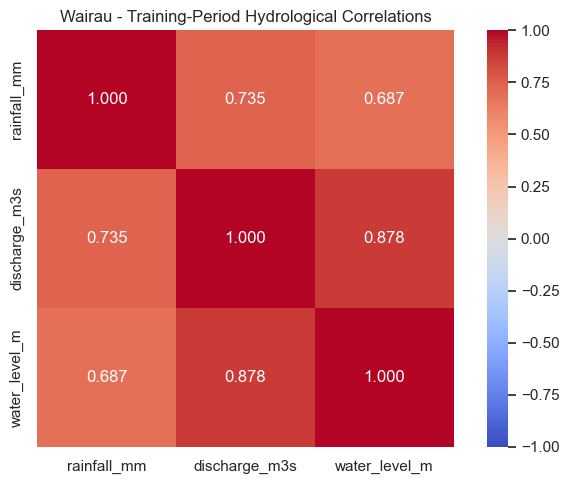

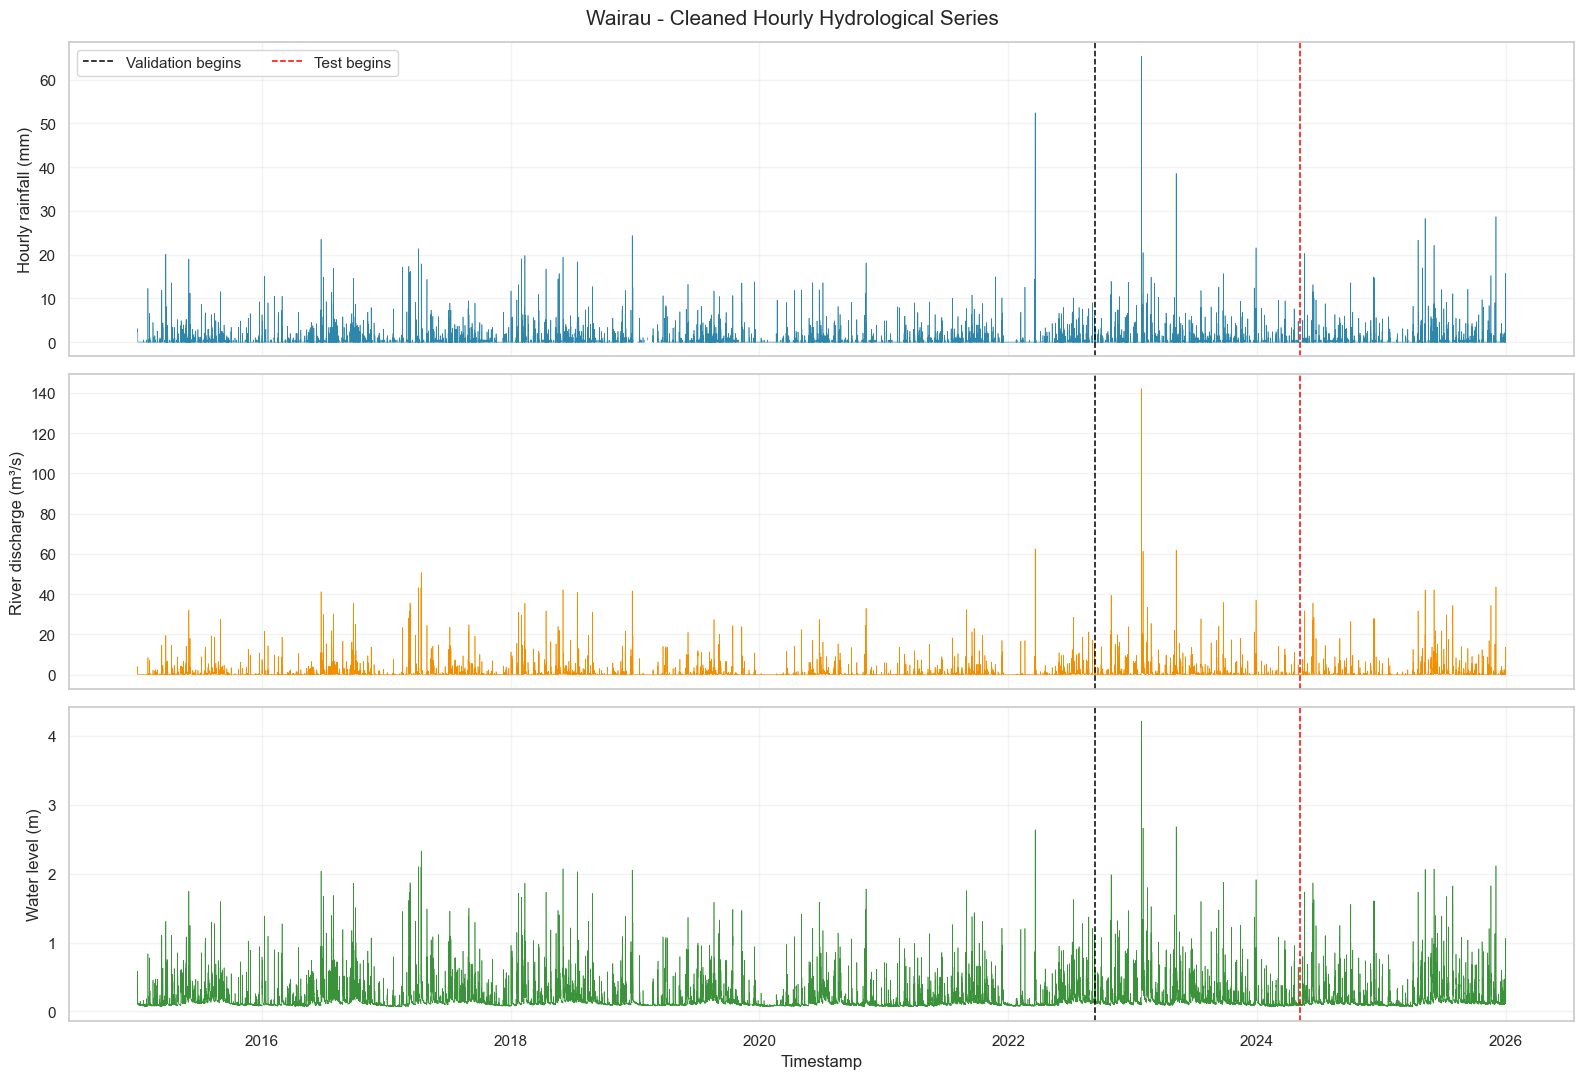

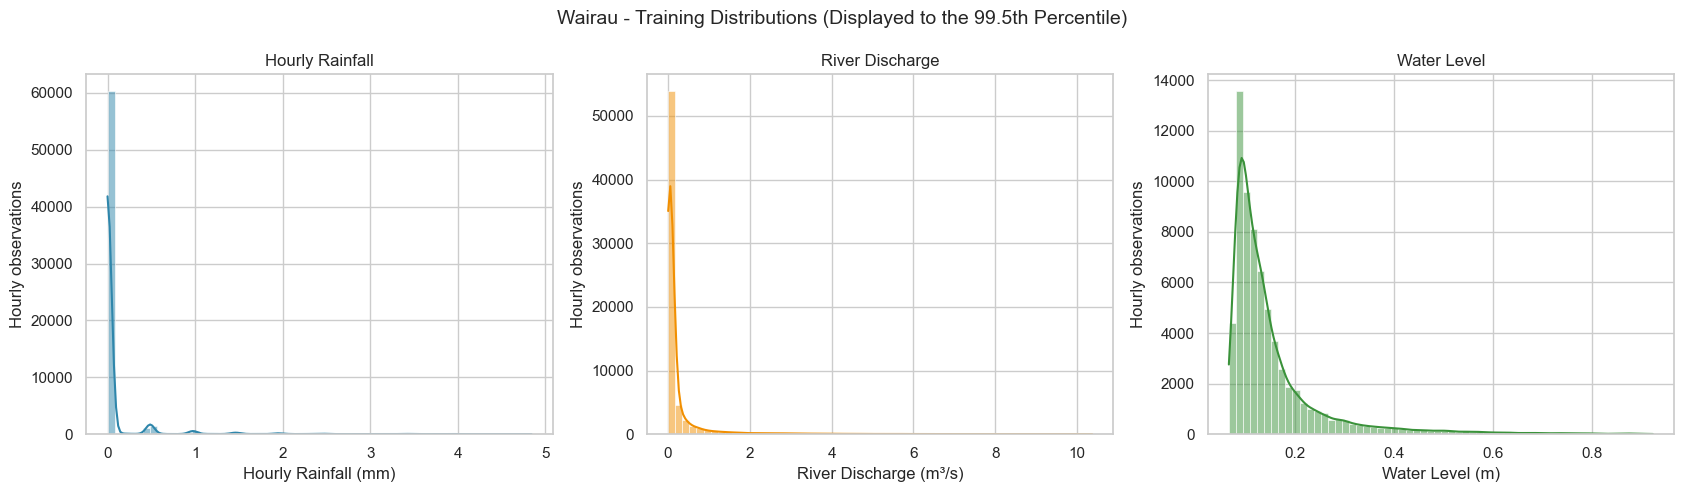


Distribution display limits compared with the original training maxima:


,variable,displayed_99_5_percentile,training_maximum
0,rainfall_mm,4.842,52.428
1,discharge_m3s,10.363,62.470
2,water_level_m,0.924,2.637



Training-period monthly climatology:


,month,mean_monthly_rainfall_mm,median_monthly_rainfall_mm,mean_discharge_m3s,mean_water_level_m,calendar_months_available,month_name
0,1,56.346,38.685,0.165,0.112,8,Jan
1,2,76.655,69.175,0.254,0.125,8,Feb
2,3,104.454,78.760,0.324,0.133,8,Mar
3,4,90.226,81.615,0.350,0.144,8,Apr
4,5,110.855,113.425,0.355,0.159,8,May
5,6,128.512,126.770,0.502,0.193,8,Jun
6,7,149.717,135.355,0.604,0.215,8,Jul
7,8,140.309,137.606,0.567,0.209,8,Aug
8,9,102.975,108.880,0.479,0.189,8,Sep
9,10,76.530,71.270,0.280,0.154,7,Oct


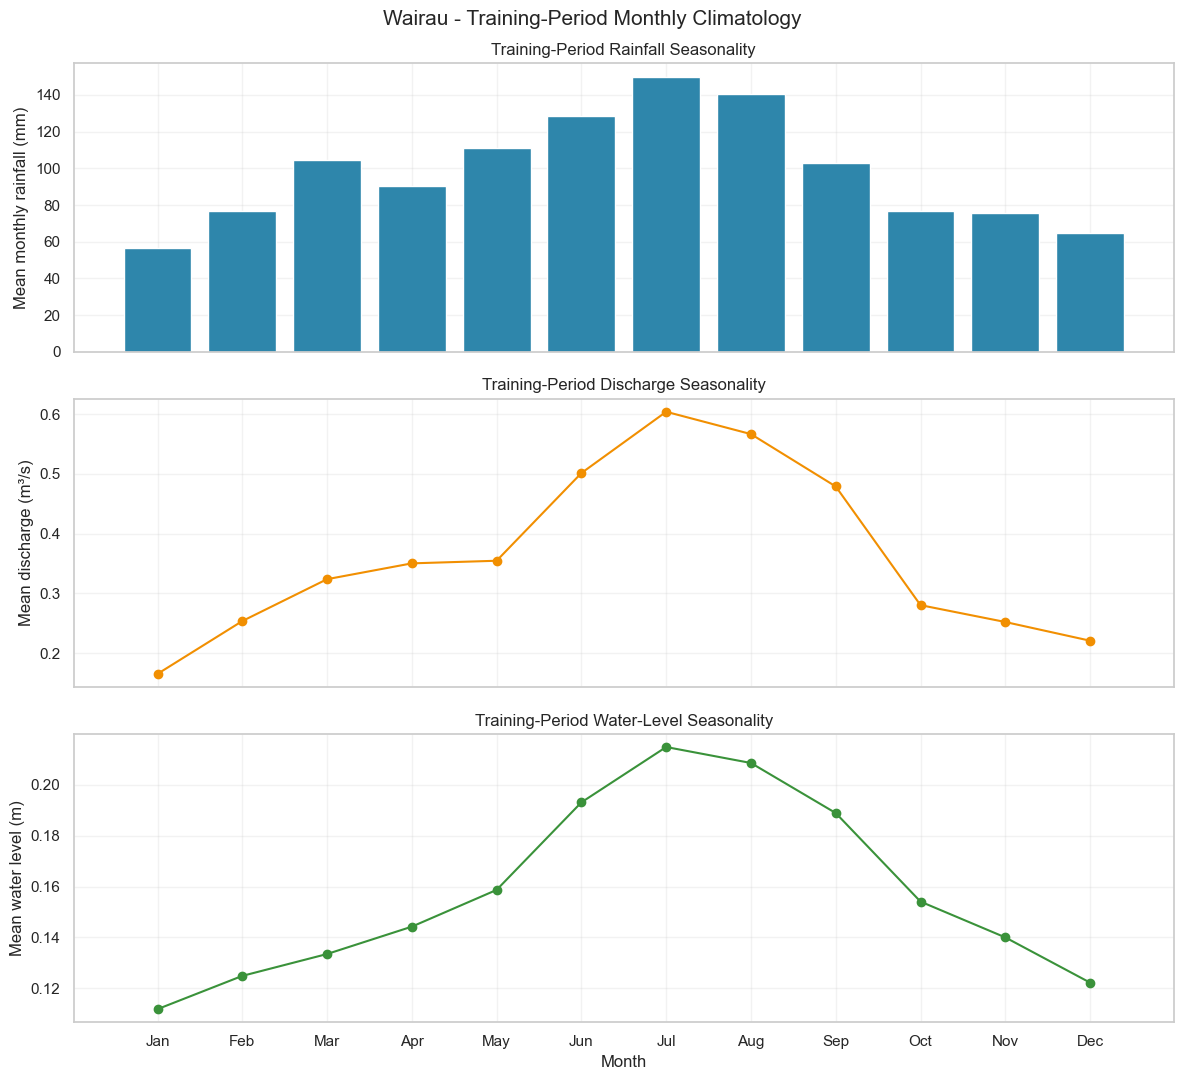


Rainfall measurement-source counts:


,rainfall_source,hours
0,primary_647722,83175
1,support_647737,11782
2,missing,1155
3,support_647738,320



Water-level measurement-source counts:


,water_level_source,hours
0,primary_7604,96299
1,converted_support_7607,131
2,missing,2


In [11]:
# 2. EXPLORATORY DATA ANALYSIS

eda_variables = [
    "rainfall_mm",
    "discharge_m3s",
    "water_level_m"
]

training_base_data = wairau_cleaned_hourly_data.loc[
    wairau_cleaned_hourly_data["data_split"] ==
    "Training",
    eda_variables
].copy()


# 1. Training-period descriptive statistics

wairau_training_descriptive_statistics = (
    training_base_data
    .describe(
        percentiles=[
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.99,
            0.995
        ]
    )
    .T
)

wairau_training_descriptive_statistics[
    "missing_values"
] = training_base_data.isna().sum()

wairau_training_descriptive_statistics[
    "missing_percentage"
] = (
    training_base_data.isna().mean() * 100
)

print("Wairau training-period descriptive statistics:")
display(wairau_training_descriptive_statistics)


# 2. Training-period correlation matrix

wairau_training_correlation = (
    training_base_data.corr(method="pearson")
)

print("\nTraining-period Pearson correlation matrix:")
display(wairau_training_correlation)

plt.figure(figsize=(7, 5))

sns.heatmap(
    wairau_training_correlation,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True
)

plt.title(
    "Wairau - Training-Period Hydrological Correlations"
)

plt.tight_layout()
plt.show()


# 3. Full-period time-series overview

figure, axes = plt.subplots(
    3,
    1,
    figsize=(16, 11),
    sharex=True
)

plot_settings = [
    (
        "rainfall_mm",
        "Hourly rainfall (mm)",
        "#2E86AB"
    ),
    (
        "discharge_m3s",
        "River discharge (m³/s)",
        "#F18F01"
    ),
    (
        "water_level_m",
        "Water level (m)",
        "#3A923A"
    )
]

for axis, (
    variable,
    y_label,
    colour
) in zip(axes, plot_settings):

    axis.plot(
        wairau_cleaned_hourly_data.index,
        wairau_cleaned_hourly_data[variable],
        color=colour,
        linewidth=0.45
    )

    axis.set_ylabel(y_label)
    axis.grid(alpha=0.25)

    # Chronological boundaries
    axis.axvline(
        VALIDATION_START,
        color="black",
        linestyle="--",
        linewidth=1.1,
        label="Validation begins"
    )

    axis.axvline(
        TEST_START,
        color="red",
        linestyle="--",
        linewidth=1.1,
        label="Test begins"
    )

axes[0].legend(
    loc="upper left",
    ncol=2
)

axes[-1].set_xlabel("Timestamp")

figure.suptitle(
    "Wairau - Cleaned Hourly Hydrological Series",
    fontsize=15
)

plt.tight_layout()
plt.show()


# 4. Training-period distributions

figure, axes = plt.subplots(
    1,
    3,
    figsize=(17, 5)
)

distribution_colours = {
    "rainfall_mm": "#2E86AB",
    "discharge_m3s": "#F18F01",
    "water_level_m": "#3A923A"
}

distribution_titles = {
    "rainfall_mm": "Hourly Rainfall",
    "discharge_m3s": "River Discharge",
    "water_level_m": "Water Level"
}

distribution_units = {
    "rainfall_mm": "mm",
    "discharge_m3s": "m³/s",
    "water_level_m": "m"
}

distribution_limits = {}

for axis, variable in zip(
    axes,
    eda_variables
):

    available_values = (
        training_base_data[variable]
        .dropna()
    )

    upper_limit = available_values.quantile(
        0.995
    )

    distribution_limits[variable] = upper_limit

    plotted_values = available_values.loc[
        available_values <= upper_limit
    ]

    sns.histplot(
        plotted_values,
        bins=60,
        kde=True,
        color=distribution_colours[variable],
        ax=axis
    )

    axis.set_title(
        distribution_titles[variable]
    )

    axis.set_xlabel(
        f"{distribution_titles[variable]} "
        f"({distribution_units[variable]})"
    )

    axis.set_ylabel("Hourly observations")

figure.suptitle(
    "Wairau - Training Distributions "
    "(Displayed to the 99.5th Percentile)",
    fontsize=14
)

plt.tight_layout()
plt.show()


wairau_distribution_limits = pd.DataFrame({
    "variable": list(distribution_limits.keys()),
    "displayed_99_5_percentile": list(
        distribution_limits.values()
    ),
    "training_maximum": [
        training_base_data[variable].max()
        for variable in distribution_limits
    ]
})

print(
    "\nDistribution display limits compared with "
    "the original training maxima:"
)

display(wairau_distribution_limits)


# 5. Training-period monthly climatology

training_monthly = pd.DataFrame(
    index=training_base_data.index
)

training_monthly["rainfall_mm"] = (
    training_base_data["rainfall_mm"]
)

training_monthly["discharge_m3s"] = (
    training_base_data["discharge_m3s"]
)

training_monthly["water_level_m"] = (
    training_base_data["water_level_m"]
)

# Aggregate individual calendar months first
monthly_aggregated = pd.DataFrame({
    "rainfall_total_mm":
        training_monthly["rainfall_mm"]
        .resample("MS")
        .sum(min_count=1),

    "mean_discharge_m3s":
        training_monthly["discharge_m3s"]
        .resample("MS")
        .mean(),

    "mean_water_level_m":
        training_monthly["water_level_m"]
        .resample("MS")
        .mean()
})

monthly_aggregated["month"] = (
    monthly_aggregated.index.month
)

wairau_monthly_climatology = (
    monthly_aggregated
    .groupby("month")
    .agg(
        mean_monthly_rainfall_mm=(
            "rainfall_total_mm",
            "mean"
        ),
        median_monthly_rainfall_mm=(
            "rainfall_total_mm",
            "median"
        ),
        mean_discharge_m3s=(
            "mean_discharge_m3s",
            "mean"
        ),
        mean_water_level_m=(
            "mean_water_level_m",
            "mean"
        ),
        calendar_months_available=(
            "rainfall_total_mm",
            "count"
        )
    )
    .reset_index()
)

month_labels = [
    "Jan", "Feb", "Mar", "Apr",
    "May", "Jun", "Jul", "Aug",
    "Sep", "Oct", "Nov", "Dec"
]

wairau_monthly_climatology["month_name"] = (
    wairau_monthly_climatology["month"]
    .map(
        dict(
            zip(
                range(1, 13),
                month_labels
            )
        )
    )
)

print("\nTraining-period monthly climatology:")
display(wairau_monthly_climatology)


# 6. Plot monthly training climatology

figure, axes = plt.subplots(
    3,
    1,
    figsize=(12, 11),
    sharex=True
)

axes[0].bar(
    wairau_monthly_climatology["month_name"],
    wairau_monthly_climatology[
        "mean_monthly_rainfall_mm"
    ],
    color="#2E86AB"
)

axes[0].set_ylabel(
    "Mean monthly rainfall (mm)"
)

axes[0].set_title(
    "Training-Period Rainfall Seasonality"
)

axes[1].plot(
    wairau_monthly_climatology["month_name"],
    wairau_monthly_climatology[
        "mean_discharge_m3s"
    ],
    marker="o",
    color="#F18F01"
)

axes[1].set_ylabel(
    "Mean discharge (m³/s)"
)

axes[1].set_title(
    "Training-Period Discharge Seasonality"
)

axes[2].plot(
    wairau_monthly_climatology["month_name"],
    wairau_monthly_climatology[
        "mean_water_level_m"
    ],
    marker="o",
    color="#3A923A"
)

axes[2].set_ylabel(
    "Mean water level (m)"
)

axes[2].set_xlabel("Month")

axes[2].set_title(
    "Training-Period Water-Level Seasonality"
)

for axis in axes:
    axis.grid(alpha=0.25)

figure.suptitle(
    "Wairau - Training-Period Monthly Climatology",
    fontsize=15
)

plt.tight_layout()
plt.show()


# 7. Source-use audit

rainfall_source_counts = (
    wairau_cleaned_hourly_data[
        "rainfall_source"
    ]
    .value_counts(dropna=False)
    .rename_axis("rainfall_source")
    .reset_index(name="hours")
)

water_level_source_counts = (
    wairau_cleaned_hourly_data[
        "water_level_source"
    ]
    .value_counts(dropna=False)
    .rename_axis("water_level_source")
    .reset_index(name="hours")
)

print("\nRainfall measurement-source counts:")
display(rainfall_source_counts)

print("\nWater-level measurement-source counts:")
display(water_level_source_counts)

## 3. High-Water Threshold and 24-Hour Risk Target

A catchment-specific high-water threshold is calculated as the 99.5th percentile of cleaned water-level observations in the training period only. Validation and test water levels are excluded from threshold estimation, ensuring that the target definition does not use information from future evaluation periods.

For every usable hour, the classification target indicates whether the water level will reach or exceed the frozen high-water threshold during the following 24 hours. The current hour is excluded from the future window. Target construction is performed separately within the training, validation, and test periods so that future outcomes cannot cross chronological split boundaries.

The final 24 hours of each split have no complete within-split forecast horizon and are therefore assigned an unavailable target rather than being labelled as normal-risk observations. Occasional missing water-level measurements inside a future window are ignored when other future measurements remain available.

Training-only 99.5th-percentile high-water threshold: 0.924000 m

Wairau 24-hour target distribution:


,total_rows,usable_target_rows,unavailable_targets,normal_hours,high_risk_hours,high_risk_percentage
data_split,,,,,,
Training,67502,67478,24,64088,3390,5.024
Validation,14465,14441,24,13526,915,6.336
Test,14465,14441,24,13578,863,5.976



Observed high-water threshold exceedances:


,data_split,available_water_level_hours,observed_threshold_exceedance_hours,observed_exceedance_percentage
0,Training,67500,340,0.504
1,Validation,14465,125,0.864
2,Test,14465,104,0.719



Target-boundary validation:


,data_split,split_rows,split_beginning,split_ending,final_24_targets_unavailable,expected_unavailable,boundary_check_passed
0,Training,67502,2015-01-01 01:00:00,2022-09-13 14:00:00,24,24,True
1,Validation,14465,2022-09-13 15:00:00,2024-05-08 07:00:00,24,24,True
2,Test,14465,2024-05-08 08:00:00,2026-01-01 00:00:00,24,24,True


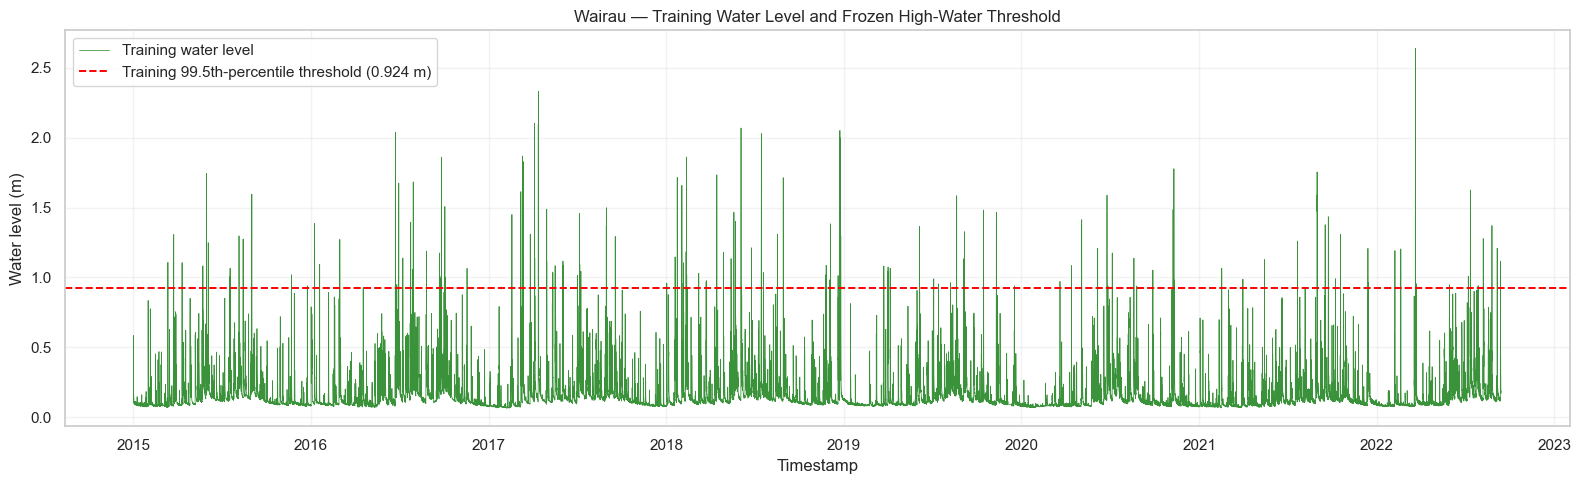


Target behaviour around chronological boundaries:


,data_split,water_level_m,future_24h_max_water_level_m,high_water_risk_24h
timestamp,,,,
2022-09-13 11:00:00,Training,0.184,NaN,<NA>
2022-09-13 12:00:00,Training,0.176,NaN,<NA>
2022-09-13 13:00:00,Training,0.178,NaN,<NA>
2022-09-13 14:00:00,Training,0.171,NaN,<NA>
2022-09-13 15:00:00,Validation,0.171,0.583,0
2022-09-13 16:00:00,Validation,0.175,0.583,0
2022-09-13 17:00:00,Validation,0.186,0.583,0
2022-09-13 18:00:00,Validation,0.583,0.348,0
2024-05-08 04:00:00,Validation,0.094,NaN,<NA>


In [12]:
# 3. TRAINING-ONLY HIGH-WATER THRESHOLD AND 24-HOUR TARGET

HIGH_WATER_PERCENTILE = 0.995
FORECAST_HORIZON_HOURS = 24


# 1. Calculate the threshold from training water level only

training_water_level = (
    wairau_cleaned_hourly_data.loc[
        wairau_cleaned_hourly_data["data_split"] ==
        "Training",
        "water_level_m"
    ]
    .dropna()
)

WAIRAU_HIGH_WATER_THRESHOLD = (
    training_water_level.quantile(
        HIGH_WATER_PERCENTILE
    )
)

print(
    "Training-only 99.5th-percentile "
    "high-water threshold:",
    f"{WAIRAU_HIGH_WATER_THRESHOLD:.6f} m"
)


# 2. Create the target-development dataset

wairau_target_data = (
    wairau_cleaned_hourly_data.copy()
)

wairau_target_data[
    "observed_high_water"
] = pd.Series(
    pd.NA,
    index=wairau_target_data.index,
    dtype="Int64"
)

water_level_available = (
    wairau_target_data["water_level_m"].notna()
)

wairau_target_data.loc[
    water_level_available,
    "observed_high_water"
] = (
    wairau_target_data.loc[
        water_level_available,
        "water_level_m"
    ] >= WAIRAU_HIGH_WATER_THRESHOLD
).astype(int)


wairau_target_data[
    "future_24h_max_water_level_m"
] = np.nan

wairau_target_data[
    "high_water_risk_24h"
] = pd.Series(
    pd.NA,
    index=wairau_target_data.index,
    dtype="Int64"
)


# 3. Construct the target separately within each split

for split_name in [
    "Training",
    "Validation",
    "Test"
]:

    split_mask = (
        wairau_target_data["data_split"] ==
        split_name
    )

    split_water_level = (
        wairau_target_data.loc[
            split_mask,
            "water_level_m"
        ]
    )

    # Each column represents one future forecast hour:
    # t+1, t+2, ..., t+24.
    future_water_levels = pd.concat(
        [
            split_water_level.shift(-future_hour)
            for future_hour in range(
                1,
                FORECAST_HORIZON_HOURS + 1
            )
        ],
        axis=1
    )

    future_water_levels.columns = [
        f"water_level_t_plus_{future_hour}"
        for future_hour in range(
            1,
            FORECAST_HORIZON_HOURS + 1
        )
    ]

    # Missing observations inside the horizon are ignored
    # when at least one future value remains available.
    future_maximum = future_water_levels.max(
        axis=1,
        skipna=True
    )

    # The final 24 hours do not have a full within-split
    # forecast horizon and must remain unavailable.
    if len(future_maximum) >= FORECAST_HORIZON_HOURS:
        future_maximum.iloc[
            -FORECAST_HORIZON_HOURS:
        ] = np.nan

    wairau_target_data.loc[
        split_mask,
        "future_24h_max_water_level_m"
    ] = future_maximum

    target_available = (
        future_maximum.notna()
    )

    split_target = pd.Series(
        pd.NA,
        index=future_maximum.index,
        dtype="Int64"
    )

    split_target.loc[
        target_available
    ] = (
        future_maximum.loc[target_available] >=
        WAIRAU_HIGH_WATER_THRESHOLD
    ).astype(int)

    wairau_target_data.loc[
        split_mask,
        "high_water_risk_24h"
    ] = split_target


# Ensure the nullable integer data type is retained
wairau_target_data[
    "high_water_risk_24h"
] = wairau_target_data[
    "high_water_risk_24h"
].astype("Int64")


# 4. Summarise the target distribution by split

target_summary_rows = []

for split_name in [
    "Training",
    "Validation",
    "Test"
]:

    split_target = wairau_target_data.loc[
        wairau_target_data["data_split"] ==
        split_name,
        "high_water_risk_24h"
    ]

    usable_target = split_target.dropna()

    high_risk_hours = int(
        (usable_target == 1).sum()
    )

    normal_hours = int(
        (usable_target == 0).sum()
    )

    target_summary_rows.append({
        "data_split": split_name,
        "total_rows": len(split_target),
        "usable_target_rows": len(usable_target),
        "unavailable_targets": int(
            split_target.isna().sum()
        ),
        "normal_hours": normal_hours,
        "high_risk_hours": high_risk_hours,
        "high_risk_percentage":
            (
                high_risk_hours /
                len(usable_target) *
                100
            )
            if len(usable_target) > 0
            else np.nan
    })

wairau_target_summary = pd.DataFrame(
    target_summary_rows
).set_index("data_split")

print("\nWairau 24-hour target distribution:")
display(wairau_target_summary)


# 5. Summarise observed threshold-exceedance hours

observed_high_water_summary = []

for split_name in [
    "Training",
    "Validation",
    "Test"
]:

    split_observed = wairau_target_data.loc[
        wairau_target_data["data_split"] ==
        split_name,
        "observed_high_water"
    ]

    available_observed = (
        split_observed.dropna()
    )

    observed_high_water_summary.append({
        "data_split": split_name,
        "available_water_level_hours":
            len(available_observed),
        "observed_threshold_exceedance_hours":
            int(
                (available_observed == 1).sum()
            ),
        "observed_exceedance_percentage":
            (
                (available_observed == 1).mean() *
                100
            )
            if len(available_observed) > 0
            else np.nan
    })

wairau_observed_high_water_summary = pd.DataFrame(
    observed_high_water_summary
)

print("\nObserved high-water threshold exceedances:")
display(wairau_observed_high_water_summary)


# 6. Validate that target windows do not cross boundaries

boundary_validation_rows = []

for split_name in [
    "Training",
    "Validation",
    "Test"
]:

    split_data = wairau_target_data.loc[
        wairau_target_data["data_split"] ==
        split_name
    ]

    final_horizon = split_data.tail(
        FORECAST_HORIZON_HOURS
    )

    boundary_validation_rows.append({
        "data_split": split_name,
        "split_rows": len(split_data),
        "split_beginning": split_data.index.min(),
        "split_ending": split_data.index.max(),
        "final_24_targets_unavailable":
            int(
                final_horizon[
                    "high_water_risk_24h"
                ].isna().sum()
            ),
        "expected_unavailable": (
            FORECAST_HORIZON_HOURS
        ),
        "boundary_check_passed": bool(
            final_horizon[
                "high_water_risk_24h"
            ].isna().all()
        )
    })

wairau_target_boundary_check = pd.DataFrame(
    boundary_validation_rows
)

print("\nTarget-boundary validation:")
display(wairau_target_boundary_check)


# 7. Plot the training water level and frozen threshold

plt.figure(figsize=(16, 5))

plt.plot(
    training_water_level.index,
    training_water_level,
    color="#3A923A",
    linewidth=0.55,
    label="Training water level"
)

plt.axhline(
    WAIRAU_HIGH_WATER_THRESHOLD,
    color="red",
    linestyle="--",
    linewidth=1.4,
    label=(
        "Training 99.5th-percentile threshold "
        f"({WAIRAU_HIGH_WATER_THRESHOLD:.3f} m)"
    )
)

plt.title(
    "Wairau — Training Water Level and "
    "Frozen High-Water Threshold"
)

plt.xlabel("Timestamp")
plt.ylabel("Water level (m)")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


# 8. Display observations around the split boundaries

boundary_examples = pd.concat([
    wairau_target_data.loc[
        TRAIN_END - pd.Timedelta(hours=3):
        VALIDATION_START + pd.Timedelta(hours=3),
        [
            "data_split",
            "water_level_m",
            "future_24h_max_water_level_m",
            "high_water_risk_24h"
        ]
    ],
    wairau_target_data.loc[
        VALIDATION_END - pd.Timedelta(hours=3):
        TEST_START + pd.Timedelta(hours=3),
        [
            "data_split",
            "water_level_m",
            "future_24h_max_water_level_m",
            "high_water_risk_24h"
        ]
    ]
])

print("\nTarget behaviour around chronological boundaries:")
display(boundary_examples)

## 4. Hydrological Feature Engineering

Predictive features are constructed using only information available at or before each prediction timestamp. The feature set combines current hydrological measurements, antecedent rainfall accumulation, lagged river conditions, short- and medium-term changes, and cyclical time indicators.

Rainfall accumulation is calculated over the previous 3, 6, 12, 24, and 48 hours, including the current hour. Water-level and discharge lags represent conditions 1, 3, 6, 12, 24, and 48 hours earlier. Change features compare the current measurement with values 1, 3, and 24 hours earlier. Hour and month are represented with sine and cosine transformations to preserve their cyclical structure.

All rolling and lagged features are causal. No future measurements or target values are used as predictors. Missing observations are retained during feature construction and audited before the final model-ready rows are selected.

In [13]:
# 4. HYDROLOGICAL FEATURE ENGINEERING

wairau_feature_data = (
    wairau_target_data.copy()
)


# 1. Antecedent rainfall accumulation features

rainfall_windows = [
    3,
    6,
    12,
    24,
    48
]

for window_hours in rainfall_windows:

    wairau_feature_data[
        f"rainfall_sum_{window_hours}h"
    ] = (
        wairau_feature_data["rainfall_mm"]
        .rolling(
            window=window_hours,
            min_periods=window_hours
        )
        .sum()
    )


# 2. Water-level lag features

hydrological_lags = [
    1,
    3,
    6,
    12,
    24,
    48
]

for lag_hours in hydrological_lags:

    wairau_feature_data[
        f"water_level_lag_{lag_hours}h"
    ] = (
        wairau_feature_data["water_level_m"]
        .shift(lag_hours)
    )


# 3. Discharge lag features

for lag_hours in hydrological_lags:

    wairau_feature_data[
        f"discharge_lag_{lag_hours}h"
    ] = (
        wairau_feature_data["discharge_m3s"]
        .shift(lag_hours)
    )


# 4. Water-level change features

change_intervals = [
    1,
    3,
    24
]

for change_hours in change_intervals:

    wairau_feature_data[
        f"water_level_change_{change_hours}h"
    ] = (
        wairau_feature_data["water_level_m"] -
        wairau_feature_data["water_level_m"]
        .shift(change_hours)
    )


# 5. Discharge change features

for change_hours in change_intervals:

    wairau_feature_data[
        f"discharge_change_{change_hours}h"
    ] = (
        wairau_feature_data["discharge_m3s"] -
        wairau_feature_data["discharge_m3s"]
        .shift(change_hours)
    )


# 6. Cyclical time features

hour_of_day = (
    wairau_feature_data.index.hour
)

month_of_year = (
    wairau_feature_data.index.month
)

wairau_feature_data["hour_sin"] = np.sin(
    2 * np.pi * hour_of_day / 24
)

wairau_feature_data["hour_cos"] = np.cos(
    2 * np.pi * hour_of_day / 24
)

wairau_feature_data["month_sin"] = np.sin(
    2 * np.pi * (month_of_year - 1) / 12
)

wairau_feature_data["month_cos"] = np.cos(
    2 * np.pi * (month_of_year - 1) / 12
)


# 7. Define the final 30 model predictors

WAIRAU_MODEL_FEATURES = [
    # Current hydrological conditions
    "rainfall_mm",
    "water_level_m",
    "discharge_m3s",

    # Antecedent rainfall
    "rainfall_sum_3h",
    "rainfall_sum_6h",
    "rainfall_sum_12h",
    "rainfall_sum_24h",
    "rainfall_sum_48h",

    # Water-level lags
    "water_level_lag_1h",
    "water_level_lag_3h",
    "water_level_lag_6h",
    "water_level_lag_12h",
    "water_level_lag_24h",
    "water_level_lag_48h",

    # Discharge lags
    "discharge_lag_1h",
    "discharge_lag_3h",
    "discharge_lag_6h",
    "discharge_lag_12h",
    "discharge_lag_24h",
    "discharge_lag_48h",

    # Water-level changes
    "water_level_change_1h",
    "water_level_change_3h",
    "water_level_change_24h",

    # Discharge changes
    "discharge_change_1h",
    "discharge_change_3h",
    "discharge_change_24h",

    # Cyclical time indicators
    "hour_sin",
    "hour_cos",
    "month_sin",
    "month_cos"
]

WAIRAU_TARGET_COLUMN = (
    "high_water_risk_24h"
)


# 8. Validate feature count and uniqueness

if len(WAIRAU_MODEL_FEATURES) != 30:
    raise ValueError(
        "The Wairau feature list must contain exactly "
        f"30 predictors, but contains "
        f"{len(WAIRAU_MODEL_FEATURES)}."
    )

if len(set(WAIRAU_MODEL_FEATURES)) != 30:
    raise ValueError(
        "Duplicate predictor names were detected in "
        "WAIRAU_MODEL_FEATURES."
    )

missing_feature_columns = [
    feature
    for feature in WAIRAU_MODEL_FEATURES
    if feature not in wairau_feature_data.columns
]

if missing_feature_columns:
    raise ValueError(
        "The following model features were not created: "
        f"{missing_feature_columns}"
    )


# 9. Audit missing predictor values

wairau_feature_missing_summary = (
    wairau_feature_data[
        WAIRAU_MODEL_FEATURES
    ]
    .isna()
    .sum()
    .rename("missing_rows")
    .to_frame()
)

wairau_feature_missing_summary[
    "missing_percentage"
] = (
    wairau_feature_missing_summary[
        "missing_rows"
    ] /
    len(wairau_feature_data) *
    100
)

wairau_feature_missing_summary = (
    wairau_feature_missing_summary
    .sort_values(
        by=[
            "missing_rows",
            "missing_percentage"
        ],
        ascending=False
    )
)

print(
    "Feature-engineered shape:",
    wairau_feature_data.shape
)

print(
    "Number of model features:",
    len(WAIRAU_MODEL_FEATURES)
)

print("\nMissing values in model predictors:")
display(wairau_feature_missing_summary)


# 10. Check for infinite feature values

wairau_infinite_feature_summary = pd.DataFrame({
    "feature": WAIRAU_MODEL_FEATURES,
    "positive_infinity": [
        int(
            np.isposinf(
                wairau_feature_data[feature]
                .to_numpy(dtype=float)
            ).sum()
        )
        for feature in WAIRAU_MODEL_FEATURES
    ],
    "negative_infinity": [
        int(
            np.isneginf(
                wairau_feature_data[feature]
                .to_numpy(dtype=float)
            ).sum()
        )
        for feature in WAIRAU_MODEL_FEATURES
    ]
})

wairau_infinite_feature_summary[
    "total_infinite"
] = (
    wairau_infinite_feature_summary[
        "positive_infinity"
    ] +
    wairau_infinite_feature_summary[
        "negative_infinity"
    ]
)

print("\nInfinite-value audit:")
display(
    wairau_infinite_feature_summary.loc[
        wairau_infinite_feature_summary[
            "total_infinite"
        ] > 0
    ]
)

print(
    "\nTotal infinite predictor values:",
    int(
        wairau_infinite_feature_summary[
            "total_infinite"
        ].sum()
    )
)


# 11. Display a sample of engineered features

sample_feature_columns = [
    "rainfall_mm",
    "rainfall_sum_3h",
    "rainfall_sum_24h",
    "rainfall_sum_48h",
    "water_level_m",
    "water_level_lag_1h",
    "water_level_lag_24h",
    "water_level_change_3h",
    "discharge_m3s",
    "discharge_lag_24h",
    "discharge_change_3h",
    "hour_sin",
    "hour_cos",
    "month_sin",
    "month_cos",
    "high_water_risk_24h"
]

print("\nSample of the engineered Wairau dataset:")
display(
    wairau_feature_data[
        sample_feature_columns
    ].head(55)
)

Feature-engineered shape: (96432, 41)
Number of model features: 30

Missing values in model predictors:


,missing_rows,missing_percentage
rainfall_sum_48h,1345,1.395
rainfall_sum_24h,1249,1.295
rainfall_sum_12h,1201,1.245
rainfall_sum_6h,1177,1.221
rainfall_sum_3h,1165,1.208
rainfall_mm,1155,1.198
discharge_change_24h,218,0.226
discharge_lag_48h,174,0.180
discharge_change_3h,169,0.175
discharge_lag_24h,150,0.156



Infinite-value audit:


,feature,positive_infinity,negative_infinity,total_infinite



Total infinite predictor values: 0

Sample of the engineered Wairau dataset:


,rainfall_mm,rainfall_sum_3h,rainfall_sum_24h,rainfall_sum_48h,water_level_m,water_level_lag_1h,water_level_lag_24h,water_level_change_3h,discharge_m3s,discharge_lag_24h,discharge_change_3h,hour_sin,hour_cos,month_sin,month_cos,high_water_risk_24h
timestamp,,,,,,,,,,,,,,,,
2015-01-01 01:00:00,2.452,NaN,NaN,NaN,0.112,NaN,NaN,NaN,0.052,NaN,NaN,0.259,0.966,0.000,1.000,0
2015-01-01 02:00:00,2.118,NaN,NaN,NaN,0.574,0.112,NaN,NaN,3.763,NaN,NaN,0.500,0.866,0.000,1.000,0
2015-01-01 03:00:00,3.050,7.620,NaN,NaN,0.585,0.574,NaN,NaN,3.920,NaN,NaN,0.707,0.707,0.000,1.000,0
2015-01-01 04:00:00,0.000,5.168,NaN,NaN,0.581,0.585,NaN,0.469,3.863,NaN,3.811,0.866,0.500,0.000,1.000,0
2015-01-01 05:00:00,0.000,3.050,NaN,NaN,0.302,0.581,NaN,-0.272,0.763,NaN,-3.000,0.966,0.259,0.000,1.000,0
2015-01-01 06:00:00,0.000,0.000,NaN,NaN,0.239,0.302,NaN,-0.346,0.408,NaN,-3.512,1.000,0.000,0.000,1.000,0
2015-01-01 07:00:00,0.000,0.000,NaN,NaN,0.203,0.239,NaN,-0.378,0.255,NaN,-3.608,0.966,-0.259,0.000,1.000,0
2015-01-01 08:00:00,0.000,0.000,NaN,NaN,0.174,0.203,NaN,-0.128,0.150,NaN,-0.613,0.866,-0.500,0.000,1.000,0
2015-01-01 09:00:00,0.000,0.000,NaN,NaN,0.162,0.174,NaN,-0.077,0.122,NaN,-0.286,0.707,-0.707,0.000,1.000,0


## Model-Ready Dataset and Chronological Partitions

Rows are retained only when the 24-hour target and all 30 model predictors are available. This complete-case filtering is performed separately within the training, validation, and test periods.

No statistical imputation is applied. The chronological split assignments remain unchanged, and the test partition remains untouched for final evaluation. Lagged predictors may use observations from earlier timestamps because those values would have been available at prediction time, while the target has already been constructed independently within each split to prevent future information from crossing a split boundary.

In [14]:
# Create model-ready training, validation, and test datasets.

model_required_columns = (
    WAIRAU_MODEL_FEATURES + [WAIRAU_TARGET_COLUMN]
)

split_datasets = {}
model_ready_summary_rows = []

for split_name in ["Training", "Validation", "Test"]:
    split_data = wairau_feature_data.loc[
        wairau_feature_data["data_split"].eq(split_name)
    ].copy()

    predictor_complete = split_data[WAIRAU_MODEL_FEATURES].notna().all(axis=1)
    target_available = split_data[WAIRAU_TARGET_COLUMN].notna()
    usable_mask = predictor_complete & target_available

    model_ready_split = split_data.loc[
        usable_mask,
        model_required_columns
    ].copy()

    model_ready_split[WAIRAU_TARGET_COLUMN] = (
        model_ready_split[WAIRAU_TARGET_COLUMN].astype("int8")
    )

    split_datasets[split_name] = model_ready_split

    high_risk_rows = int(
        model_ready_split[WAIRAU_TARGET_COLUMN].sum()
    )
    usable_rows = len(model_ready_split)

    model_ready_summary_rows.append({
        "data_split": split_name,
        "original_split_rows": len(split_data),
        "predictor_complete_rows": int(predictor_complete.sum()),
        "target_available_rows": int(target_available.sum()),
        "model_ready_rows": usable_rows,
        "excluded_rows": len(split_data) - usable_rows,
        "normal_rows": usable_rows - high_risk_rows,
        "high_risk_rows": high_risk_rows,
        "high_risk_percentage": (
            100 * high_risk_rows / usable_rows
            if usable_rows > 0 else np.nan
        ),
        "beginning": (
            model_ready_split.index.min()
            if usable_rows > 0 else pd.NaT
        ),
        "ending": (
            model_ready_split.index.max()
            if usable_rows > 0 else pd.NaT
        )
    })

# Separate predictor matrices, targets, and timestamps.
X_train = split_datasets["Training"][WAIRAU_MODEL_FEATURES].copy()
y_train = split_datasets["Training"][WAIRAU_TARGET_COLUMN].copy()
training_timestamps = X_train.index.copy()

X_validation = split_datasets["Validation"][WAIRAU_MODEL_FEATURES].copy()
y_validation = split_datasets["Validation"][WAIRAU_TARGET_COLUMN].copy()
validation_timestamps = X_validation.index.copy()

X_test = split_datasets["Test"][WAIRAU_MODEL_FEATURES].copy()
y_test = split_datasets["Test"][WAIRAU_TARGET_COLUMN].copy()
test_timestamps = X_test.index.copy()

wairau_model_ready_summary = pd.DataFrame(
    model_ready_summary_rows
)

print("Model-ready chronological split summary:")
display(
    wairau_model_ready_summary.style.format({
        "high_risk_percentage": "{:.3f}",
        "beginning": lambda value: (
            value.strftime("%Y-%m-%d %H:%M:%S")
            if pd.notna(value) else ""
        ),
        "ending": lambda value: (
            value.strftime("%Y-%m-%d %H:%M:%S")
            if pd.notna(value) else ""
        )
    })
)

# Validation checks.
model_matrices = {
    "Training": (X_train, y_train),
    "Validation": (X_validation, y_validation),
    "Test": (X_test, y_test)
}

validation_rows = []

for split_name, (X_split, y_split) in model_matrices.items():
    validation_rows.append({
        "data_split": split_name,
        "rows": len(X_split),
        "features": X_split.shape[1],
        "missing_predictor_values": int(X_split.isna().sum().sum()),
        "infinite_predictor_values": int(
            np.isinf(X_split.to_numpy(dtype=float)).sum()
        ),
        "missing_targets": int(y_split.isna().sum()),
        "chronologically_sorted": bool(
            X_split.index.is_monotonic_increasing
        ),
        "duplicate_timestamps": int(
            X_split.index.duplicated().sum()
        )
    })

wairau_model_ready_validation = pd.DataFrame(validation_rows)

print("\nModel-ready validation checks:")
display(wairau_model_ready_validation)

# Confirm that the three partitions do not overlap.
split_overlap_checks = pd.DataFrame([
    {
        "split_pair": "Training versus Validation",
        "overlapping_timestamps": len(
            X_train.index.intersection(X_validation.index)
        )
    },
    {
        "split_pair": "Training versus Test",
        "overlapping_timestamps": len(
            X_train.index.intersection(X_test.index)
        )
    },
    {
        "split_pair": "Validation versus Test",
        "overlapping_timestamps": len(
            X_validation.index.intersection(X_test.index)
        )
    }
])

print("\nChronological partition overlap checks:")
display(split_overlap_checks)

print(f"\nTraining matrix shape:   {X_train.shape}")
print(f"Validation matrix shape: {X_validation.shape}")
print(f"Test matrix shape:       {X_test.shape}")

Model-ready chronological split summary:


,data_split,original_split_rows,predictor_complete_rows,target_available_rows,model_ready_rows,excluded_rows,normal_rows,high_risk_rows,high_risk_percentage,beginning,ending
0,Training,67502,65968,67478,65944,1558,62583,3361,5.097,2015-01-03 01:00:00,2022-09-12 14:00:00
1,Validation,14465,14296,14441,14272,193,13382,890,6.236,2022-09-13 15:00:00,2024-05-07 07:00:00
2,Test,14465,14451,14441,14427,38,13564,863,5.982,2024-05-08 08:00:00,2025-12-31 00:00:00



Model-ready validation checks:


,data_split,rows,features,missing_predictor_values,infinite_predictor_values,missing_targets,chronologically_sorted,duplicate_timestamps
0,Training,65944,30,0,0,0,True,0
1,Validation,14272,30,0,0,0,True,0
2,Test,14427,30,0,0,0,True,0



Chronological partition overlap checks:


,split_pair,overlapping_timestamps
0,Training versus Validation,0
1,Training versus Test,0
2,Validation versus Test,0



Training matrix shape:   (65944, 30)
Validation matrix shape: (14272, 30)
Test matrix shape:       (14427, 30)


## Random Forest Classification Model

A Random Forest classifier is trained using only the model-ready training partition. Class weighting is used because high-water-risk observations represent only about 5% of the training data.

Initial performance is evaluated on the training and validation partitions using the default probability threshold of 0.50. The untouched test partition is reserved for final evaluation after model comparison and validation-based threshold selection.

Because Random Forest is a tree-based model, predictor scaling is not required.

In [15]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Train the Random Forest only on the training partition.
wairau_random_forest = RandomForestClassifier(
    n_estimators=500,
    max_features="sqrt",
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

wairau_random_forest.fit(X_train, y_train)

# Generate probabilities for training and validation only.
rf_training_probability = wairau_random_forest.predict_proba(X_train)[:, 1]
rf_validation_probability = wairau_random_forest.predict_proba(
    X_validation
)[:, 1]

# Initial classifications use the standard 0.50 threshold.
RF_DEFAULT_THRESHOLD = 0.50

rf_training_prediction = (
    rf_training_probability >= RF_DEFAULT_THRESHOLD
).astype("int8")

rf_validation_prediction = (
    rf_validation_probability >= RF_DEFAULT_THRESHOLD
).astype("int8")


def binary_classification_metrics(
    y_true,
    y_prediction,
    y_probability,
    dataset_name
):
    """Return classification metrics for one data partition."""
    
    return {
        "data_split": dataset_name,
        "rows": len(y_true),
        "actual_high_risk": int(y_true.sum()),
        "predicted_high_risk": int(y_prediction.sum()),
        "accuracy": accuracy_score(y_true, y_prediction),
        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            y_prediction
        ),
        "precision": precision_score(
            y_true,
            y_prediction,
            zero_division=0
        ),
        "recall": recall_score(
            y_true,
            y_prediction,
            zero_division=0
        ),
        "f1_score": f1_score(
            y_true,
            y_prediction,
            zero_division=0
        ),
        "roc_auc": roc_auc_score(y_true, y_probability),
        "pr_auc": average_precision_score(
            y_true,
            y_probability
        )
    }


rf_initial_metrics = pd.DataFrame([
    binary_classification_metrics(
        y_train,
        rf_training_prediction,
        rf_training_probability,
        "Training"
    ),
    binary_classification_metrics(
        y_validation,
        rf_validation_prediction,
        rf_validation_probability,
        "Validation"
    )
])

print("Random Forest performance at the default 0.50 threshold:")
display(
    rf_initial_metrics.style.format({
        "accuracy": "{:.3f}",
        "balanced_accuracy": "{:.3f}",
        "precision": "{:.3f}",
        "recall": "{:.3f}",
        "f1_score": "{:.3f}",
        "roc_auc": "{:.3f}",
        "pr_auc": "{:.3f}"
    })
)

# Validation confusion matrix.
rf_validation_confusion_matrix = pd.DataFrame(
    confusion_matrix(y_validation, rf_validation_prediction),
    index=["Actual normal", "Actual high risk"],
    columns=["Predicted normal", "Predicted high risk"]
)

print("\nValidation confusion matrix:")
display(rf_validation_confusion_matrix)

print("\nValidation classification report:")
print(
    classification_report(
        y_validation,
        rf_validation_prediction,
        target_names=["Normal", "High risk"],
        digits=3,
        zero_division=0
    )
)

# Predictor importance.
wairau_rf_feature_importance = (
    pd.DataFrame({
        "feature": WAIRAU_MODEL_FEATURES,
        "importance": wairau_random_forest.feature_importances_
    })
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

print("\nRandom Forest predictor importance:")
display(
    wairau_rf_feature_importance.style.format({
        "importance": "{:.4f}"
    })
)

print(
    "\nThe test partition has not been used for fitting, "
    "threshold selection, or evaluation."
)

Random Forest performance at the default 0.50 threshold:


,data_split,rows,actual_high_risk,predicted_high_risk,accuracy,balanced_accuracy,precision,recall,f1_score,roc_auc,pr_auc
0,Training,65944,3361,3361,1.000,1.000,1.000,1.000,1.000,1.000,1.000
1,Validation,14272,890,107,0.941,0.542,0.720,0.087,0.154,0.728,0.245



Validation confusion matrix:


,Predicted normal,Predicted high risk
Actual normal,13352,30
Actual high risk,813,77



Validation classification report:
              precision    recall  f1-score   support

      Normal      0.943     0.998     0.969     13382
   High risk      0.720     0.087     0.154       890

    accuracy                          0.941     14272
   macro avg      0.831     0.542     0.562     14272
weighted avg      0.929     0.941     0.919     14272


Random Forest predictor importance:


,feature,importance
0,water_level_m,0.0542
1,rainfall_sum_48h,0.0493
2,discharge_m3s,0.0482
3,water_level_lag_48h,0.0471
4,discharge_lag_48h,0.0468
5,discharge_change_24h,0.0453
6,water_level_change_24h,0.0450
7,month_sin,0.0430
8,month_cos,0.0420
9,rainfall_sum_24h,0.0383



The test partition has not been used for fitting, threshold selection, or evaluation.


## XGBoost Classification Model

An XGBoost classifier is trained using only the training partition. The imbalance ratio is calculated exclusively from the training labels and supplied through `scale_pos_weight`, giving greater importance to the comparatively rare high-water-risk class.

The validation partition is used for early stopping to control overfitting and identify the most appropriate number of boosting rounds. Initial training and validation performance is assessed at the default 0.50 probability threshold.

The test partition remains untouched until model comparison and validation-based threshold selection are complete.

In [16]:
from xgboost import XGBClassifier

# Calculate the class-imbalance weight using training data only.
training_normal_count = int((y_train == 0).sum())
training_high_risk_count = int((y_train == 1).sum())

wairau_scale_pos_weight = (
    training_normal_count / training_high_risk_count
)

print(
    "Training normal-to-high-risk ratio:",
    f"{wairau_scale_pos_weight:.3f}"
)

# Configure a regularised XGBoost classifier.
wairau_xgboost = XGBClassifier(
    objective="binary:logistic",
    eval_metric="aucpr",
    n_estimators=2000,
    learning_rate=0.03,
    max_depth=5,
    min_child_weight=5,
    subsample=0.80,
    colsample_bytree=0.80,
    gamma=0.10,
    reg_alpha=0.10,
    reg_lambda=2.00,
    scale_pos_weight=wairau_scale_pos_weight,
    early_stopping_rounds=75,
    random_state=42,
    n_jobs=-1,
    tree_method="hist"
)

# Fit on training data; validation is used only for early stopping.
wairau_xgboost.fit(
    X_train,
    y_train,
    eval_set=[(X_validation, y_validation)],
    verbose=False
)

# Generate probabilities for training and validation only.
xgb_training_probability = wairau_xgboost.predict_proba(
    X_train
)[:, 1]

xgb_validation_probability = wairau_xgboost.predict_proba(
    X_validation
)[:, 1]

XGB_DEFAULT_THRESHOLD = 0.50

xgb_training_prediction = (
    xgb_training_probability >= XGB_DEFAULT_THRESHOLD
).astype("int8")

xgb_validation_prediction = (
    xgb_validation_probability >= XGB_DEFAULT_THRESHOLD
).astype("int8")

# Calculate initial performance using the previously defined function.
xgb_initial_metrics = pd.DataFrame([
    binary_classification_metrics(
        y_train,
        xgb_training_prediction,
        xgb_training_probability,
        "Training"
    ),
    binary_classification_metrics(
        y_validation,
        xgb_validation_prediction,
        xgb_validation_probability,
        "Validation"
    )
])

print("\nXGBoost performance at the default 0.50 threshold:")
display(
    xgb_initial_metrics.style.format({
        "accuracy": "{:.3f}",
        "balanced_accuracy": "{:.3f}",
        "precision": "{:.3f}",
        "recall": "{:.3f}",
        "f1_score": "{:.3f}",
        "roc_auc": "{:.3f}",
        "pr_auc": "{:.3f}"
    })
)

# Validation confusion matrix.
xgb_validation_confusion_matrix = pd.DataFrame(
    confusion_matrix(y_validation, xgb_validation_prediction),
    index=["Actual normal", "Actual high risk"],
    columns=["Predicted normal", "Predicted high risk"]
)

print("\nValidation confusion matrix:")
display(xgb_validation_confusion_matrix)

print("\nValidation classification report:")
print(
    classification_report(
        y_validation,
        xgb_validation_prediction,
        target_names=["Normal", "High risk"],
        digits=3,
        zero_division=0
    )
)

# XGBoost feature importance.
wairau_xgb_feature_importance = (
    pd.DataFrame({
        "feature": WAIRAU_MODEL_FEATURES,
        "importance": wairau_xgboost.feature_importances_
    })
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

print("\nXGBoost predictor importance:")
display(
    wairau_xgb_feature_importance.style.format({
        "importance": "{:.4f}"
    })
)

best_iteration = getattr(
    wairau_xgboost,
    "best_iteration",
    None
)

best_score = getattr(
    wairau_xgboost,
    "best_score",
    None
)

print("\nBest boosting iteration:", best_iteration)

if best_score is not None:
    print(
        "Best validation early-stopping score:",
        f"{float(best_score):.4f}"
    )

print(
    "\nThe test partition has not been used for fitting, "
    "early stopping, threshold selection, or evaluation."
)

Training normal-to-high-risk ratio: 18.620

XGBoost performance at the default 0.50 threshold:


,data_split,rows,actual_high_risk,predicted_high_risk,accuracy,balanced_accuracy,precision,recall,f1_score,roc_auc,pr_auc
0,Training,65944,3361,16682,0.762,0.705,0.129,0.642,0.215,0.795,0.274
1,Validation,14272,890,4270,0.722,0.696,0.139,0.666,0.230,0.760,0.300



Validation confusion matrix:


,Predicted normal,Predicted high risk
Actual normal,9705,3677
Actual high risk,297,593



Validation classification report:
              precision    recall  f1-score   support

      Normal      0.970     0.725     0.830     13382
   High risk      0.139     0.666     0.230       890

    accuracy                          0.722     14272
   macro avg      0.555     0.696     0.530     14272
weighted avg      0.918     0.722     0.793     14272


XGBoost predictor importance:


,feature,importance
0,water_level_m,0.1931
1,discharge_m3s,0.1743
2,water_level_change_24h,0.0633
3,rainfall_mm,0.0508
4,month_sin,0.0370
5,discharge_change_24h,0.0358
6,water_level_lag_6h,0.0343
7,rainfall_sum_48h,0.0263
8,discharge_lag_1h,0.0259
9,month_cos,0.0252



Best boosting iteration: 6
Best validation early-stopping score: 0.3005

The test partition has not been used for fitting, early stopping, threshold selection, or evaluation.


## Validation-Based Decision-Threshold Selection

The default probability threshold of 0.50 is not necessarily suitable for an imbalanced flood-risk problem. A high threshold may produce good overall accuracy while failing to identify most high-risk periods.

Decision thresholds are therefore selected independently for Random Forest and XGBoost using only the validation partition. The selected threshold maximises the validation \(F_2\) score, which gives recall twice the importance of precision because missing a genuine high-water-risk period is more consequential than generating an additional warning.

ROC-AUC and PR-AUC remain threshold-independent measures of ranking performance. PR-AUC is especially important because the high-risk class represents only about 5–6% of observations. The test partition remains completely untouched during threshold selection.

In [17]:
from sklearn.metrics import (
    precision_recall_curve,
    roc_curve
)

BETA = 2.0


def select_fbeta_threshold(
    y_true,
    probability,
    beta=2.0
):
    """Select the threshold that maximises validation F-beta."""
    
    precision, recall, thresholds = precision_recall_curve(
        y_true,
        probability
    )

    # The final precision/recall pair has no corresponding threshold.
    threshold_precision = precision[:-1]
    threshold_recall = recall[:-1]

    beta_squared = beta ** 2

    fbeta = (
        (1 + beta_squared)
        * threshold_precision
        * threshold_recall
        / (
            beta_squared * threshold_precision
            + threshold_recall
            + 1e-12
        )
    )

    best_position = int(np.nanargmax(fbeta))

    return {
        "threshold": float(thresholds[best_position]),
        "precision": float(threshold_precision[best_position]),
        "recall": float(threshold_recall[best_position]),
        "fbeta": float(fbeta[best_position])
    }


# Select thresholds using validation probabilities only.
rf_threshold_result = select_fbeta_threshold(
    y_validation,
    rf_validation_probability,
    beta=BETA
)

xgb_threshold_result = select_fbeta_threshold(
    y_validation,
    xgb_validation_probability,
    beta=BETA
)

RF_SELECTED_THRESHOLD = rf_threshold_result["threshold"]
XGB_SELECTED_THRESHOLD = xgb_threshold_result["threshold"]

rf_validation_prediction_tuned = (
    rf_validation_probability >= RF_SELECTED_THRESHOLD
).astype("int8")

xgb_validation_prediction_tuned = (
    xgb_validation_probability >= XGB_SELECTED_THRESHOLD
).astype("int8")

# Evaluate both tuned validation classifications.
rf_tuned_validation_metrics = binary_classification_metrics(
    y_validation,
    rf_validation_prediction_tuned,
    rf_validation_probability,
    "Validation"
)

xgb_tuned_validation_metrics = binary_classification_metrics(
    y_validation,
    xgb_validation_prediction_tuned,
    xgb_validation_probability,
    "Validation"
)

# Add F2 and selected thresholds.
rf_tuned_validation_metrics.update({
    "model": "Random Forest",
    "selected_threshold": RF_SELECTED_THRESHOLD,
    "f2_score": rf_threshold_result["fbeta"]
})

xgb_tuned_validation_metrics.update({
    "model": "XGBoost",
    "selected_threshold": XGB_SELECTED_THRESHOLD,
    "f2_score": xgb_threshold_result["fbeta"]
})

wairau_validation_model_comparison = pd.DataFrame([
    rf_tuned_validation_metrics,
    xgb_tuned_validation_metrics
])[
    [
        "model",
        "selected_threshold",
        "rows",
        "actual_high_risk",
        "predicted_high_risk",
        "accuracy",
        "balanced_accuracy",
        "precision",
        "recall",
        "f1_score",
        "f2_score",
        "roc_auc",
        "pr_auc"
    ]
]

print("Validation performance after F2 threshold selection:")
display(
    wairau_validation_model_comparison.style.format({
        "selected_threshold": "{:.4f}",
        "accuracy": "{:.3f}",
        "balanced_accuracy": "{:.3f}",
        "precision": "{:.3f}",
        "recall": "{:.3f}",
        "f1_score": "{:.3f}",
        "f2_score": "{:.3f}",
        "roc_auc": "{:.3f}",
        "pr_auc": "{:.3f}"
    })
)

# Display tuned validation confusion matrices.
rf_tuned_confusion_matrix = pd.DataFrame(
    confusion_matrix(
        y_validation,
        rf_validation_prediction_tuned
    ),
    index=["Actual normal", "Actual high risk"],
    columns=["Predicted normal", "Predicted high risk"]
)

xgb_tuned_confusion_matrix = pd.DataFrame(
    confusion_matrix(
        y_validation,
        xgb_validation_prediction_tuned
    ),
    index=["Actual normal", "Actual high risk"],
    columns=["Predicted normal", "Predicted high risk"]
)

print("\nRandom Forest tuned validation confusion matrix:")
display(rf_tuned_confusion_matrix)

print("\nXGBoost tuned validation confusion matrix:")
display(xgb_tuned_confusion_matrix)

# Select the model with the highest validation F2 score.
# PR-AUC is used as the secondary criterion if F2 scores tie.
comparison_for_selection = (
    wairau_validation_model_comparison
    .sort_values(
        ["f2_score", "pr_auc"],
        ascending=[False, False]
    )
    .reset_index(drop=True)
)

WAIRAU_SELECTED_MODEL_NAME = comparison_for_selection.loc[
    0, "model"
]

if WAIRAU_SELECTED_MODEL_NAME == "Random Forest":
    wairau_selected_model = wairau_random_forest
    WAIRAU_SELECTED_THRESHOLD = RF_SELECTED_THRESHOLD
    selected_validation_probability = rf_validation_probability
    selected_validation_prediction = (
        rf_validation_prediction_tuned
    )
else:
    wairau_selected_model = wairau_xgboost
    WAIRAU_SELECTED_THRESHOLD = XGB_SELECTED_THRESHOLD
    selected_validation_probability = xgb_validation_probability
    selected_validation_prediction = (
        xgb_validation_prediction_tuned
    )

print("\nSelected model:", WAIRAU_SELECTED_MODEL_NAME)
print(
    "Selected probability threshold:",
    f"{WAIRAU_SELECTED_THRESHOLD:.4f}"
)

print(
    "\nThe test partition remains untouched and has not been "
    "used during model or threshold selection."
)

Validation performance after F2 threshold selection:


,model,selected_threshold,rows,actual_high_risk,predicted_high_risk,accuracy,balanced_accuracy,precision,recall,f1_score,f2_score,roc_auc,pr_auc
0,Random Forest,0.0680,14272,890,3406,0.768,0.667,0.144,0.552,0.229,0.352,0.728,0.245
1,XGBoost,0.5129,14272,890,2910,0.806,0.701,0.178,0.581,0.272,0.400,0.760,0.300



Random Forest tuned validation confusion matrix:


,Predicted normal,Predicted high risk
Actual normal,10467,2915
Actual high risk,399,491



XGBoost tuned validation confusion matrix:


,Predicted normal,Predicted high risk
Actual normal,10989,2393
Actual high risk,373,517



Selected model: XGBoost
Selected probability threshold: 0.5129

The test partition remains untouched and has not been used during model or threshold selection.


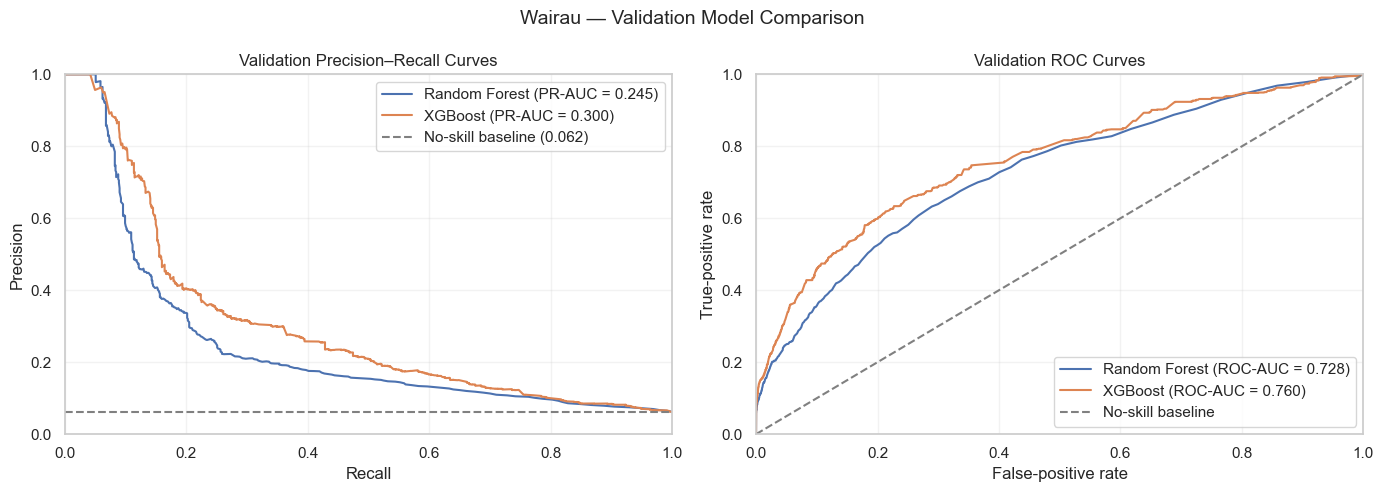

In [18]:
# Plot threshold-independent validation curves and the selected thresholds.

rf_precision_curve, rf_recall_curve, _ = precision_recall_curve(
    y_validation,
    rf_validation_probability
)

xgb_precision_curve, xgb_recall_curve, _ = precision_recall_curve(
    y_validation,
    xgb_validation_probability
)

rf_false_positive_rate, rf_true_positive_rate, _ = roc_curve(
    y_validation,
    rf_validation_probability
)

xgb_false_positive_rate, xgb_true_positive_rate, _ = roc_curve(
    y_validation,
    xgb_validation_probability
)

validation_prevalence = float(y_validation.mean())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Precision-recall curve.
axes[0].plot(
    rf_recall_curve,
    rf_precision_curve,
    label=(
        "Random Forest "
        f"(PR-AUC = "
        f"{average_precision_score(y_validation, rf_validation_probability):.3f})"
    )
)

axes[0].plot(
    xgb_recall_curve,
    xgb_precision_curve,
    label=(
        "XGBoost "
        f"(PR-AUC = "
        f"{average_precision_score(y_validation, xgb_validation_probability):.3f})"
    )
)

axes[0].axhline(
    validation_prevalence,
    color="grey",
    linestyle="--",
    label=f"No-skill baseline ({validation_prevalence:.3f})"
)

axes[0].set_title("Validation Precision–Recall Curves")
axes[0].set_xlabel("Recall")
axes[0].set_ylabel("Precision")
axes[0].set_xlim(0, 1)
axes[0].set_ylim(0, 1)
axes[0].grid(alpha=0.25)
axes[0].legend()

# ROC curve.
axes[1].plot(
    rf_false_positive_rate,
    rf_true_positive_rate,
    label=(
        "Random Forest "
        f"(ROC-AUC = "
        f"{roc_auc_score(y_validation, rf_validation_probability):.3f})"
    )
)

axes[1].plot(
    xgb_false_positive_rate,
    xgb_true_positive_rate,
    label=(
        "XGBoost "
        f"(ROC-AUC = "
        f"{roc_auc_score(y_validation, xgb_validation_probability):.3f})"
    )
)

axes[1].plot(
    [0, 1],
    [0, 1],
    color="grey",
    linestyle="--",
    label="No-skill baseline"
)

axes[1].set_title("Validation ROC Curves")
axes[1].set_xlabel("False-positive rate")
axes[1].set_ylabel("True-positive rate")
axes[1].set_xlim(0, 1)
axes[1].set_ylim(0, 1)
axes[1].grid(alpha=0.25)
axes[1].legend()

plt.suptitle(
    "Wairau — Validation Model Comparison",
    fontsize=14
)

plt.tight_layout()
plt.show()

## Final Evaluation on the Untouched Test Partition

XGBoost was selected using validation performance, and its probability threshold was frozen at the validation-derived value of 0.5129. The model is now evaluated once on the untouched chronological test partition.

No model parameters, class weights, boosting rounds, features, or probability thresholds are modified using test results. This provides an unbiased estimate of how the final Wairau model generalises to the most recent study period.

Because high-risk observations are uncommon, interpretation focuses on recall, precision, \(F_2\), balanced accuracy, ROC-AUC, and PR-AUC rather than overall accuracy alone.

In [19]:
from sklearn.metrics import fbeta_score

# Confirm that the validation-selected configuration is frozen.
assert WAIRAU_SELECTED_MODEL_NAME == "XGBoost"

FINAL_MODEL_NAME = WAIRAU_SELECTED_MODEL_NAME
FINAL_PROBABILITY_THRESHOLD = WAIRAU_SELECTED_THRESHOLD

print("Frozen final model:", FINAL_MODEL_NAME)
print(
    "Frozen validation-selected threshold:",
    f"{FINAL_PROBABILITY_THRESHOLD:.4f}"
)

# First and only generation of final test probabilities.
xgb_test_probability = wairau_selected_model.predict_proba(
    X_test
)[:, 1]

xgb_test_prediction = (
    xgb_test_probability >= FINAL_PROBABILITY_THRESHOLD
).astype("int8")

# Calculate final test metrics.
wairau_test_metrics = binary_classification_metrics(
    y_test,
    xgb_test_prediction,
    xgb_test_probability,
    "Test"
)

wairau_test_metrics.update({
    "model": FINAL_MODEL_NAME,
    "selected_threshold": FINAL_PROBABILITY_THRESHOLD,
    "f2_score": fbeta_score(
        y_test,
        xgb_test_prediction,
        beta=2,
        zero_division=0
    )
})

wairau_final_test_results = pd.DataFrame([
    wairau_test_metrics
])[
    [
        "model",
        "selected_threshold",
        "data_split",
        "rows",
        "actual_high_risk",
        "predicted_high_risk",
        "accuracy",
        "balanced_accuracy",
        "precision",
        "recall",
        "f1_score",
        "f2_score",
        "roc_auc",
        "pr_auc"
    ]
]

print("\nFinal untouched-test performance:")
display(
    wairau_final_test_results.style.format({
        "selected_threshold": "{:.4f}",
        "accuracy": "{:.3f}",
        "balanced_accuracy": "{:.3f}",
        "precision": "{:.3f}",
        "recall": "{:.3f}",
        "f1_score": "{:.3f}",
        "f2_score": "{:.3f}",
        "roc_auc": "{:.3f}",
        "pr_auc": "{:.3f}"
    })
)

# Final test confusion matrix.
wairau_test_confusion_matrix = pd.DataFrame(
    confusion_matrix(y_test, xgb_test_prediction),
    index=["Actual normal", "Actual high risk"],
    columns=["Predicted normal", "Predicted high risk"]
)

print("\nFinal test confusion matrix:")
display(wairau_test_confusion_matrix)

print("\nFinal test classification report:")
print(
    classification_report(
        y_test,
        xgb_test_prediction,
        target_names=["Normal", "High risk"],
        digits=3,
        zero_division=0
    )
)

# Compare validation and test performance at the same frozen threshold.
validation_final_metrics = (
    wairau_validation_model_comparison.loc[
        wairau_validation_model_comparison["model"].eq(
            FINAL_MODEL_NAME
        )
    ]
    .copy()
)

validation_final_metrics["data_split"] = "Validation"

validation_test_comparison = pd.concat(
    [
        validation_final_metrics[
            [
                "model",
                "selected_threshold",
                "data_split",
                "rows",
                "actual_high_risk",
                "predicted_high_risk",
                "accuracy",
                "balanced_accuracy",
                "precision",
                "recall",
                "f1_score",
                "f2_score",
                "roc_auc",
                "pr_auc"
            ]
        ],
        wairau_final_test_results
    ],
    ignore_index=True
)

print("\nValidation versus untouched-test performance:")
display(
    validation_test_comparison.style.format({
        "selected_threshold": "{:.4f}",
        "accuracy": "{:.3f}",
        "balanced_accuracy": "{:.3f}",
        "precision": "{:.3f}",
        "recall": "{:.3f}",
        "f1_score": "{:.3f}",
        "f2_score": "{:.3f}",
        "roc_auc": "{:.3f}",
        "pr_auc": "{:.3f}"
    })
)

# Store timestamp-level test outputs for later event analysis and export.
wairau_test_predictions = pd.DataFrame(
    {
        "observed_high_water_risk_24h": y_test.astype("int8"),
        "predicted_probability": xgb_test_probability,
        "predicted_high_water_risk_24h": xgb_test_prediction
    },
    index=test_timestamps
)

wairau_test_predictions.index.name = "timestamp"

# Retain useful hydrological context alongside each prediction.
for context_column in [
    "rainfall_mm",
    "discharge_m3s",
    "water_level_m"
]:
    wairau_test_predictions[context_column] = X_test[
        context_column
    ]

if "future_24h_max_water_level_m" in wairau_feature_data.columns:
    wairau_test_predictions[
        "future_24h_max_water_level_m"
    ] = wairau_feature_data.loc[
        wairau_test_predictions.index,
        "future_24h_max_water_level_m"
    ]

print("\nSample of final timestamp-level test predictions:")
display(wairau_test_predictions.head())

print(
    "\nFinal test evaluation completed without changing "
    "the fitted model or validation-selected threshold."
)

Frozen final model: XGBoost
Frozen validation-selected threshold: 0.5129

Final untouched-test performance:


,model,selected_threshold,data_split,rows,actual_high_risk,predicted_high_risk,accuracy,balanced_accuracy,precision,recall,f1_score,f2_score,roc_auc,pr_auc
0,XGBoost,0.5129,Test,14427,863,2484,0.819,0.635,0.148,0.425,0.219,0.309,0.714,0.222



Final test confusion matrix:


,Predicted normal,Predicted high risk
Actual normal,11447,2117
Actual high risk,496,367



Final test classification report:
              precision    recall  f1-score   support

      Normal      0.958     0.844     0.898     13564
   High risk      0.148     0.425     0.219       863

    accuracy                          0.819     14427
   macro avg      0.553     0.635     0.558     14427
weighted avg      0.910     0.819     0.857     14427


Validation versus untouched-test performance:


,model,selected_threshold,data_split,rows,actual_high_risk,predicted_high_risk,accuracy,balanced_accuracy,precision,recall,f1_score,f2_score,roc_auc,pr_auc
0,XGBoost,0.5129,Validation,14272,890,2910,0.806,0.701,0.178,0.581,0.272,0.400,0.760,0.300
1,XGBoost,0.5129,Test,14427,863,2484,0.819,0.635,0.148,0.425,0.219,0.309,0.714,0.222



Sample of final timestamp-level test predictions:


,observed_high_water_risk_24h,predicted_probability,predicted_high_water_risk_24h,rainfall_mm,discharge_m3s,water_level_m,future_24h_max_water_level_m
timestamp,,,,,,,
2024-05-08 08:00:00,0,0.458,0,0.000,0.026,0.087,0.135
2024-05-08 09:00:00,0,0.458,0,0.000,0.025,0.086,0.135
2024-05-08 10:00:00,0,0.458,0,0.000,0.026,0.087,0.135
2024-05-08 11:00:00,0,0.458,0,0.000,0.026,0.087,0.135
2024-05-08 12:00:00,0,0.458,0,0.000,0.024,0.085,0.135



Final test evaluation completed without changing the fitted model or validation-selected threshold.


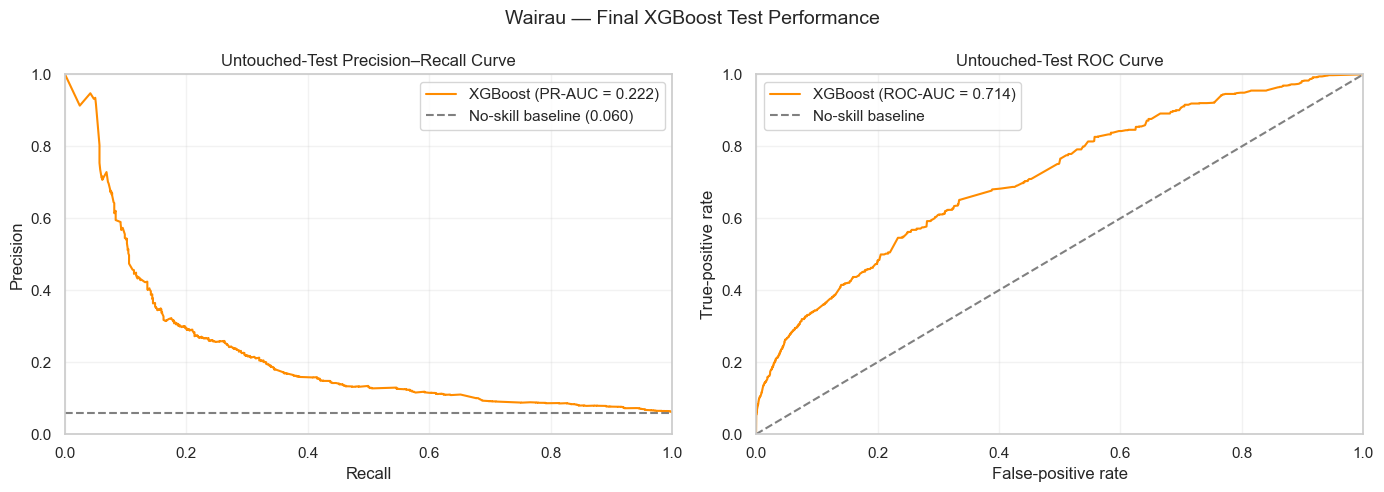

In [20]:
# Plot final test precision-recall and ROC curves.

test_precision_curve, test_recall_curve, _ = precision_recall_curve(
    y_test,
    xgb_test_probability
)

test_false_positive_rate, test_true_positive_rate, _ = roc_curve(
    y_test,
    xgb_test_probability
)

test_prevalence = float(y_test.mean())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    test_recall_curve,
    test_precision_curve,
    color="darkorange",
    label=(
        "XGBoost "
        f"(PR-AUC = "
        f"{average_precision_score(y_test, xgb_test_probability):.3f})"
    )
)

axes[0].axhline(
    test_prevalence,
    color="grey",
    linestyle="--",
    label=f"No-skill baseline ({test_prevalence:.3f})"
)

axes[0].set_title("Untouched-Test Precision–Recall Curve")
axes[0].set_xlabel("Recall")
axes[0].set_ylabel("Precision")
axes[0].set_xlim(0, 1)
axes[0].set_ylim(0, 1)
axes[0].grid(alpha=0.25)
axes[0].legend()

axes[1].plot(
    test_false_positive_rate,
    test_true_positive_rate,
    color="darkorange",
    label=(
        "XGBoost "
        f"(ROC-AUC = "
        f"{roc_auc_score(y_test, xgb_test_probability):.3f})"
    )
)

axes[1].plot(
    [0, 1],
    [0, 1],
    color="grey",
    linestyle="--",
    label="No-skill baseline"
)

axes[1].set_title("Untouched-Test ROC Curve")
axes[1].set_xlabel("False-positive rate")
axes[1].set_ylabel("True-positive rate")
axes[1].set_xlim(0, 1)
axes[1].set_ylim(0, 1)
axes[1].grid(alpha=0.25)
axes[1].legend()

plt.suptitle(
    "Wairau — Final XGBoost Test Performance",
    fontsize=14
)

plt.tight_layout()
plt.show()

## Test-Period Warning-Episode Analysis

Hourly high-water-risk labels and model warnings are grouped into contiguous episodes. A new episode begins whenever the binary status changes from inactive to active or whenever there is a break in the hourly timeline.

An observed risk episode is considered detected when at least one predicted warning hour overlaps it. A predicted warning episode is considered matched when it overlaps at least one observed risk episode; otherwise, it is counted as a false-warning episode.

This analysis complements the hourly classification metrics by showing whether the model detects distinct periods of elevated high-water risk, how much of each observed episode is covered, and how many separate false-warning episodes are generated. These episodes represent contiguous 24-hour risk-target windows rather than individual physical flood events.

In [21]:
def identify_binary_episodes(binary_series):
    """Identify contiguous active episodes in an hourly binary series."""
    
    series = (
        pd.Series(
            binary_series,
            index=binary_series.index
        )
        .sort_index()
        .astype(bool)
    )

    hourly_break = (
        series.index.to_series()
        .diff()
        .ne(pd.Timedelta(hours=1))
    )

    episode_start = (
        series
        & (
            ~series.shift(1, fill_value=False)
            | hourly_break
        )
    )

    episode_number = episode_start.cumsum()

    episode_frame = pd.DataFrame({
        "active": series,
        "episode_number": episode_number
    })

    active_rows = episode_frame.loc[
        episode_frame["active"]
    ].copy()

    if active_rows.empty:
        return pd.DataFrame(columns=[
            "episode_id",
            "episode_start",
            "episode_end",
            "episode_hours"
        ])

    episodes = (
        active_rows
        .groupby("episode_number")
        .agg(
            episode_start=("active", lambda values: values.index.min()),
            episode_end=("active", lambda values: values.index.max()),
            episode_hours=("active", "size")
        )
        .reset_index(drop=True)
    )

    episodes.insert(
        0,
        "episode_id",
        np.arange(1, len(episodes) + 1)
    )

    return episodes


# Identify observed and predicted risk episodes.
observed_test_risk_episodes = identify_binary_episodes(
    wairau_test_predictions["observed_high_water_risk_24h"]
)

predicted_test_warning_episodes = identify_binary_episodes(
    wairau_test_predictions["predicted_high_water_risk_24h"]
)

# Evaluate every observed risk episode.
observed_episode_diagnostics = []

for _, observed_episode in observed_test_risk_episodes.iterrows():
    observed_start = observed_episode["episode_start"]
    observed_end = observed_episode["episode_end"]

    overlapping_warnings = predicted_test_warning_episodes.loc[
        (
            predicted_test_warning_episodes["episode_start"]
            <= observed_end
        )
        & (
            predicted_test_warning_episodes["episode_end"]
            >= observed_start
        )
    ]

    observed_period = pd.date_range(
        observed_start,
        observed_end,
        freq="h"
    )

    period_predictions = (
        wairau_test_predictions[
            "predicted_high_water_risk_24h"
        ]
        .reindex(observed_period, fill_value=0)
    )

    period_probabilities = (
        wairau_test_predictions["predicted_probability"]
        .reindex(observed_period)
    )

    detected = not overlapping_warnings.empty
    covered_hours = int(period_predictions.sum())

    if detected:
        first_warning = overlapping_warnings[
            "episode_start"
        ].min()

        first_warning_offset_hours = (
            first_warning - observed_start
        ) / pd.Timedelta(hours=1)
    else:
        first_warning = pd.NaT
        first_warning_offset_hours = np.nan

    observed_episode_diagnostics.append({
        "observed_episode_id": int(
            observed_episode["episode_id"]
        ),
        "observed_start": observed_start,
        "observed_end": observed_end,
        "observed_hours": int(
            observed_episode["episode_hours"]
        ),
        "detected": detected,
        "warning_hours_during_episode": covered_hours,
        "episode_coverage_percentage": (
            100
            * covered_hours
            / observed_episode["episode_hours"]
        ),
        "first_overlapping_warning": first_warning,
        "first_warning_offset_hours": (
            first_warning_offset_hours
        ),
        "maximum_predicted_probability": (
            period_probabilities.max()
        )
    })

wairau_observed_episode_diagnostics = pd.DataFrame(
    observed_episode_diagnostics
)

# Determine whether each predicted warning episode was matched.
predicted_episode_diagnostics = []

for _, predicted_episode in predicted_test_warning_episodes.iterrows():
    predicted_start = predicted_episode["episode_start"]
    predicted_end = predicted_episode["episode_end"]

    overlapping_observed_events = observed_test_risk_episodes.loc[
        (
            observed_test_risk_episodes["episode_start"]
            <= predicted_end
        )
        & (
            observed_test_risk_episodes["episode_end"]
            >= predicted_start
        )
    ]

    warning_period = pd.date_range(
        predicted_start,
        predicted_end,
        freq="h"
    )

    warning_probabilities = (
        wairau_test_predictions["predicted_probability"]
        .reindex(warning_period)
    )

    predicted_episode_diagnostics.append({
        "predicted_episode_id": int(
            predicted_episode["episode_id"]
        ),
        "warning_start": predicted_start,
        "warning_end": predicted_end,
        "warning_hours": int(
            predicted_episode["episode_hours"]
        ),
        "matched_observed_episode": (
            not overlapping_observed_events.empty
        ),
        "number_of_overlapping_observed_episodes": len(
            overlapping_observed_events
        ),
        "maximum_predicted_probability": (
            warning_probabilities.max()
        )
    })

wairau_predicted_episode_diagnostics = pd.DataFrame(
    predicted_episode_diagnostics
)

# Episode-level summary statistics.
observed_episode_count = len(
    wairau_observed_episode_diagnostics
)

detected_episode_count = int(
    wairau_observed_episode_diagnostics["detected"].sum()
)

missed_episode_count = (
    observed_episode_count - detected_episode_count
)

predicted_episode_count = len(
    wairau_predicted_episode_diagnostics
)

matched_warning_episode_count = int(
    wairau_predicted_episode_diagnostics[
        "matched_observed_episode"
    ].sum()
)

false_warning_episode_count = (
    predicted_episode_count - matched_warning_episode_count
)

wairau_test_episode_summary = pd.DataFrame([{
    "observed_risk_episodes": observed_episode_count,
    "detected_risk_episodes": detected_episode_count,
    "missed_risk_episodes": missed_episode_count,
    "episode_recall": (
        detected_episode_count / observed_episode_count
        if observed_episode_count > 0 else np.nan
    ),
    "predicted_warning_episodes": predicted_episode_count,
    "matched_warning_episodes": matched_warning_episode_count,
    "false_warning_episodes": false_warning_episode_count,
    "warning_episode_precision": (
        matched_warning_episode_count / predicted_episode_count
        if predicted_episode_count > 0 else np.nan
    ),
    "median_observed_episode_coverage_percentage": (
        wairau_observed_episode_diagnostics[
            "episode_coverage_percentage"
        ].median()
        if observed_episode_count > 0 else np.nan
    )
}])

print("Final test warning-episode summary:")
display(
    wairau_test_episode_summary.style.format({
        "episode_recall": "{:.3f}",
        "warning_episode_precision": "{:.3f}",
        "median_observed_episode_coverage_percentage": "{:.1f}"
    })
)

print("\nObserved risk-episode diagnostics:")
display(
    wairau_observed_episode_diagnostics.style.format({
        "episode_coverage_percentage": "{:.1f}",
        "first_warning_offset_hours": "{:.1f}",
        "maximum_predicted_probability": "{:.3f}"
    })
)

print("\nPredicted warning-episode diagnostics:")
display(
    wairau_predicted_episode_diagnostics.style.format({
        "maximum_predicted_probability": "{:.3f}"
    })
)

print("\nMissed observed risk episodes:")
display(
    wairau_observed_episode_diagnostics.loc[
        ~wairau_observed_episode_diagnostics["detected"]
    ]
)

print("\nFalse-warning episodes:")
display(
    wairau_predicted_episode_diagnostics.loc[
        ~wairau_predicted_episode_diagnostics[
            "matched_observed_episode"
        ]
    ]
)

Final test warning-episode summary:


,observed_risk_episodes,detected_risk_episodes,missed_risk_episodes,episode_recall,predicted_warning_episodes,matched_warning_episodes,false_warning_episodes,warning_episode_precision,median_observed_episode_coverage_percentage
0,31,31,0,1.000,429,60,369,0.140,41.2



Observed risk-episode diagnostics:


,observed_episode_id,observed_start,observed_end,observed_hours,detected,warning_hours_during_episode,episode_coverage_percentage,first_overlapping_warning,first_warning_offset_hours,maximum_predicted_probability
0,1,2024-05-19 22:00:00,2024-05-21 00:00:00,27,True,6,22.2,2024-05-20 19:00:00,21.0,0.592
1,2,2024-06-13 03:00:00,2024-06-14 12:00:00,34,True,14,41.2,2024-06-13 23:00:00,20.0,0.592
2,3,2024-06-15 21:00:00,2024-06-17 00:00:00,28,True,5,17.9,2024-06-16 20:00:00,23.0,0.592
3,4,2024-06-22 04:00:00,2024-06-23 04:00:00,25,True,11,44.0,2024-06-22 18:00:00,14.0,0.591
4,5,2024-07-19 04:00:00,2024-07-20 05:00:00,26,True,17,65.4,2024-07-19 04:00:00,0.0,0.591
5,6,2024-08-30 10:00:00,2024-09-01 04:00:00,43,True,17,39.5,2024-08-31 09:00:00,23.0,0.591
6,7,2024-10-01 22:00:00,2024-10-03 04:00:00,31,True,9,29.0,2024-10-02 20:00:00,22.0,0.592
7,8,2024-12-08 21:00:00,2024-12-09 21:00:00,25,True,4,16.0,2024-12-09 18:00:00,21.0,0.591
8,9,2024-12-10 21:00:00,2024-12-11 22:00:00,26,True,4,15.4,2024-12-11 19:00:00,22.0,0.592
9,10,2025-04-03 06:00:00,2025-04-04 06:00:00,25,True,18,72.0,2025-04-03 07:00:00,1.0,0.592



Predicted warning-episode diagnostics:


,predicted_episode_id,warning_start,warning_end,warning_hours,matched_observed_episode,number_of_overlapping_observed_episodes,maximum_predicted_probability
0,1,2024-05-15 02:00:00,2024-05-15 02:00:00,1,False,0,0.526
1,2,2024-05-15 05:00:00,2024-05-15 08:00:00,4,False,0,0.579
2,3,2024-05-15 11:00:00,2024-05-15 11:00:00,1,False,0,0.514
3,4,2024-05-15 13:00:00,2024-05-15 15:00:00,3,False,0,0.535
4,5,2024-05-16 06:00:00,2024-05-16 10:00:00,5,False,0,0.546
5,6,2024-05-20 19:00:00,2024-05-21 10:00:00,16,True,1,0.592
6,7,2024-05-24 12:00:00,2024-05-24 14:00:00,3,False,0,0.528
7,8,2024-05-24 16:00:00,2024-05-24 18:00:00,3,False,0,0.539
8,9,2024-05-24 20:00:00,2024-05-24 20:00:00,1,False,0,0.528
9,10,2024-05-24 22:00:00,2024-05-24 22:00:00,1,False,0,0.514



Missed observed risk episodes:


,observed_episode_id,observed_start,observed_end,observed_hours,detected,warning_hours_during_episode,episode_coverage_percentage,first_overlapping_warning,first_warning_offset_hours,maximum_predicted_probability



False-warning episodes:


,predicted_episode_id,warning_start,warning_end,warning_hours,matched_observed_episode,number_of_overlapping_observed_episodes,maximum_predicted_probability
0,1,2024-05-15 02:00:00,2024-05-15 02:00:00,1,False,0,0.526
1,2,2024-05-15 05:00:00,2024-05-15 08:00:00,4,False,0,0.579
2,3,2024-05-15 11:00:00,2024-05-15 11:00:00,1,False,0,0.514
3,4,2024-05-15 13:00:00,2024-05-15 15:00:00,3,False,0,0.535
4,5,2024-05-16 06:00:00,2024-05-16 10:00:00,5,False,0,0.546
...,...,...,...,...,...,...,...
422,423,2025-12-24 08:00:00,2025-12-24 13:00:00,6,False,0,0.569
423,424,2025-12-26 17:00:00,2025-12-26 19:00:00,3,False,0,0.550
424,425,2025-12-27 11:00:00,2025-12-27 11:00:00,1,False,0,0.516
425,426,2025-12-29 04:00:00,2025-12-29 04:00:00,1,False,0,0.530


## Physical High-Water Event Detection and Warning Lead Time

The previous episode analysis grouped the derived 24-hour risk target. Because those risk windows begin before the water level actually exceeds the threshold, any overlap can overstate operational event detection.

This analysis instead identifies physical high-water events directly from consecutive test-period observations above the frozen 0.924 m training-derived threshold. For each physical event, model warnings during the preceding 24 hours are examined.

An event is considered detected in advance only when at least one positive model warning occurs between 24 hours and 1 hour before the first threshold exceedance. Lead time is measured from the earliest qualifying warning to the beginning of the physical event.

The fitted model and probability threshold remain unchanged. This is a diagnostic evaluation, not additional model or threshold tuning.

In [22]:
# Frozen training-derived physical high-water threshold.
WAIRAU_HIGH_WATER_THRESHOLD_M = 0.924

# Use the complete test-period water-level series to identify
# physical exceedance events.
test_water_level_series = (
    wairau_feature_data.loc[
        wairau_feature_data["data_split"].eq("Test"),
        "water_level_m"
    ]
    .sort_index()
    .dropna()
)

test_physical_exceedance = (
    test_water_level_series
    > WAIRAU_HIGH_WATER_THRESHOLD_M
).astype("int8")

wairau_test_physical_events = identify_binary_episodes(
    test_physical_exceedance
)

physical_event_diagnostics = []

for _, event in wairau_test_physical_events.iterrows():
    event_start = event["episode_start"]
    event_end = event["episode_end"]

    # Strictly advance-warning period: 24 h to 1 h before event.
    warning_window_start = event_start - pd.Timedelta(hours=24)
    warning_window_end = event_start - pd.Timedelta(hours=1)

    pre_event_predictions = wairau_test_predictions.loc[
        (
            wairau_test_predictions.index
            >= warning_window_start
        )
        & (
            wairau_test_predictions.index
            <= warning_window_end
        )
    ].copy()

    positive_advance_warnings = pre_event_predictions.loc[
        pre_event_predictions[
            "predicted_high_water_risk_24h"
        ].eq(1)
    ]

    detected_in_advance = not positive_advance_warnings.empty

    if detected_in_advance:
        first_advance_warning = (
            positive_advance_warnings.index.min()
        )

        warning_lead_hours = (
            event_start - first_advance_warning
        ) / pd.Timedelta(hours=1)

        final_advance_warning = (
            positive_advance_warnings.index.max()
        )

        final_warning_lead_hours = (
            event_start - final_advance_warning
        ) / pd.Timedelta(hours=1)
    else:
        first_advance_warning = pd.NaT
        warning_lead_hours = np.nan
        final_advance_warning = pd.NaT
        final_warning_lead_hours = np.nan

    event_water_levels = test_water_level_series.loc[
        event_start:event_end
    ]

    physical_event_diagnostics.append({
        "event_id": int(event["episode_id"]),
        "event_start": event_start,
        "event_end": event_end,
        "exceedance_hours": int(event["episode_hours"]),
        "maximum_water_level_m": event_water_levels.max(),
        "detected_in_advance": detected_in_advance,
        "advance_warning_hours": int(
            len(positive_advance_warnings)
        ),
        "first_advance_warning": first_advance_warning,
        "maximum_lead_time_hours": warning_lead_hours,
        "last_advance_warning": final_advance_warning,
        "minimum_lead_time_hours": final_warning_lead_hours,
        "maximum_pre_event_probability": (
            pre_event_predictions[
                "predicted_probability"
            ].max()
            if not pre_event_predictions.empty
            else np.nan
        )
    })

wairau_physical_event_diagnostics = pd.DataFrame(
    physical_event_diagnostics
)

physical_event_count = len(
    wairau_physical_event_diagnostics
)

advance_detected_count = int(
    wairau_physical_event_diagnostics[
        "detected_in_advance"
    ].sum()
)

missed_in_advance_count = (
    physical_event_count - advance_detected_count
)

detected_event_rows = (
    wairau_physical_event_diagnostics.loc[
        wairau_physical_event_diagnostics[
            "detected_in_advance"
        ]
    ]
)

wairau_physical_event_summary = pd.DataFrame([{
    "physical_high_water_events": physical_event_count,
    "events_detected_in_advance": advance_detected_count,
    "events_missed_in_advance": missed_in_advance_count,
    "advance_event_recall": (
        advance_detected_count / physical_event_count
        if physical_event_count > 0 else np.nan
    ),
    "median_maximum_lead_time_hours": (
        detected_event_rows[
            "maximum_lead_time_hours"
        ].median()
        if not detected_event_rows.empty else np.nan
    ),
    "minimum_maximum_lead_time_hours": (
        detected_event_rows[
            "maximum_lead_time_hours"
        ].min()
        if not detected_event_rows.empty else np.nan
    ),
    "maximum_maximum_lead_time_hours": (
        detected_event_rows[
            "maximum_lead_time_hours"
        ].max()
        if not detected_event_rows.empty else np.nan
    )
}])

print("Physical high-water event warning summary:")
display(
    wairau_physical_event_summary.style.format({
        "advance_event_recall": "{:.3f}",
        "median_maximum_lead_time_hours": "{:.1f}",
        "minimum_maximum_lead_time_hours": "{:.1f}",
        "maximum_maximum_lead_time_hours": "{:.1f}"
    })
)

print("\nPhysical high-water event diagnostics:")
display(
    wairau_physical_event_diagnostics.style.format({
        "maximum_water_level_m": "{:.3f}",
        "maximum_lead_time_hours": "{:.1f}",
        "minimum_lead_time_hours": "{:.1f}",
        "maximum_pre_event_probability": "{:.3f}"
    })
)

print("\nPhysical events missed by all advance warnings:")
display(
    wairau_physical_event_diagnostics.loc[
        ~wairau_physical_event_diagnostics[
            "detected_in_advance"
        ]
    ]
)

print(
    "\nNo model parameters or decision thresholds were "
    "changed during this physical-event analysis."
)

Physical high-water event warning summary:


,physical_high_water_events,events_detected_in_advance,events_missed_in_advance,advance_event_recall,median_maximum_lead_time_hours,minimum_maximum_lead_time_hours,maximum_maximum_lead_time_hours
0,42,40,2,0.952,12.5,1.0,24.0



Physical high-water event diagnostics:


,event_id,event_start,event_end,exceedance_hours,maximum_water_level_m,detected_in_advance,advance_warning_hours,first_advance_warning,maximum_lead_time_hours,last_advance_warning,minimum_lead_time_hours,maximum_pre_event_probability
0,1,2024-05-20 22:00:00,2024-05-21 01:00:00,4,1.733,True,3,2024-05-20 19:00:00,3.0,2024-05-20 21:00:00,1.0,0.576
1,2,2024-06-14 03:00:00,2024-06-14 05:00:00,3,1.865,True,4,2024-06-13 23:00:00,4.0,2024-06-14 02:00:00,1.0,0.568
2,3,2024-06-14 12:00:00,2024-06-14 13:00:00,2,1.572,True,13,2024-06-13 23:00:00,13.0,2024-06-14 11:00:00,1.0,0.592
3,4,2024-06-16 21:00:00,2024-06-17 01:00:00,5,1.620,True,1,2024-06-16 20:00:00,1.0,2024-06-16 20:00:00,1.0,0.564
4,5,2024-06-23 04:00:00,2024-06-23 05:00:00,2,1.246,True,10,2024-06-22 18:00:00,10.0,2024-06-23 03:00:00,1.0,0.576
5,6,2024-07-20 04:00:00,2024-07-20 06:00:00,3,1.101,True,15,2024-07-19 04:00:00,24.0,2024-07-20 03:00:00,1.0,0.568
6,7,2024-08-31 10:00:00,2024-08-31 11:00:00,2,1.090,True,1,2024-08-31 09:00:00,1.0,2024-08-31 09:00:00,1.0,0.580
7,8,2024-09-01 04:00:00,2024-09-01 05:00:00,2,1.249,True,16,2024-08-31 09:00:00,19.0,2024-09-01 03:00:00,1.0,0.591
8,9,2024-10-02 22:00:00,2024-10-03 00:00:00,3,1.177,True,2,2024-10-02 20:00:00,2.0,2024-10-02 21:00:00,1.0,0.560
9,10,2024-10-03 03:00:00,2024-10-03 05:00:00,3,1.555,True,7,2024-10-02 20:00:00,7.0,2024-10-03 02:00:00,1.0,0.591



Physical events missed by all advance warnings:


,event_id,event_start,event_end,exceedance_hours,maximum_water_level_m,detected_in_advance,advance_warning_hours,first_advance_warning,maximum_lead_time_hours,last_advance_warning,minimum_lead_time_hours,maximum_pre_event_probability
32,33,2025-08-23 22:00:00,2025-08-23 23:00:00,2,1.076,False,0,NaT,NaN,NaT,NaN,0.491
34,35,2025-10-23 23:00:00,2025-10-24 00:00:00,2,1.012,False,0,NaT,NaN,NaT,NaN,0.496



No model parameters or decision thresholds were changed during this physical-event analysis.


## Wairau Model Conclusions

The final Wairau XGBoost classifier achieved moderate hourly discrimination on the untouched test period, with a ROC-AUC of 0.714 and PR-AUC of 0.222 compared with a no-skill PR-AUC baseline of approximately 0.060. At the validation-selected probability threshold of 0.5129, hourly high-risk recall was 42.5%, precision was 14.8%, and the \(F_2\) score was 0.309.

Hourly performance declined relative to validation, indicating temporal distribution change and limited generalisation to the most recent period. The model also produced many false-positive and fragmented warning hours. Therefore, individual hourly classifications should not be interpreted as precise flood alarms.

However, physical-event analysis produced substantially stronger operational results. Of 42 distinct test-period water-level exceedance events, 40 received at least one warning during the preceding 24 hours, corresponding to an advance-event recall of 95.2%. The median earliest warning lead time was 12.5 hours, with detected-event lead times ranging from 1 to 24 hours.

The two missed events were brief two-hour exceedances, with maximum water levels of 1.076 m and 1.012 m. Their maximum pre-event probabilities were 0.491 and 0.496, slightly below the frozen 0.5129 threshold. The threshold was not changed after examining the test results.

Overall, the model is more suitable as an early-warning decision-support indicator than as a standalone automated alarm. Its probabilities should be interpreted alongside current water level, river discharge, rainfall, warning persistence, and catchment-manager judgement.

## Reproducible Output and Model Export

The cleaned feature dataset, chronological model-ready data, fitted XGBoost model, frozen configuration, evaluation metrics, feature importance, timestamp-level test predictions, and event diagnostics are exported for reproducibility and later dashboard integration.

The exported model is the exact fitted model evaluated on the untouched test partition. It is not retrained after test evaluation.

In [23]:
from pathlib import Path
import json

# Create a dedicated Wairau output directory.
wairau_output_directory = (
    Path.home()
    / "Downloads"
    / "Wairau_Model_Outputs"
)

wairau_output_directory.mkdir(
    parents=True,
    exist_ok=True
)

# Combine the model-ready chronological partitions.
model_ready_export_frames = []

for split_name, split_frame in split_datasets.items():
    export_frame = split_frame.copy()
    export_frame.insert(0, "data_split", split_name)
    model_ready_export_frames.append(export_frame)

wairau_model_ready_data = pd.concat(
    model_ready_export_frames
).sort_index()

wairau_model_ready_data.index.name = "timestamp"

# Consolidate initial model metrics.
wairau_initial_model_metrics = pd.concat(
    [
        rf_initial_metrics.assign(model="Random Forest"),
        xgb_initial_metrics.assign(model="XGBoost")
    ],
    ignore_index=True
)

# Export datasets and tabular results.
csv_exports = {
    "wairau_feature_engineered_hourly.csv":
        wairau_feature_data,

    "wairau_model_ready_data.csv":
        wairau_model_ready_data,

    "wairau_model_ready_summary.csv":
        wairau_model_ready_summary,

    "wairau_initial_model_metrics.csv":
        wairau_initial_model_metrics,

    "wairau_validation_model_comparison.csv":
        wairau_validation_model_comparison,

    "wairau_final_test_results.csv":
        wairau_final_test_results,

    "wairau_validation_test_comparison.csv":
        validation_test_comparison,

    "wairau_xgboost_feature_importance.csv":
        wairau_xgb_feature_importance,

    "wairau_random_forest_feature_importance.csv":
        wairau_rf_feature_importance,

    "wairau_test_predictions.csv":
        wairau_test_predictions,

    "wairau_test_risk_episode_summary.csv":
        wairau_test_episode_summary,

    "wairau_observed_risk_episode_diagnostics.csv":
        wairau_observed_episode_diagnostics,

    "wairau_predicted_warning_episode_diagnostics.csv":
        wairau_predicted_episode_diagnostics,

    "wairau_physical_event_summary.csv":
        wairau_physical_event_summary,

    "wairau_physical_event_diagnostics.csv":
        wairau_physical_event_diagnostics
}

export_manifest_rows = []

for filename, dataframe in csv_exports.items():
    export_path = wairau_output_directory / filename

    dataframe.to_csv(
        export_path,
        index=True
    )

    export_manifest_rows.append({
        "file": filename,
        "type": "CSV",
        "rows": len(dataframe),
        "path": str(export_path)
    })

# Save the exact fitted and evaluated XGBoost model.
xgboost_model_path = (
    wairau_output_directory
    / "wairau_final_xgboost_model.json"
)

wairau_selected_model.save_model(
    xgboost_model_path
)

export_manifest_rows.append({
    "file": xgboost_model_path.name,
    "type": "XGBoost model",
    "rows": np.nan,
    "path": str(xgboost_model_path)
})

# Extract final scalar results for portable metadata.
final_test_row = (
    wairau_final_test_results.iloc[0]
)

physical_summary_row = (
    wairau_physical_event_summary.iloc[0]
)

wairau_model_metadata = {
    "catchment": "Wairau",
    "task": (
        "Predict whether water level will exceed the "
        "training-derived high-water threshold within 24 hours"
    ),
    "model": FINAL_MODEL_NAME,
    "model_file": xgboost_model_path.name,
    "feature_count": len(WAIRAU_MODEL_FEATURES),
    "features": list(WAIRAU_MODEL_FEATURES),
    "target": WAIRAU_TARGET_COLUMN,
    "training_derived_high_water_threshold_m": float(
        WAIRAU_HIGH_WATER_THRESHOLD_M
    ),
    "validation_selected_probability_threshold": float(
        FINAL_PROBABILITY_THRESHOLD
    ),
    "threshold_selection_metric": "F2 score",
    "training_class_weight_ratio": float(
        wairau_scale_pos_weight
    ),
    "best_boosting_iteration": (
        int(wairau_xgboost.best_iteration)
        if getattr(
            wairau_xgboost,
            "best_iteration",
            None
        ) is not None
        else None
    ),
    "chronological_splits": {
        "training": {
            "beginning": "2015-01-01 01:00:00",
            "ending": "2022-09-13 14:00:00"
        },
        "validation": {
            "beginning": "2022-09-13 15:00:00",
            "ending": "2024-05-08 07:00:00"
        },
        "test": {
            "beginning": "2024-05-08 08:00:00",
            "ending": "2026-01-01 00:00:00"
        }
    },
    "final_test_metrics": {
        "rows": int(final_test_row["rows"]),
        "actual_high_risk_hours": int(
            final_test_row["actual_high_risk"]
        ),
        "predicted_high_risk_hours": int(
            final_test_row["predicted_high_risk"]
        ),
        "accuracy": float(final_test_row["accuracy"]),
        "balanced_accuracy": float(
            final_test_row["balanced_accuracy"]
        ),
        "precision": float(final_test_row["precision"]),
        "recall": float(final_test_row["recall"]),
        "f1_score": float(final_test_row["f1_score"]),
        "f2_score": float(final_test_row["f2_score"]),
        "roc_auc": float(final_test_row["roc_auc"]),
        "pr_auc": float(final_test_row["pr_auc"])
    },
    "physical_event_metrics": {
        "physical_high_water_events": int(
            physical_summary_row[
                "physical_high_water_events"
            ]
        ),
        "events_detected_in_advance": int(
            physical_summary_row[
                "events_detected_in_advance"
            ]
        ),
        "events_missed_in_advance": int(
            physical_summary_row[
                "events_missed_in_advance"
            ]
        ),
        "advance_event_recall": float(
            physical_summary_row[
                "advance_event_recall"
            ]
        ),
        "median_maximum_lead_time_hours": float(
            physical_summary_row[
                "median_maximum_lead_time_hours"
            ]
        )
    },
    "methodological_notes": [
        "High-water threshold derived from training data only.",
        "Chronological 70/15/15 split used.",
        "No mean, median, or moving-average imputation used.",
        "Supporting-station conversions fitted using training data only.",
        "Validation used for early stopping and probability-threshold selection.",
        "Test data used once for final evaluation.",
        "Model was not refitted or modified after test evaluation."
    ]
}

metadata_path = (
    wairau_output_directory
    / "wairau_model_metadata.json"
)

with metadata_path.open(
    "w",
    encoding="utf-8"
) as metadata_file:
    json.dump(
        wairau_model_metadata,
        metadata_file,
        indent=4
    )

export_manifest_rows.append({
    "file": metadata_path.name,
    "type": "JSON metadata",
    "rows": np.nan,
    "path": str(metadata_path)
})

# Save an export manifest.
wairau_export_manifest = pd.DataFrame(
    export_manifest_rows
)

manifest_path = (
    wairau_output_directory
    / "wairau_export_manifest.csv"
)

wairau_export_manifest.to_csv(
    manifest_path,
    index=False
)

print(
    "Wairau model outputs exported to:\n",
    wairau_output_directory
)

print("\nExport manifest:")
display(wairau_export_manifest)

print(
    "\nFinal model and evaluation artifacts were exported "
    "without retraining or modifying the tested model."
)

Wairau model outputs exported to:
 C:\Users\kgeet\Downloads\Wairau_Model_Outputs

Export manifest:


,file,type,rows,path
0,wairau_feature_engineered_hourly.csv,CSV,"96,432.000",C:\Users\kgeet\Downloads\Wairau_Model_Outputs\...
1,wairau_model_ready_data.csv,CSV,"94,643.000",C:\Users\kgeet\Downloads\Wairau_Model_Outputs\...
2,wairau_model_ready_summary.csv,CSV,3.000,C:\Users\kgeet\Downloads\Wairau_Model_Outputs\...
3,wairau_initial_model_metrics.csv,CSV,4.000,C:\Users\kgeet\Downloads\Wairau_Model_Outputs\...
4,wairau_validation_model_comparison.csv,CSV,2.000,C:\Users\kgeet\Downloads\Wairau_Model_Outputs\...
5,wairau_final_test_results.csv,CSV,1.000,C:\Users\kgeet\Downloads\Wairau_Model_Outputs\...
6,wairau_validation_test_comparison.csv,CSV,2.000,C:\Users\kgeet\Downloads\Wairau_Model_Outputs\...
7,wairau_xgboost_feature_importance.csv,CSV,30.000,C:\Users\kgeet\Downloads\Wairau_Model_Outputs\...
8,wairau_random_forest_feature_importance.csv,CSV,30.000,C:\Users\kgeet\Downloads\Wairau_Model_Outputs\...
9,wairau_test_predictions.csv,CSV,"14,427.000",C:\Users\kgeet\Downloads\Wairau_Model_Outputs\...



Final model and evaluation artifacts were exported without retraining or modifying the tested model.


In [24]:
# Wairau - Gaussian Naive Bayes setup

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    confusion_matrix,
    classification_report
)

print("Training matrix:", X_train.shape)
print("Validation matrix:", X_validation.shape)
print("Test matrix:", X_test.shape)

print("\nTraining high-risk rows:", int(y_train.sum()))
print("Validation high-risk rows:", int(y_validation.sum()))
print("Test high-risk rows:", int(y_test.sum()))

Training matrix: (65944, 30)
Validation matrix: (14272, 30)
Test matrix: (14427, 30)

Training high-risk rows: 3361
Validation high-risk rows: 890
Test high-risk rows: 863


In [26]:
# Tune var_smoothing and probability threshold using validation F2

var_smoothing_values = np.logspace(-12, 8, 41)

naive_bayes_tuning_results = []

for var_smoothing in var_smoothing_values:

    candidate_model = Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "naive_bayes",
            GaussianNB(
                var_smoothing=var_smoothing
            )
        )
    ])

    candidate_model.fit(
        X_train,
        y_train
    )

    validation_probability = (
        candidate_model.predict_proba(
            X_validation
        )[:, 1]
    )

    precision, recall, thresholds = precision_recall_curve(
        y_validation,
        validation_probability
    )

    precision = precision[:-1]
    recall = recall[:-1]

    f2_scores = (
        5 * precision * recall
        / (
            4 * precision
            + recall
            + 1e-12
        )
    )

    best_position = np.argmax(f2_scores)
    selected_threshold = thresholds[best_position]

    naive_bayes_tuning_results.append({
        "var_smoothing": var_smoothing,
        "selected_threshold": selected_threshold,
        "validation_precision": precision[best_position],
        "validation_recall": recall[best_position],
        "validation_f2": f2_scores[best_position],
        "validation_roc_auc": roc_auc_score(
            y_validation,
            validation_probability
        ),
        "validation_pr_auc": average_precision_score(
            y_validation,
            validation_probability
        )
    })

naive_bayes_tuning_results = pd.DataFrame(
    naive_bayes_tuning_results
)

best_tuning_row = (
    naive_bayes_tuning_results
    .sort_values(
        by=[
            "validation_f2",
            "validation_pr_auc"
        ],
        ascending=False
    )
    .iloc[0]
)

best_var_smoothing = float(
    best_tuning_row["var_smoothing"]
)

selected_probability_threshold = float(
    best_tuning_row["selected_threshold"]
)

print(
    "Selected var_smoothing:",
    f"{best_var_smoothing:.3e}"
)

print(
    "Selected probability threshold:",
    f"{selected_probability_threshold:.6e}"
)

print(
    "Maximum validation F2:",
    f"{best_tuning_row['validation_f2']:.4f}"
)

print("\nTop validation results:")

display(
    naive_bayes_tuning_results
    .sort_values(
        by=[
            "validation_f2",
            "validation_pr_auc"
        ],
        ascending=False
    )
    .head(10)
    .style.format({
        "var_smoothing": "{:.3e}",
        "selected_threshold": "{:.6e}",
        "validation_precision": "{:.4f}",
        "validation_recall": "{:.4f}",
        "validation_f2": "{:.4f}",
        "validation_roc_auc": "{:.4f}",
        "validation_pr_auc": "{:.4f}"
    })
)

Selected var_smoothing: 1.000e+07
Selected probability threshold: 5.096712e-02
Maximum validation F2: 0.3919

Top validation results:


,var_smoothing,selected_threshold,validation_precision,validation_recall,validation_f2,validation_roc_auc,validation_pr_auc
38,1.000e+07,5.096712e-02,0.1761,0.5652,0.3919,0.7517,0.3008
39,3.162e+07,5.096737e-02,0.1761,0.5652,0.3919,0.7517,0.3008
40,1.000e+08,5.096745e-02,0.1761,0.5652,0.3919,0.7517,0.3008
37,3.162e+06,5.096633e-02,0.1761,0.5652,0.3919,0.7517,0.3008
36,1.000e+06,5.096384e-02,0.1761,0.5652,0.3919,0.7517,0.3008
35,3.162e+05,5.095594e-02,0.1761,0.5652,0.3919,0.7517,0.3008
34,1.000e+05,5.093097e-02,0.1760,0.5652,0.3919,0.7517,0.3008
33,3.162e+04,5.085212e-02,0.1760,0.5652,0.3919,0.7517,0.3008
32,1.000e+04,5.060362e-02,0.1759,0.5652,0.3918,0.7517,0.3007
31,3.162e+03,4.983363e-02,0.1806,0.5528,0.3914,0.7516,0.3005


In [30]:
# Fit the selected Gaussian Naive Bayes model

naive_bayes_model = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "naive_bayes",
        GaussianNB(
            var_smoothing=best_var_smoothing
        )
    )
])

naive_bayes_model.fit(
    X_train,
    y_train
)

training_probability = (
    naive_bayes_model.predict_proba(
        X_train
    )[:, 1]
)

validation_probability = (
    naive_bayes_model.predict_proba(
        X_validation
    )[:, 1]
)

training_prediction = (
    training_probability
    >= selected_probability_threshold
).astype(int)

validation_prediction = (
    validation_probability
    >= selected_probability_threshold
).astype(int)

print("Gaussian Naive Bayes fitted successfully.")

print(
    "Selected var_smoothing:",
    f"{best_var_smoothing:.3e}"
)

print(
    "Frozen validation-selected threshold:",
    f"{selected_probability_threshold:.6e}"
)

print("Training probabilities:", len(training_probability))
print("Validation probabilities:", len(validation_probability))

Gaussian Naive Bayes fitted successfully.
Selected var_smoothing: 1.000e+07
Frozen validation-selected threshold: 5.096712e-02
Training probabilities: 65944
Validation probabilities: 14272


In [31]:
# Evaluate Gaussian Naive Bayes on the validation dataset

validation_confusion = confusion_matrix(
    y_validation,
    validation_prediction
)

tn, fp, fn, tp = validation_confusion.ravel()

naive_bayes_validation_results = pd.DataFrame({
    "metric": [
        "selected_threshold",
        "accuracy",
        "balanced_accuracy",
        "precision",
        "recall",
        "f1_score",
        "f2_score",
        "roc_auc",
        "pr_auc",
        "true_negatives",
        "false_positives",
        "false_negatives",
        "true_positives"
    ],
    "value": [
        selected_probability_threshold,
        accuracy_score(
            y_validation,
            validation_prediction
        ),
        balanced_accuracy_score(
            y_validation,
            validation_prediction
        ),
        precision_score(
            y_validation,
            validation_prediction,
            zero_division=0
        ),
        recall_score(
            y_validation,
            validation_prediction,
            zero_division=0
        ),
        f1_score(
            y_validation,
            validation_prediction,
            zero_division=0
        ),
        fbeta_score(
            y_validation,
            validation_prediction,
            beta=2,
            zero_division=0
        ),
        roc_auc_score(
            y_validation,
            validation_probability
        ),
        average_precision_score(
            y_validation,
            validation_probability
        ),
        tn,
        fp,
        fn,
        tp
    ]
})

print("WAIRAU GAUSSIAN NAIVE BAYES - TUNED VALIDATION RESULTS")

display(
    naive_bayes_validation_results
    .set_index("metric")
    .style.format("{:.4f}")
)

validation_confusion_table = pd.DataFrame(
    validation_confusion,
    index=[
        "Actual normal",
        "Actual high risk"
    ],
    columns=[
        "Predicted normal",
        "Predicted high risk"
    ]
)

print("\nValidation confusion matrix:")
display(validation_confusion_table)

print("\nValidation classification report:")

print(
    classification_report(
        y_validation,
        validation_prediction,
        target_names=[
            "Normal",
            "High risk"
        ],
        digits=4,
        zero_division=0
    )
)

WAIRAU GAUSSIAN NAIVE BAYES - TUNED VALIDATION RESULTS


,value
metric,
selected_threshold,0.0510
accuracy,0.8079
balanced_accuracy,0.6946
precision,0.1761
recall,0.5652
f1_score,0.2685
f2_score,0.3919
roc_auc,0.7517
pr_auc,0.3008



Validation confusion matrix:


,Predicted normal,Predicted high risk
Actual normal,11028,2354
Actual high risk,387,503



Validation classification report:
              precision    recall  f1-score   support

      Normal     0.9661    0.8241    0.8895     13382
   High risk     0.1761    0.5652    0.2685       890

    accuracy                         0.8079     14272
   macro avg     0.5711    0.6946    0.5790     14272
weighted avg     0.9168    0.8079    0.8507     14272



In [32]:
# Evaluate the frozen Gaussian Naive Bayes model on the test dataset

test_probability = (
    naive_bayes_model.predict_proba(
        X_test
    )[:, 1]
)

test_prediction = (
    test_probability
    >= selected_probability_threshold
).astype(int)

test_confusion = confusion_matrix(
    y_test,
    test_prediction
)

tn, fp, fn, tp = test_confusion.ravel()

naive_bayes_test_results = pd.DataFrame({
    "metric": [
        "selected_threshold",
        "accuracy",
        "balanced_accuracy",
        "precision",
        "recall",
        "f1_score",
        "f2_score",
        "roc_auc",
        "pr_auc",
        "true_negatives",
        "false_positives",
        "false_negatives",
        "true_positives"
    ],
    "value": [
        selected_probability_threshold,
        accuracy_score(
            y_test,
            test_prediction
        ),
        balanced_accuracy_score(
            y_test,
            test_prediction
        ),
        precision_score(
            y_test,
            test_prediction,
            zero_division=0
        ),
        recall_score(
            y_test,
            test_prediction,
            zero_division=0
        ),
        f1_score(
            y_test,
            test_prediction,
            zero_division=0
        ),
        fbeta_score(
            y_test,
            test_prediction,
            beta=2,
            zero_division=0
        ),
        roc_auc_score(
            y_test,
            test_probability
        ),
        average_precision_score(
            y_test,
            test_probability
        ),
        tn,
        fp,
        fn,
        tp
    ]
})

print("WAIRAU GAUSSIAN NAIVE BAYES - FINAL UNTOUCHED-TEST RESULTS")

display(
    naive_bayes_test_results
    .set_index("metric")
    .style.format("{:.4f}")
)

test_confusion_table = pd.DataFrame(
    test_confusion,
    index=[
        "Actual normal",
        "Actual high risk"
    ],
    columns=[
        "Predicted normal",
        "Predicted high risk"
    ]
)

print("\nFinal test confusion matrix:")
display(test_confusion_table)

print("\nFinal test classification report:")

print(
    classification_report(
        y_test,
        test_prediction,
        target_names=[
            "Normal",
            "High risk"
        ],
        digits=4,
        zero_division=0
    )
)

WAIRAU GAUSSIAN NAIVE BAYES - FINAL UNTOUCHED-TEST RESULTS


,value
metric,
selected_threshold,0.0510
accuracy,0.8218
balanced_accuracy,0.6508
precision,0.1579
recall,0.4565
f1_score,0.2346
f2_score,0.3312
roc_auc,0.7314
pr_auc,0.2176



Final test confusion matrix:


,Predicted normal,Predicted high risk
Actual normal,11462,2102
Actual high risk,469,394



Final test classification report:
              precision    recall  f1-score   support

      Normal     0.9607    0.8450    0.8992     13564
   High risk     0.1579    0.4565    0.2346       863

    accuracy                         0.8218     14427
   macro avg     0.5593    0.6508    0.5669     14427
weighted avg     0.9127    0.8218    0.8594     14427



In [33]:
# Create timestamp-level Naive Bayes test predictions

wairau_naive_bayes_test_predictions = pd.DataFrame({
    "timestamp": pd.to_datetime(test_timestamps),
    "observed_high_water_risk_24h": (
        y_test.to_numpy(dtype=int)
    ),
    "naive_bayes_score": test_probability,
    "predicted_high_water_risk_24h": test_prediction,
    "rainfall_mm": X_test["rainfall_mm"].to_numpy(),
    "discharge_m3s": X_test["discharge_m3s"].to_numpy(),
    "water_level_m": X_test["water_level_m"].to_numpy()
})

print(
    "Test prediction rows:",
    len(wairau_naive_bayes_test_predictions)
)

print(
    "Missing prediction values:",
    int(
        wairau_naive_bayes_test_predictions
        .isna()
        .sum()
        .sum()
    )
)

display(
    wairau_naive_bayes_test_predictions
    .head()
    .style.format({
        "naive_bayes_score": "{:.4f}",
        "rainfall_mm": "{:.4f}",
        "discharge_m3s": "{:.4f}",
        "water_level_m": "{:.4f}"
    })
)

Test prediction rows: 14427
Missing prediction values: 0


,timestamp,observed_high_water_risk_24h,naive_bayes_score,predicted_high_water_risk_24h,rainfall_mm,discharge_m3s,water_level_m
0,2024-05-08 08:00:00,0,0.0510,0,0.0000,0.0260,0.0870
1,2024-05-08 09:00:00,0,0.0510,0,0.0000,0.0250,0.0860
2,2024-05-08 10:00:00,0,0.0510,0,0.0000,0.0260,0.0870
3,2024-05-08 11:00:00,0,0.0510,0,0.0000,0.0260,0.0870
4,2024-05-08 12:00:00,0,0.0510,0,0.0000,0.0240,0.0850


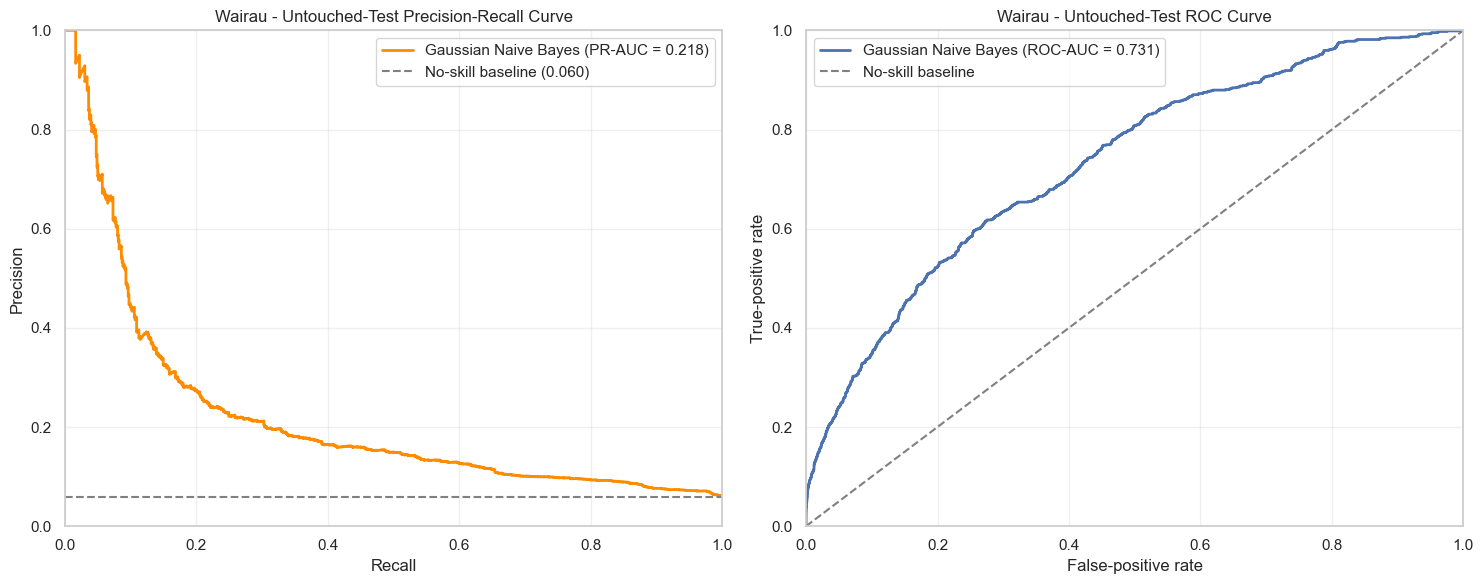

In [34]:
# Plot test Precision-Recall and ROC curves

from sklearn.metrics import roc_curve

test_precision_curve, test_recall_curve, _ = (
    precision_recall_curve(
        y_test,
        test_probability
    )
)

test_false_positive_rate, test_true_positive_rate, _ = (
    roc_curve(
        y_test,
        test_probability
    )
)

test_prevalence = float(y_test.mean())

fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 6)
)

axes[0].plot(
    test_recall_curve,
    test_precision_curve,
    color="darkorange",
    linewidth=2,
    label=(
        "Gaussian Naive Bayes "
        f"(PR-AUC = "
        f"{average_precision_score(y_test, test_probability):.3f})"
    )
)

axes[0].axhline(
    test_prevalence,
    color="grey",
    linestyle="--",
    label=f"No-skill baseline ({test_prevalence:.3f})"
)

axes[0].set_title(
    "Wairau - Untouched-Test Precision-Recall Curve"
)
axes[0].set_xlabel("Recall")
axes[0].set_ylabel("Precision")
axes[0].set_xlim(0, 1)
axes[0].set_ylim(0, 1)
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    test_false_positive_rate,
    test_true_positive_rate,
    linewidth=2,
    label=(
        "Gaussian Naive Bayes "
        f"(ROC-AUC = "
        f"{roc_auc_score(y_test, test_probability):.3f})"
    )
)

axes[1].plot(
    [0, 1],
    [0, 1],
    color="grey",
    linestyle="--",
    label="No-skill baseline"
)

axes[1].set_title(
    "Wairau - Untouched-Test ROC Curve"
)
axes[1].set_xlabel("False-positive rate")
axes[1].set_ylabel("True-positive rate")
axes[1].set_xlim(0, 1)
axes[1].set_ylim(0, 1)
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [35]:
# Evaluate Naive Bayes advance warnings for physical high-water events

naive_bayes_test_indexed = (
    wairau_naive_bayes_test_predictions
    .set_index("timestamp")
    .sort_index()
)

naive_bayes_physical_event_rows = []

for _, event in wairau_test_physical_events.iterrows():

    event_start = event["episode_start"]
    event_end = event["episode_end"]

    warning_window_start = (
        event_start - pd.Timedelta(hours=24)
    )

    warning_window_end = (
        event_start - pd.Timedelta(hours=1)
    )

    pre_event_predictions = (
        naive_bayes_test_indexed.loc[
            warning_window_start:warning_window_end
        ]
    )

    positive_warnings = pre_event_predictions.loc[
        pre_event_predictions[
            "predicted_high_water_risk_24h"
        ].eq(1)
    ]

    detected_in_advance = not positive_warnings.empty

    if detected_in_advance:

        first_warning = positive_warnings.index.min()
        last_warning = positive_warnings.index.max()

        maximum_lead_time = (
            event_start - first_warning
        ) / pd.Timedelta(hours=1)

        minimum_lead_time = (
            event_start - last_warning
        ) / pd.Timedelta(hours=1)

    else:

        first_warning = pd.NaT
        last_warning = pd.NaT
        maximum_lead_time = np.nan
        minimum_lead_time = np.nan

    event_water_levels = test_water_level_series.loc[
        event_start:event_end
    ]

    naive_bayes_physical_event_rows.append({
        "event_id": int(event["episode_id"]),
        "event_start": event_start,
        "event_end": event_end,
        "exceedance_hours": int(
            event["episode_hours"]
        ),
        "maximum_water_level_m": (
            event_water_levels.max()
        ),
        "detected_in_advance": detected_in_advance,
        "advance_warning_hours": len(
            positive_warnings
        ),
        "first_advance_warning": first_warning,
        "maximum_lead_time_hours": maximum_lead_time,
        "last_advance_warning": last_warning,
        "minimum_lead_time_hours": minimum_lead_time,
        "maximum_pre_event_probability": (
            pre_event_predictions[
                "naive_bayes_score"
            ].max()
            if not pre_event_predictions.empty
            else np.nan
        )
    })

wairau_naive_bayes_event_results = pd.DataFrame(
    naive_bayes_physical_event_rows
)

physical_event_count = len(
    wairau_naive_bayes_event_results
)

detected_event_count = int(
    wairau_naive_bayes_event_results[
        "detected_in_advance"
    ].sum()
)

wairau_naive_bayes_event_summary = pd.DataFrame([{
    "physical_high_water_events": physical_event_count,
    "events_detected_in_advance": detected_event_count,
    "events_missed_in_advance": (
        physical_event_count - detected_event_count
    ),
    "advance_event_recall": (
        detected_event_count / physical_event_count
        if physical_event_count > 0
        else np.nan
    )
}])

print("Naive Bayes physical high-water event summary:")

display(
    wairau_naive_bayes_event_summary
    .style.format({
        "advance_event_recall": "{:.3f}"
    })
)

print("\nNaive Bayes physical event diagnostics:")

display(
    wairau_naive_bayes_event_results
    .style.format({
        "maximum_water_level_m": "{:.3f}",
        "maximum_lead_time_hours": "{:.1f}",
        "minimum_lead_time_hours": "{:.1f}",
        "maximum_pre_event_probability": "{:.4f}"
    })
)

Naive Bayes physical high-water event summary:


,physical_high_water_events,events_detected_in_advance,events_missed_in_advance,advance_event_recall
0,42,40,2,0.952



Naive Bayes physical event diagnostics:


,event_id,event_start,event_end,exceedance_hours,maximum_water_level_m,detected_in_advance,advance_warning_hours,first_advance_warning,maximum_lead_time_hours,last_advance_warning,minimum_lead_time_hours,maximum_pre_event_probability
0,1,2024-05-20 22:00:00,2024-05-21 01:00:00,4,1.733,True,3,2024-05-20 19:00:00,3.0,2024-05-20 21:00:00,1.0,0.0510
1,2,2024-06-14 03:00:00,2024-06-14 05:00:00,3,1.865,True,4,2024-06-13 23:00:00,4.0,2024-06-14 02:00:00,1.0,0.0510
2,3,2024-06-14 12:00:00,2024-06-14 13:00:00,2,1.572,True,13,2024-06-13 23:00:00,13.0,2024-06-14 11:00:00,1.0,0.0510
3,4,2024-06-16 21:00:00,2024-06-17 01:00:00,5,1.620,True,1,2024-06-16 20:00:00,1.0,2024-06-16 20:00:00,1.0,0.0510
4,5,2024-06-23 04:00:00,2024-06-23 05:00:00,2,1.246,True,9,2024-06-22 19:00:00,9.0,2024-06-23 03:00:00,1.0,0.0510
5,6,2024-07-20 04:00:00,2024-07-20 06:00:00,3,1.101,True,11,2024-07-19 11:00:00,17.0,2024-07-20 03:00:00,1.0,0.0510
6,7,2024-08-31 10:00:00,2024-08-31 11:00:00,2,1.090,True,1,2024-08-31 09:00:00,1.0,2024-08-31 09:00:00,1.0,0.0510
7,8,2024-09-01 04:00:00,2024-09-01 05:00:00,2,1.249,True,19,2024-08-31 09:00:00,19.0,2024-09-01 03:00:00,1.0,0.0510
8,9,2024-10-02 22:00:00,2024-10-03 00:00:00,3,1.177,True,3,2024-10-02 11:00:00,11.0,2024-10-02 21:00:00,1.0,0.0510
9,10,2024-10-03 03:00:00,2024-10-03 05:00:00,3,1.555,True,8,2024-10-02 11:00:00,16.0,2024-10-03 02:00:00,1.0,0.0510


In [36]:
# Evaluate Naive Bayes alert episodes

observed_risk_series = (
    naive_bayes_test_indexed[
        "observed_high_water_risk_24h"
    ]
)

predicted_alert_series = (
    naive_bayes_test_indexed[
        "predicted_high_water_risk_24h"
    ]
)

naive_bayes_alert_episodes = identify_binary_episodes(
    predicted_alert_series
)

naive_bayes_alert_rows = []

for _, alert in naive_bayes_alert_episodes.iterrows():

    alert_start = alert["episode_start"]
    alert_end = alert["episode_end"]

    alert_period = naive_bayes_test_indexed.loc[
        alert_start:alert_end
    ]

    actual_risk_hours = int(
        alert_period[
            "observed_high_water_risk_24h"
        ].sum()
    )

    naive_bayes_alert_rows.append({
        "alert_id": int(alert["episode_id"]),
        "alert_start": alert_start,
        "alert_end": alert_end,
        "alert_hours": int(alert["episode_hours"]),
        "actual_risk_hours": actual_risk_hours,
        "maximum_naive_bayes_score": (
            alert_period["naive_bayes_score"].max()
        ),
        "mean_naive_bayes_score": (
            alert_period["naive_bayes_score"].mean()
        ),
        "associated_with_risk": (
            actual_risk_hours > 0
        )
    })

wairau_naive_bayes_alert_results = pd.DataFrame(
    naive_bayes_alert_rows
)

total_alert_episodes = len(
    wairau_naive_bayes_alert_results
)

risk_associated_alerts = int(
    wairau_naive_bayes_alert_results[
        "associated_with_risk"
    ].sum()
)

false_alert_episodes = (
    total_alert_episodes - risk_associated_alerts
)

alert_episode_precision = (
    risk_associated_alerts / total_alert_episodes
    if total_alert_episodes > 0
    else np.nan
)

print(
    "Total predicted alert episodes:",
    total_alert_episodes
)

print(
    "Risk-associated alert episodes:",
    risk_associated_alerts
)

print(
    "False alert episodes:",
    false_alert_episodes
)

print(
    "Alert-episode precision:",
    f"{alert_episode_precision:.3f}"
)

display(
    wairau_naive_bayes_alert_results
    .style.format({
        "maximum_naive_bayes_score": "{:.6f}",
        "mean_naive_bayes_score": "{:.6f}"
    })
)

Total predicted alert episodes: 216
Risk-associated alert episodes: 48
False alert episodes: 168
Alert-episode precision: 0.222


,alert_id,alert_start,alert_end,alert_hours,actual_risk_hours,maximum_naive_bayes_score,mean_naive_bayes_score,associated_with_risk
0,1,2024-05-15 01:00:00,2024-05-15 02:00:00,2,0,0.050967,0.050967,False
1,2,2024-05-15 05:00:00,2024-05-15 19:00:00,15,0,0.050967,0.050967,False
2,3,2024-05-16 08:00:00,2024-05-16 12:00:00,5,0,0.050967,0.050967,False
3,4,2024-05-20 19:00:00,2024-05-21 21:00:00,27,6,0.050968,0.050967,True
4,5,2024-05-24 16:00:00,2024-05-24 17:00:00,2,0,0.050967,0.050967,False
5,6,2024-05-24 21:00:00,2024-05-24 22:00:00,2,0,0.050967,0.050967,False
6,7,2024-05-25 03:00:00,2024-05-25 04:00:00,2,0,0.050967,0.050967,False
7,8,2024-05-25 08:00:00,2024-05-25 12:00:00,5,0,0.050967,0.050967,False
8,9,2024-05-27 11:00:00,2024-05-27 20:00:00,10,0,0.050967,0.050967,False
9,10,2024-05-28 20:00:00,2024-05-30 13:00:00,42,0,0.050967,0.050967,False


In [37]:
# Compare Naive Bayes training and test performance

def calculate_naive_bayes_metrics(
    actual,
    predicted,
    probability
):
    return {
        "Accuracy": accuracy_score(
            actual,
            predicted
        ),
        "Balanced accuracy": balanced_accuracy_score(
            actual,
            predicted
        ),
        "Precision": precision_score(
            actual,
            predicted,
            zero_division=0
        ),
        "Recall": recall_score(
            actual,
            predicted,
            zero_division=0
        ),
        "F1": f1_score(
            actual,
            predicted,
            zero_division=0
        ),
        "F2": fbeta_score(
            actual,
            predicted,
            beta=2,
            zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            actual,
            probability
        ),
        "PR-AUC": average_precision_score(
            actual,
            probability
        )
    }


training_metrics = calculate_naive_bayes_metrics(
    y_train,
    training_prediction,
    training_probability
)

test_metrics = calculate_naive_bayes_metrics(
    y_test,
    test_prediction,
    test_probability
)

naive_bayes_train_test_comparison = pd.DataFrame({
    "Training": training_metrics,
    "Test": test_metrics
})

print(
    "WAIRAU NAIVE BAYES - TRAINING VERSUS TEST PERFORMANCE"
)

display(
    naive_bayes_train_test_comparison
    .style.format("{:.4f}")
)

WAIRAU NAIVE BAYES - TRAINING VERSUS TEST PERFORMANCE


,Training,Test
Accuracy,0.8278,0.8218
Balanced accuracy,0.6527,0.6508
Precision,0.1390,0.1579
Recall,0.4576,0.4565
F1,0.2132,0.2346
F2,0.3137,0.3312
ROC-AUC,0.7347,0.7314
PR-AUC,0.2212,0.2176


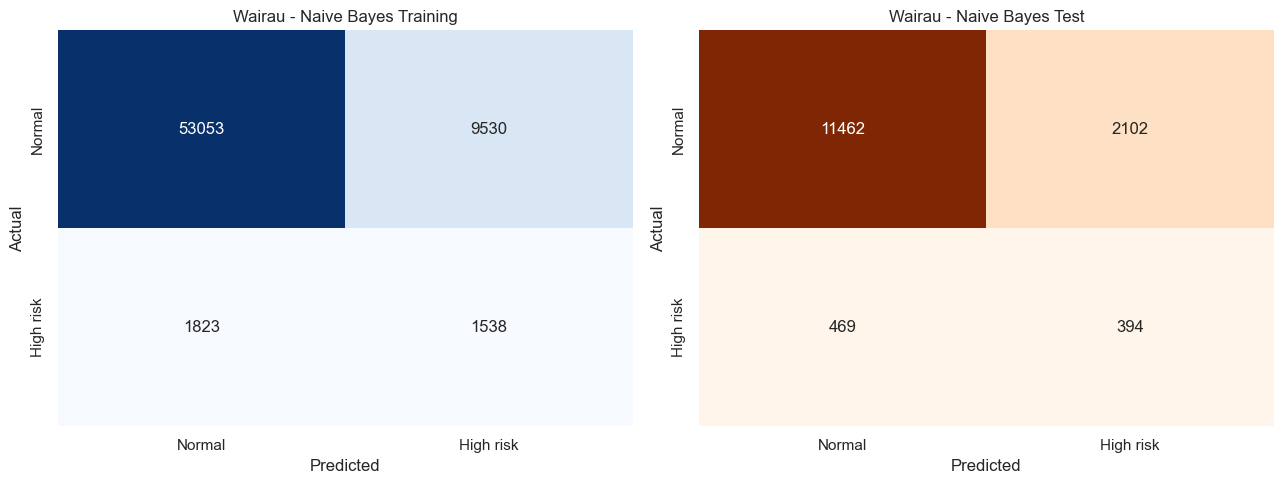

In [38]:
# Plot Naive Bayes training and test confusion matrices

naive_bayes_training_confusion = confusion_matrix(
    y_train,
    training_prediction
)

naive_bayes_test_confusion = confusion_matrix(
    y_test,
    test_prediction
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5)
)

sns.heatmap(
    naive_bayes_training_confusion,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=[
        "Normal",
        "High risk"
    ],
    yticklabels=[
        "Normal",
        "High risk"
    ],
    ax=axes[0]
)

axes[0].set_title(
    "Wairau - Naive Bayes Training"
)
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(
    naive_bayes_test_confusion,
    annot=True,
    fmt="d",
    cmap="Oranges",
    cbar=False,
    xticklabels=[
        "Normal",
        "High risk"
    ],
    yticklabels=[
        "Normal",
        "High risk"
    ],
    ax=axes[1]
)

axes[1].set_title(
    "Wairau - Naive Bayes Test"
)
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [39]:
# Compare all three Wairau models on the test dataset

wairau_models = {
    "Random Forest": (
        wairau_random_forest,
        float(RF_SELECTED_THRESHOLD)
    ),
    "XGBoost": (
        wairau_xgboost,
        float(XGB_SELECTED_THRESHOLD)
    ),
    "Naive Bayes": (
        naive_bayes_model,
        float(selected_probability_threshold)
    )
}

wairau_model_test_rows = []

for model_name, (model, threshold) in wairau_models.items():

    probability = model.predict_proba(
        X_test
    )[:, 1]

    prediction = (
        probability >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        prediction
    ).ravel()

    wairau_model_test_rows.append({
        "Model": model_name,
        "Probability threshold": threshold,
        "Accuracy": accuracy_score(
            y_test,
            prediction
        ),
        "Balanced accuracy": balanced_accuracy_score(
            y_test,
            prediction
        ),
        "Precision": precision_score(
            y_test,
            prediction,
            zero_division=0
        ),
        "Recall": recall_score(
            y_test,
            prediction,
            zero_division=0
        ),
        "F1": f1_score(
            y_test,
            prediction,
            zero_division=0
        ),
        "F2": fbeta_score(
            y_test,
            prediction,
            beta=2,
            zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_test,
            probability
        ),
        "PR-AUC": average_precision_score(
            y_test,
            probability
        ),
        "True positives": tp,
        "False negatives": fn,
        "False positives": fp,
        "True negatives": tn
    })

wairau_three_model_comparison = (
    pd.DataFrame(wairau_model_test_rows)
    .set_index("Model")
)

print("WAIRAU - FINAL TEST MODEL COMPARISON")

display(
    wairau_three_model_comparison
    .style.format({
        "Probability threshold": "{:.6f}",
        "Accuracy": "{:.4f}",
        "Balanced accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "F2": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "PR-AUC": "{:.4f}",
        "True positives": "{:.0f}",
        "False negatives": "{:.0f}",
        "False positives": "{:.0f}",
        "True negatives": "{:.0f}"
    })
)

WAIRAU - FINAL TEST MODEL COMPARISON


,Probability threshold,Accuracy,Balanced accuracy,Precision,Recall,F1,F2,ROC-AUC,PR-AUC,True positives,False negatives,False positives,True negatives
Model,,,,,,,,,,,,,
Random Forest,0.068000,0.7783,0.6179,0.1218,0.4357,0.1903,0.2875,0.6792,0.1915,376,487,2712,10852
XGBoost,0.512950,0.8189,0.6346,0.1477,0.4253,0.2193,0.3091,0.7139,0.2223,367,496,2117,11447
Naive Bayes,0.050967,0.8218,0.6508,0.1579,0.4565,0.2346,0.3312,0.7314,0.2176,394,469,2102,11462


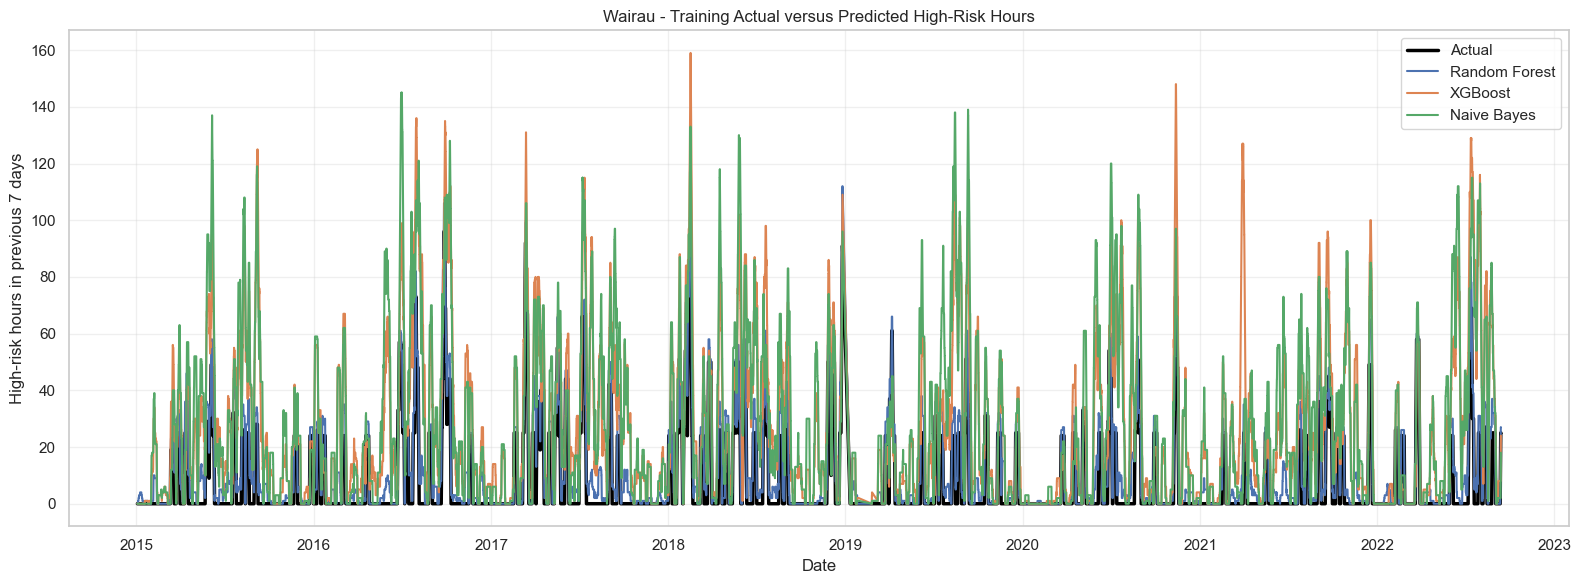

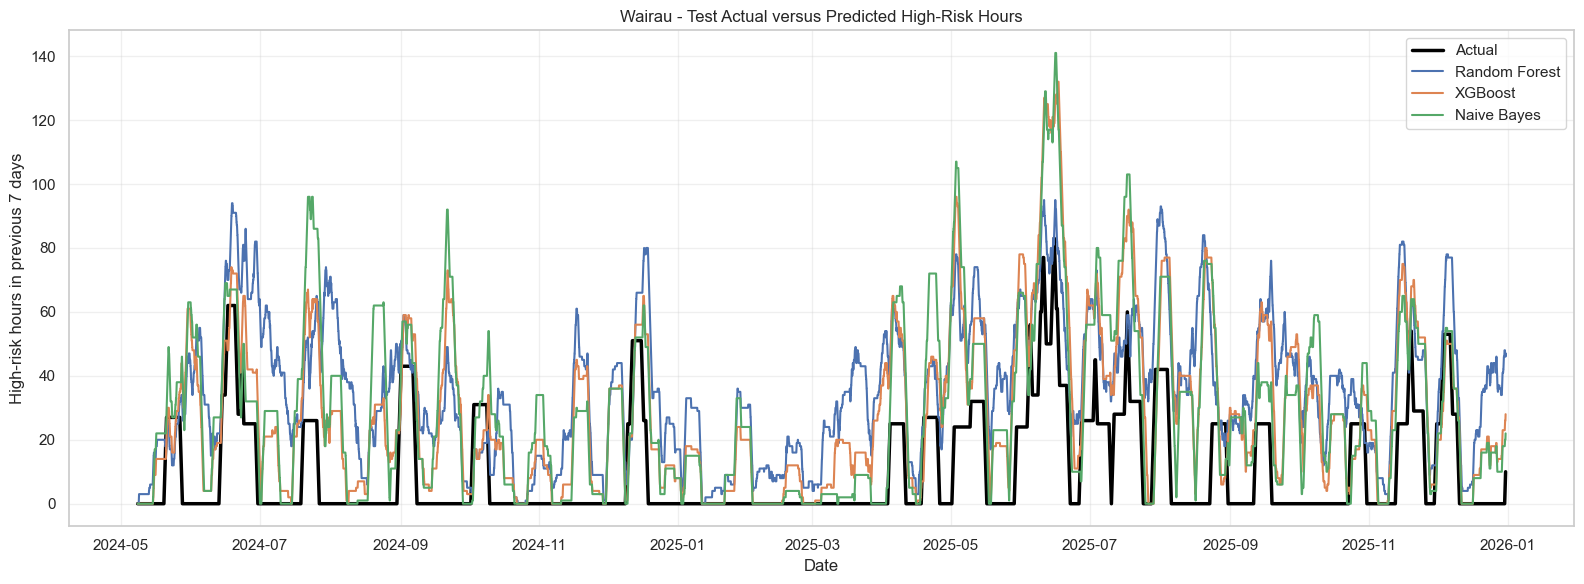

In [40]:
# Create actual-versus-predicted line graphs for all three models

train_model_predictions = pd.DataFrame(
    index=pd.to_datetime(training_timestamps)
)

train_model_predictions["Actual"] = (
    y_train.to_numpy(dtype=int)
)

test_model_predictions = pd.DataFrame(
    index=pd.to_datetime(test_timestamps)
)

test_model_predictions["Actual"] = (
    y_test.to_numpy(dtype=int)
)

for model_name, (model, threshold) in wairau_models.items():

    training_model_probability = (
        model.predict_proba(X_train)[:, 1]
    )

    test_model_probability = (
        model.predict_proba(X_test)[:, 1]
    )

    train_model_predictions[model_name] = (
        training_model_probability >= threshold
    ).astype(int)

    test_model_predictions[model_name] = (
        test_model_probability >= threshold
    ).astype(int)


# Convert hourly classifications into rolling weekly totals

train_weekly_results = (
    train_model_predictions
    .rolling("168h", min_periods=1)
    .sum()
)

test_weekly_results = (
    test_model_predictions
    .rolling("168h", min_periods=1)
    .sum()
)


# Training graph

plt.figure(figsize=(16, 6))

plt.plot(
    train_weekly_results.index,
    train_weekly_results["Actual"],
    label="Actual",
    linewidth=2.5,
    color="black"
)

plt.plot(
    train_weekly_results.index,
    train_weekly_results["Random Forest"],
    label="Random Forest",
    linewidth=1.5
)

plt.plot(
    train_weekly_results.index,
    train_weekly_results["XGBoost"],
    label="XGBoost",
    linewidth=1.5
)

plt.plot(
    train_weekly_results.index,
    train_weekly_results["Naive Bayes"],
    label="Naive Bayes",
    linewidth=1.5
)

plt.title(
    "Wairau - Training Actual versus Predicted High-Risk Hours"
)
plt.xlabel("Date")
plt.ylabel("High-risk hours in previous 7 days")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# Test graph

plt.figure(figsize=(16, 6))

plt.plot(
    test_weekly_results.index,
    test_weekly_results["Actual"],
    label="Actual",
    linewidth=2.5,
    color="black"
)

plt.plot(
    test_weekly_results.index,
    test_weekly_results["Random Forest"],
    label="Random Forest",
    linewidth=1.5
)

plt.plot(
    test_weekly_results.index,
    test_weekly_results["XGBoost"],
    label="XGBoost",
    linewidth=1.5
)

plt.plot(
    test_weekly_results.index,
    test_weekly_results["Naive Bayes"],
    label="Naive Bayes",
    linewidth=1.5
)

plt.title(
    "Wairau - Test Actual versus Predicted High-Risk Hours"
)
plt.xlabel("Date")
plt.ylabel("High-risk hours in previous 7 days")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

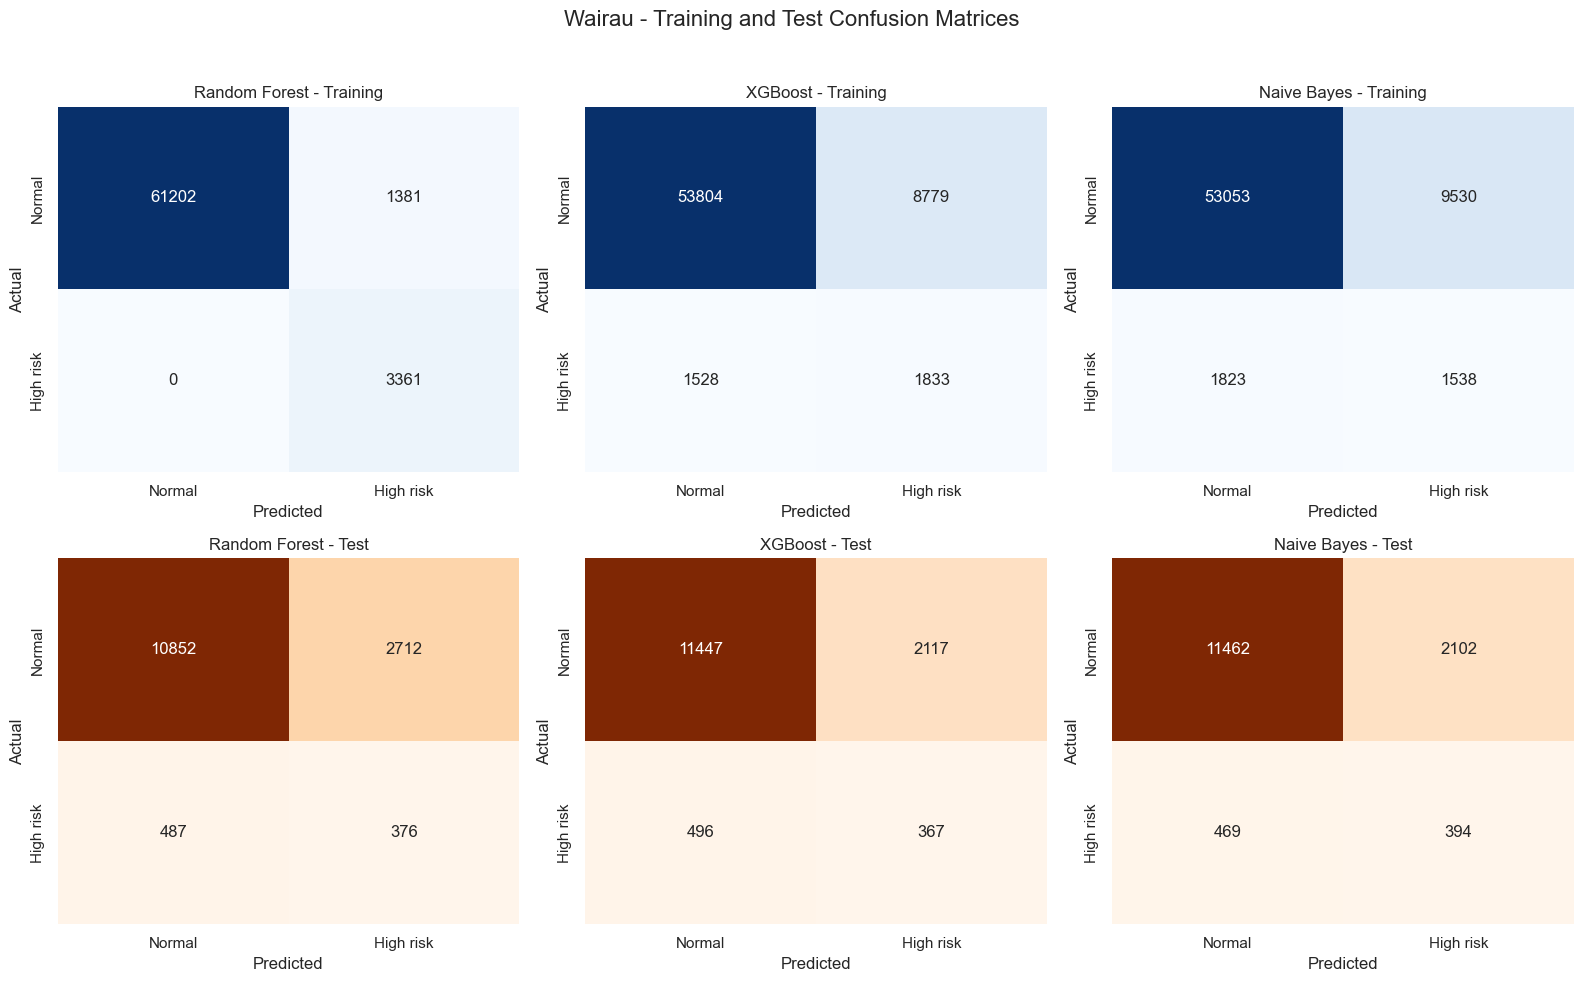

In [41]:
# Compare training and test confusion matrices for all three models

model_names = [
    "Random Forest",
    "XGBoost",
    "Naive Bayes"
]

fig, axes = plt.subplots(
    2,
    3,
    figsize=(16, 10)
)

for column_position, model_name in enumerate(model_names):

    training_confusion = confusion_matrix(
        train_model_predictions["Actual"],
        train_model_predictions[model_name]
    )

    test_confusion = confusion_matrix(
        test_model_predictions["Actual"],
        test_model_predictions[model_name]
    )

    sns.heatmap(
        training_confusion,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=[
            "Normal",
            "High risk"
        ],
        yticklabels=[
            "Normal",
            "High risk"
        ],
        ax=axes[0, column_position]
    )

    axes[0, column_position].set_title(
        f"{model_name} - Training"
    )

    axes[0, column_position].set_xlabel(
        "Predicted"
    )

    axes[0, column_position].set_ylabel(
        "Actual"
    )

    sns.heatmap(
        test_confusion,
        annot=True,
        fmt="d",
        cmap="Oranges",
        cbar=False,
        xticklabels=[
            "Normal",
            "High risk"
        ],
        yticklabels=[
            "Normal",
            "High risk"
        ],
        ax=axes[1, column_position]
    )

    axes[1, column_position].set_title(
        f"{model_name} - Test"
    )

    axes[1, column_position].set_xlabel(
        "Predicted"
    )

    axes[1, column_position].set_ylabel(
        "Actual"
    )

fig.suptitle(
    "Wairau - Training and Test Confusion Matrices",
    fontsize=16
)

plt.tight_layout(
    rect=[0, 0, 1, 0.96]
)

plt.show()

In [42]:
# Save Wairau Naive Bayes and model-comparison outputs

import joblib

naive_bayes_output_files = {
    "wairau_naive_bayes_tuning_results.csv":
        naive_bayes_tuning_results,

    "wairau_naive_bayes_validation_results.csv":
        naive_bayes_validation_results,

    "wairau_naive_bayes_test_results.csv":
        naive_bayes_test_results,

    "wairau_naive_bayes_test_predictions.csv":
        wairau_naive_bayes_test_predictions,

    "wairau_naive_bayes_event_results.csv":
        wairau_naive_bayes_event_results,

    "wairau_naive_bayes_event_summary.csv":
        wairau_naive_bayes_event_summary,

    "wairau_naive_bayes_alert_results.csv":
        wairau_naive_bayes_alert_results,

    "wairau_naive_bayes_train_test_comparison.csv":
        naive_bayes_train_test_comparison,

    "wairau_three_model_test_comparison.csv":
        wairau_three_model_comparison.reset_index(),

    "wairau_training_model_predictions.csv":
        train_model_predictions.reset_index(
            names="timestamp"
        ),

    "wairau_test_model_predictions.csv":
        test_model_predictions.reset_index(
            names="timestamp"
        )
}

for filename, dataframe in naive_bayes_output_files.items():

    dataframe.to_csv(
        wairau_output_directory / filename,
        index=False
    )


joblib.dump(
    naive_bayes_model,
    wairau_output_directory
    / "wairau_naive_bayes_model.joblib"
)

print(
    "Wairau Naive Bayes and comparison outputs saved to:"
)

print(wairau_output_directory)

print("\nSaved files:")

for filename in naive_bayes_output_files:
    print("-", filename)

print("- wairau_naive_bayes_model.joblib")

Wairau Naive Bayes and comparison outputs saved to:
C:\Users\kgeet\Downloads\Wairau_Model_Outputs

Saved files:
- wairau_naive_bayes_tuning_results.csv
- wairau_naive_bayes_validation_results.csv
- wairau_naive_bayes_test_results.csv
- wairau_naive_bayes_test_predictions.csv
- wairau_naive_bayes_event_results.csv
- wairau_naive_bayes_event_summary.csv
- wairau_naive_bayes_alert_results.csv
- wairau_naive_bayes_train_test_comparison.csv
- wairau_three_model_test_comparison.csv
- wairau_training_model_predictions.csv
- wairau_test_model_predictions.csv
- wairau_naive_bayes_model.joblib
